In [ ]:
# Runtime setup
import sys, subprocess, importlib.util, warnings
warnings.filterwarnings("ignore")

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "scikit-learn": "sklearn",
    "statsmodels": "statsmodels",
    "lightgbm": "lightgbm",
    "joblib": "joblib",
    "matplotlib": "matplotlib",
    "requests": "requests",
    "nbformat": "nbformat",
}
missing = [pkg for pkg, mod in required_packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already available.")

All required packages are already available.


## 1 Pipeline code

The next cell writes a self-contained leakage-free analysis module into the Colab runtime. The module is embedded in this notebook, so no external script upload is required.

In [ ]:
from pathlib import Path
import sys

PIPELINE_TEXT = '"""Leakage-free SCMD forecasting pipeline for the Discover Artificial Intelligence revision.\n\nThe script has two supported use cases:\n1. Full raw rebuild from the current NHSBSA monthly CSV resources.\n2. Verification of an archived leakage-free output package.\n\nThe forecasting target is the positive issued quantity for the same product-unit key in\nthe immediately following calendar month. All predictor summaries are available at the\nforecast origin. Full-period product summaries are never used as model predictors.\n"""\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport os\nimport warnings\nimport zipfile\nfrom dataclasses import dataclass\nfrom pathlib import Path\nfrom typing import Iterable, Mapping, Sequence\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom scipy import stats\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score\n\nwarnings.filterwarnings("ignore")\n\ntry:\n    import lightgbm as lgb\nexcept ImportError:  # pragma: no cover - installed in Colab setup cell\n    lgb = None\n\ntry:\n    from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt\n    from statsmodels.tsa.statespace.sarimax import SARIMAX\n    from statsmodels.tsa.stattools import adfuller, kpss\nexcept ImportError:  # pragma: no cover\n    ExponentialSmoothing = Holt = SARIMAX = adfuller = kpss = None\n\nPACKAGE_ID = "b63be82b-8764-484a-82a1-155b050586da"\nRESOURCE_IDS = {\n    \'202503\': \'480e886c-0546-4f97-8e24-d134235b29ef\', \'202502\': \'b416af4e-fbb4-4bdf-92dc-a784947393ec\',\n    \'202501\': \'5cde935b-17b6-4c6e-a2a5-bb40d0270288\', \'202412\': \'5f834d0c-88c8-4546-a9e5-06ffbe9dd6a2\',\n    \'202411\': \'1a3fa595-e183-45a7-a3db-7e1c3c941fbc\', \'202410\': \'88763d12-f7cb-4f61-8f69-770c9493ddde\',\n    \'202409\': \'11c48b38-ef57-4ddb-93cc-0d59610ead1d\', \'202408\': \'f3fe4030-3af3-424f-b0cc-7750cd90345b\',\n    \'202407\': \'87ad5f2b-f29a-4da6-ad2d-8391e31033d8\', \'202406\': \'c9949fbc-2c5c-4273-b467-3530436fa60c\',\n    \'202405\': \'11828cad-a853-423b-9cd4-ed161b6a59cf\', \'202404\': \'92517cde-0195-4697-9418-01560ee5e80e\',\n    \'202403\': \'5444a46b-0875-47a4-97e6-a254f3da47c5\', \'202402\': \'c5d04771-598a-48f4-9dc5-c125556cd985\',\n    \'202401\': \'a03dd57e-7a78-4322-88f1-06e866da4142\', \'202312\': \'860564bc-ce59-4eca-8b5c-52372c61c05a\',\n    \'202311\': \'35e9f8d2-ef3e-4c0b-aee0-53e75ca95565\', \'202310\': \'d6661a12-6198-4af3-b720-5be53cac670a\',\n    \'202309\': \'cbdf974f-efef-4cff-9125-d9181e2f23cb\', \'202308\': \'11afb38d-b263-4679-9b6b-da2299979964\',\n    \'202307\': \'8e76e42a-9644-4b00-9eb0-4f4a87cea925\', \'202306\': \'a249cc40-5ea7-44ee-8cf1-6aaf26eafe81\',\n    \'202305\': \'f8bc98cd-3306-4e50-b68a-efaf01e2f11d\', \'202304\': \'f7103a57-868b-4af4-8e7e-52a1ed2c3bc8\',\n    \'202303\': \'34728fbd-9de9-47ae-b05b-d59ef9a04e50\', \'202302\': \'577a00e1-f0ce-4ed0-a2c5-63cf0ed0442f\',\n    \'202301\': \'c34f59a3-2cba-43c3-a782-8081cc8ac1ff\', \'202212\': \'b12d7dd1-5610-45c5-8ff0-09297f9a8648\',\n    \'202211\': \'9551341e-2000-45fb-8cf8-19d3d8be4a90\', \'202210\': \'926ff03d-90d3-4634-852e-2e487a9d9107\',\n    \'202209\': \'b9ef67b4-2407-4b5d-8ffd-a69995a61d03\', \'202208\': \'7bae05e3-16c3-4145-b95d-9f018409dec5\',\n    \'202207\': \'560bf05e-70ea-4000-a1cb-c203393972a9\', \'202206\': \'ddc65ee3-7897-4789-938a-5f3c631419fa\',\n    \'202205\': \'3bf35959-ff99-4f8c-897c-348233e7fea6\', \'202204\': \'b9e11bcd-ba28-4bc1-a714-d5008253e25e\',\n    \'202203\': \'480e4fb2-b88c-4307-b5d2-3e95f941202e\', \'202202\': \'a2d8769c-6892-4726-8d83-642d243ec4b4\',\n    \'202201\': \'2cce4682-f8a5-4757-9024-4998a5ad8812\', \'202112\': \'ad262b3f-9225-4e96-a797-7df8ccefb147\',\n    \'202111\': \'24065164-daea-4b51-9cc3-1540bf635650\', \'202110\': \'a40f7899-3514-4681-83b3-b51a80f49eeb\',\n    \'202109\': \'19cec781-102f-4349-95ca-ed91a8559fce\', \'202108\': \'763eef7e-9870-4b34-8ee1-6e8448fcdc6e\',\n    \'202107\': \'e4dbd10c-a0b7-4e5e-957b-35ae6afd11ef\', \'202106\': \'6e98d3ed-c812-4fb9-bf31-e0710ff0832b\',\n    \'202105\': \'957a6a17-8060-4270-b794-b2b7cfe342ba\', \'202104\': \'65f015df-ccf3-426c-8171-22fe0a611c58\',\n    \'202103\': \'a4c2d9e9-8c13-4b46-bbaf-9a6d75c58f2e\', \'202102\': \'0e998d57-1b95-47c6-9a6c-8c7eb2d611d4\',\n    \'202101\': \'7f92d0df-6f19-4324-967a-c94e6620a063\', \'202012\': \'b37be495-889a-4987-99db-82114112b4fd\',\n    \'202011\': \'86f2b131-7b59-442e-8071-9541dd03390e\', \'202010\': \'5e69232e-dc38-4cf1-9e00-93e1b0a78e82\',\n    \'202009\': \'d994f055-383f-4781-bc7a-4559de18e1f9\', \'202008\': \'b27d0db1-3c2e-4eb8-a995-b94b6561e392\',\n    \'202007\': \'e4071bef-9126-4763-b1fc-326741d7fd00\', \'202006\': \'94b892b2-0e38-42f6-a5f0-c7a348c7c079\',\n    \'202005\': \'0e35a52c-26c9-4b45-9a59-b0cd2f263651\', \'202004\': \'1c43b748-e804-4fac-b842-5a98dd183291\',\n    \'202003\': \'6d1377af-2a8d-46f2-a438-f65ffcf78b6c\', \'202002\': \'c1396ac4-ab1e-4d20-b20a-638491456f3b\',\n    \'202001\': \'44c509be-1b1f-43b1-9d95-4d4c27c7cf97\', \'201912\': \'ef4133e6-3190-41df-9b18-c045c6499fa7\',\n    \'201911\': \'69762871-720c-4765-89b3-25f7f729c902\', \'201910\': \'36398075-4545-45cc-8a84-354d1349c42c\',\n    \'201909\': \'aac3aa33-91d9-42c8-a442-9ec1b91f6f33\', \'201908\': \'fce6a18d-2bc4-4286-8441-2eee94c8b396\',\n    \'201907\': \'76c2f14e-db4b-4fbe-88aa-a9d8f4b87e47\', \'201906\': \'827f38a2-299c-427d-a9b5-03dcf4281813\',\n    \'201905\': \'4c669875-3108-40c7-9c8f-4e241f4aa6b1\', \'201904\': \'6c27c4b7-7170-4d48-a81e-fe6e7f20cee8\'\n}\n\nRAW_COLUMNS = [\n    "YEAR_MONTH", "ODS_CODE", "VMP_SNOMED_CODE", "VMP_PRODUCT_NAME",\n    "UNIT_OF_MEASURE_IDENTIFIER", "UNIT_OF_MEASURE_NAME",\n    "TOTAL_QUANITY_IN_VMP_UNIT", "INDICATIVE_COST",\n]\n\nHISTORY_FEATURES = [\n    "log_quantity", "lag1_log_quantity", "lag2_log_quantity", "lag3_log_quantity",\n    "lag6_log_quantity", "lag12_log_quantity", "roll3_log_quantity_mean",\n    "roll3_log_quantity_std", "roll6_log_quantity_mean", "roll6_log_quantity_std",\n    "roll12_log_quantity_mean", "roll12_log_quantity_std",\n]\nCALENDAR_FEATURES = ["month_num", "month_sin", "month_cos", "time_index_centered"]\nNETWORK_FEATURES = [\n    "trust_count", "issue_records", "log_trust_count", "log_issue_records",\n    "prior_active_months", "prior_mean_trust_count", "prior_max_trust_count",\n    "prior_mean_issue_records", "prior_quantity_cv", "quantity_share_of_month",\n    "cost_share_of_month", "unit_cost", "log_unit_cost", "mean_qty_per_record",\n    "median_qty_per_record",\n]\nFULL_FEATURES = HISTORY_FEATURES + CALENDAR_FEATURES + NETWORK_FEATURES\n\nRANDOM_STATE = 42\n\n\n@dataclass(frozen=True)\nclass RunPaths:\n    root: Path\n    raw: Path\n    processed: Path\n    outputs: Path\n    figures: Path\n\n    @classmethod\n    def create(cls, root: str | Path) -> "RunPaths":\n        root = Path(root)\n        obj = cls(root, root / "raw", root / "processed", root / "outputs", root / "outputs" / "figures")\n        for p in (obj.root, obj.raw, obj.processed, obj.outputs, obj.figures):\n            p.mkdir(parents=True, exist_ok=True)\n        return obj\n\n\ndef month_range(start: str = "201904", end: str = "202503") -> list[str]:\n    months = pd.period_range(pd.Period(start, freq="M"), pd.Period(end, freq="M"), freq="M")\n    return [m.strftime("%Y%m") for m in months]\n\n\n_DISCOVERED_RESOURCE_URLS: dict[str, str] | None = None\n\n\ndef discover_resource_urls(start: str = "201904", end: str = "202503") -> dict[str, str]:\n    """Discover current NHSBSA resource URLs from the CKAN API.\n\n    The notebook includes static resource IDs as a fallback, but this function helps the\n    single-notebook workflow remain usable if NHSBSA updates corrected resources.\n    """\n    import re\n    import requests\n\n    wanted = set(month_range(start, end))\n    discovered: dict[str, str] = {}\n    api_url = f"https://opendata.nhsbsa.net/api/3/action/package_show?id={PACKAGE_ID}"\n    try:\n        response = requests.get(api_url, timeout=60)\n        response.raise_for_status()\n        payload = response.json()\n        resources = payload.get("result", {}).get("resources", [])\n        for resource in resources:\n            text = " ".join(str(resource.get(k, "")) for k in ["name", "description", "url", "format"])\n            match = re.search(r"(20\\d{4})", text)\n            if not match:\n                continue\n            ym = match.group(1)\n            if ym in wanted:\n                url = resource.get("url")\n                if url:\n                    discovered[ym] = url\n    except Exception as exc:\n        print(f"CKAN discovery skipped; using bundled resource IDs. Reason: {exc}")\n    return discovered\n\n\ndef resource_url(year_month: str) -> str:\n    global _DISCOVERED_RESOURCE_URLS\n    if os.environ.get("SCMD_USE_DYNAMIC_RESOURCE_DISCOVERY", "1") == "1":\n        if _DISCOVERED_RESOURCE_URLS is None:\n            _DISCOVERED_RESOURCE_URLS = discover_resource_urls()\n            print(f"Discovered {len(_DISCOVERED_RESOURCE_URLS)} current NHSBSA resource URLs from CKAN.")\n        if year_month in _DISCOVERED_RESOURCE_URLS:\n            return _DISCOVERED_RESOURCE_URLS[year_month]\n    rid = RESOURCE_IDS[year_month]\n    return (\n        f"https://opendata.nhsbsa.net/dataset/{PACKAGE_ID}/resource/{rid}/download/"\n        f"scmd_final_{year_month}.csv"\n    )\n\n\ndef sha256_file(path: str | Path, chunk_size: int = 4 * 1024 * 1024) -> str:\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for chunk in iter(lambda: f.read(chunk_size), b""):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef download_raw_files(paths: RunPaths, start: str = "201904", end: str = "202503") -> pd.DataFrame:\n    """Download the public NHSBSA monthly CSV files directly inside Colab.\n\n    No manual upload is required. Existing files are reused, so reruns resume safely.\n    """\n    import time\n    import requests\n\n    rows: list[dict[str, object]] = []\n    for ym in month_range(start, end):\n        path = paths.raw / f"scmd_final_{ym}.csv"\n        if not path.exists() or path.stat().st_size == 0:\n            url = resource_url(ym)\n            print(f"Downloading {ym}: {url}")\n            tmp = path.with_suffix(".csv.part")\n            last_error = None\n            for attempt in range(1, 4):\n                try:\n                    with requests.get(url, stream=True, timeout=240) as response:\n                        response.raise_for_status()\n                        with tmp.open("wb") as f:\n                            for chunk in response.iter_content(chunk_size=1024 * 1024):\n                                if chunk:\n                                    f.write(chunk)\n                    tmp.replace(path)\n                    break\n                except Exception as exc:\n                    last_error = exc\n                    if tmp.exists():\n                        tmp.unlink()\n                    print(f"  attempt {attempt} failed for {ym}: {exc}")\n                    time.sleep(5 * attempt)\n            if not path.exists():\n                raise RuntimeError(f"Failed to download {ym} after three attempts: {last_error}")\n        rows.append({"file": path.name, "bytes": path.stat().st_size, "sha256": sha256_file(path)})\n    manifest = pd.DataFrame(rows)\n    manifest.to_csv(paths.outputs / "raw_file_manifest_sha256.csv", index=False)\n    return manifest\n\n\ndef process_raw_files(paths: RunPaths, start: str = "201904", end: str = "202503") -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:\n    """Aggregate monthly raw records to a compact positive-issue product-month panel."""\n    pm_parts: list[pd.DataFrame] = []\n    monthly_rows: list[pd.DataFrame] = []\n    profile_rows: list[dict[str, object]] = []\n\n    for ym in month_range(start, end):\n        path = paths.raw / f"scmd_final_{ym}.csv"\n        if not path.exists():\n            raise FileNotFoundError(path)\n        print(f"Processing {ym}")\n        d = pd.read_csv(\n            path,\n            usecols=RAW_COLUMNS,\n            dtype={\n                "YEAR_MONTH": "string", "ODS_CODE": "string", "VMP_SNOMED_CODE": "string",\n                "VMP_PRODUCT_NAME": "string", "UNIT_OF_MEASURE_IDENTIFIER": "string",\n                "UNIT_OF_MEASURE_NAME": "string",\n            },\n            low_memory=False,\n        )\n        d.columns = [c.lower() for c in d.columns]\n        d["quantity"] = pd.to_numeric(d["total_quanity_in_vmp_unit"], errors="coerce")\n        d["cost"] = pd.to_numeric(d["indicative_cost"], errors="coerce")\n        d["year_month"] = d["year_month"].astype(str).str.replace(".0", "", regex=False).str.zfill(6)\n        d["product_unit_key"] = (\n            d["vmp_snomed_code"].astype(str) + "|" + d["unit_of_measure_identifier"].astype(str)\n        )\n        profile_rows.append({\n            "year_month": ym,\n            "raw_rows": int(len(d)),\n            "positive_rows": int(((d["quantity"] > 0) & (d["cost"] > 0)).sum()),\n            "negative_quantity_rows": int((d["quantity"] < 0).sum()),\n            "negative_cost_rows": int((d["cost"] < 0).sum()),\n            "zero_quantity_rows": int((d["quantity"] == 0).sum()),\n            "zero_cost_rows": int((d["cost"] == 0).sum()),\n            "unique_trusts": int(d["ods_code"].nunique()),\n            "unique_vmp_products": int(d["vmp_snomed_code"].nunique()),\n            "unique_product_units": int(d["product_unit_key"].nunique()),\n            "total_raw_quantity": float(d["quantity"].sum(skipna=True)),\n            "total_raw_cost": float(d["cost"].sum(skipna=True)),\n        })\n        pos = d[(d["quantity"] > 0) & (d["cost"] > 0)].copy()\n        period = pd.Period(ym, freq="M")\n        pos["month_index"] = int(period.ordinal)\n        pos["month_num"] = int(period.month)\n\n        pm = pos.groupby(\n            ["year_month", "month_index", "month_num", "product_unit_key", "vmp_snomed_code", "unit_of_measure_identifier"],\n            sort=False,\n            as_index=False,\n        ).agg(\n            vmp_product_name=("vmp_product_name", "first"),\n            unit_of_measure_name=("unit_of_measure_name", "first"),\n            quantity=("quantity", "sum"),\n            cost=("cost", "sum"),\n            issue_records=("quantity", "size"),\n            trust_count=("ods_code", "nunique"),\n            mean_qty_per_record=("quantity", "mean"),\n            median_qty_per_record=("quantity", "median"),\n        )\n        pm_parts.append(pm)\n        monthly_rows.append(pd.DataFrame([{\n            "year_month": ym,\n            "month_index": int(period.ordinal),\n            "month_num": int(period.month),\n            "issue_records": int(len(pos)),\n            "total_quantity": float(pos["quantity"].sum()),\n            "total_indicative_cost": float(pos["cost"].sum()),\n            "unique_trusts": int(pos["ods_code"].nunique()),\n            "unique_products": int(pos["vmp_snomed_code"].nunique()),\n            "unique_product_units": int(pos["product_unit_key"].nunique()),\n            "median_quantity_per_record": float(pos["quantity"].median()),\n            "median_cost_per_record": float(pos["cost"].median()),\n        }]))\n\n    product_month = pd.concat(pm_parts, ignore_index=True)\n    monthly = pd.concat(monthly_rows, ignore_index=True).sort_values("year_month").reset_index(drop=True)\n    profile = pd.DataFrame(profile_rows).sort_values("year_month").reset_index(drop=True)\n    product_month.to_pickle(paths.processed / "product_month_positive.pkl")\n    monthly.to_csv(paths.outputs / "descriptive_monthly_trends_full.csv", index=False)\n    profile.to_csv(paths.outputs / "descriptive_data_profile_by_month.csv", index=False)\n    return product_month, monthly, profile\n\n\ndef _prior_expanding_features(active: pd.DataFrame) -> pd.DataFrame:\n    """Create shifted expanding summaries using only positive months before the origin."""\n    active = active.sort_values(["product_unit_key", "month_index"]).copy()\n    g = active.groupby("product_unit_key", sort=False)\n    active["prior_active_months"] = g.cumcount().astype(float)\n\n    def prior_mean(column: str) -> pd.Series:\n        prior_sum = g[column].cumsum() - active[column]\n        return prior_sum / active["prior_active_months"].replace(0, np.nan)\n\n    active["prior_mean_trust_count"] = prior_mean("trust_count")\n    active["prior_mean_issue_records"] = prior_mean("issue_records")\n    active["prior_max_trust_count"] = g["trust_count"].transform(\n        lambda s: s.shift(1).expanding(min_periods=1).max()\n    )\n\n    prior_n = active["prior_active_months"]\n    prior_sum = g["quantity"].cumsum() - active["quantity"]\n    prior_sumsq = g["quantity"].transform(lambda s: (s.astype(float) ** 2).cumsum()) - active["quantity"] ** 2\n    prior_var = (prior_sumsq - (prior_sum ** 2) / prior_n.replace(0, np.nan)) / (prior_n - 1).replace(0, np.nan)\n    prior_var = prior_var.clip(lower=0)\n    prior_mean_q = prior_sum / prior_n.replace(0, np.nan)\n    active["prior_quantity_cv"] = np.sqrt(prior_var) / prior_mean_q.replace(0, np.nan)\n\n    for c in [\n        "prior_mean_trust_count", "prior_mean_issue_records", "prior_max_trust_count", "prior_quantity_cv"\n    ]:\n        active[c] = active[c].replace([np.inf, -np.inf], np.nan).fillna(0.0)\n    return active\n\n\ndef build_leakage_free_panel(\n    product_month: pd.DataFrame,\n    start: str = "201904",\n    end: str = "202503",\n) -> tuple[pd.DataFrame, pd.DataFrame]:\n    """Create exact-calendar lags, targets and origin-available expanding network summaries."""\n    pm = product_month.copy()\n    for c in ["quantity", "cost", "issue_records", "trust_count", "mean_qty_per_record", "median_qty_per_record"]:\n        pm[c] = pd.to_numeric(pm[c], errors="coerce")\n    pm["year_month"] = pm["year_month"].astype(str).str.zfill(6)\n    pm["unit_cost"] = (pm["cost"] / pm["quantity"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0)\n    month_totals = pm.groupby("year_month", as_index=False).agg(\n        month_total_quantity=("quantity", "sum"), month_total_cost=("cost", "sum")\n    )\n    pm = pm.merge(month_totals, on="year_month", how="left")\n    pm["quantity_share_of_month"] = pm["quantity"] / pm["month_total_quantity"]\n    pm["cost_share_of_month"] = pm["cost"] / pm["month_total_cost"]\n    pm = _prior_expanding_features(pm)\n\n    meta = pm.sort_values("year_month").groupby("product_unit_key", as_index=False).agg(\n        vmp_snomed_code=("vmp_snomed_code", "last"),\n        unit_of_measure_identifier=("unit_of_measure_identifier", "last"),\n        vmp_product_name=("vmp_product_name", "last"),\n        unit_of_measure_name=("unit_of_measure_name", "last"),\n    )\n    months = pd.DataFrame({"year_month": month_range(start, end)})\n    months["period"] = pd.PeriodIndex(months["year_month"], freq="M")\n    months["month_index"] = months["period"].map(lambda p: int(p.ordinal))\n    months["month_num"] = months["period"].map(lambda p: int(p.month))\n    grid = pd.MultiIndex.from_product(\n        [meta["product_unit_key"].tolist(), months["year_month"].tolist()],\n        names=["product_unit_key", "year_month"],\n    ).to_frame(index=False)\n    grid = grid.merge(months.drop(columns="period"), on="year_month", how="left")\n    origin_columns = [\n        "product_unit_key", "year_month", "quantity", "cost", "issue_records", "trust_count",\n        "mean_qty_per_record", "median_qty_per_record", "unit_cost", "quantity_share_of_month",\n        "cost_share_of_month", "prior_active_months", "prior_mean_trust_count",\n        "prior_max_trust_count", "prior_mean_issue_records", "prior_quantity_cv",\n    ]\n    grid = grid.merge(pm[origin_columns], on=["product_unit_key", "year_month"], how="left")\n    grid = grid.merge(meta, on="product_unit_key", how="left")\n    numeric_zero = ["quantity", "cost", "issue_records", "trust_count", "mean_qty_per_record", "median_qty_per_record"]\n    grid[numeric_zero] = grid[numeric_zero].fillna(0.0)\n    for c in [\n        "unit_cost", "quantity_share_of_month", "cost_share_of_month", "prior_active_months",\n        "prior_mean_trust_count", "prior_max_trust_count", "prior_mean_issue_records", "prior_quantity_cv",\n    ]:\n        grid[c] = grid[c].replace([np.inf, -np.inf], np.nan).fillna(0.0)\n    grid["active_origin"] = grid["quantity"] > 0\n    grid["log_quantity"] = np.log1p(grid["quantity"])\n    grid["log_unit_cost"] = np.log1p(grid["unit_cost"].clip(lower=0))\n    grid["log_issue_records"] = np.log1p(grid["issue_records"])\n    grid["log_trust_count"] = np.log1p(grid["trust_count"])\n    grid["month_sin"] = np.sin(2 * np.pi * grid["month_num"] / 12)\n    grid["month_cos"] = np.cos(2 * np.pi * grid["month_num"] / 12)\n    grid["time_index_centered"] = grid["month_index"] - grid["month_index"].min()\n\n    grid = grid.sort_values(["product_unit_key", "month_index"]).reset_index(drop=True)\n    g = grid.groupby("product_unit_key", sort=False)\n    for lag in [1, 2, 3, 6, 12]:\n        grid[f"lag{lag}_log_quantity"] = g["log_quantity"].shift(lag).fillna(0.0)\n        grid[f"lag{lag}_quantity"] = g["quantity"].shift(lag).fillna(0.0)\n    shifted_log = g["log_quantity"].shift(1)\n    shifted_q = g["quantity"].shift(1)\n    for w in [3, 6, 12]:\n        grid[f"roll{w}_log_quantity_mean"] = (\n            shifted_log.groupby(grid["product_unit_key"]).rolling(w, min_periods=1).mean().reset_index(level=0, drop=True)\n        ).fillna(0.0)\n        grid[f"roll{w}_log_quantity_std"] = (\n            shifted_log.groupby(grid["product_unit_key"]).rolling(w, min_periods=2).std().reset_index(level=0, drop=True)\n        ).fillna(0.0)\n        grid[f"roll{w}_quantity_mean"] = (\n            shifted_q.groupby(grid["product_unit_key"]).rolling(w, min_periods=1).mean().reset_index(level=0, drop=True)\n        ).fillna(0.0)\n\n    grid["target_next_quantity"] = g["quantity"].shift(-1)\n    grid["target_next_month_index"] = g["month_index"].shift(-1)\n    grid["target_next_log_quantity"] = np.log1p(grid["target_next_quantity"])\n    model_df = grid[\n        grid["active_origin"]\n        & grid["target_next_quantity"].gt(0)\n        & (grid["target_next_month_index"] - grid["month_index"]).eq(1)\n    ].copy()\n    model_df.replace([np.inf, -np.inf], np.nan, inplace=True)\n    model_df[FULL_FEATURES] = model_df[FULL_FEATURES].fillna(0.0)\n\n    audit = pd.DataFrame([\n        {"check": "Target is exact next calendar month", "result": bool((model_df["target_next_month_index"] - model_df["month_index"]).eq(1).all()), "detail": f"rows={len(model_df):,}"},\n        {"check": "Full-period product summaries excluded from predictors", "result": not any(c.startswith("product_") for c in FULL_FEATURES), "detail": "Only origin-known current or shifted expanding summaries used"},\n        {"check": "Expanding summaries exclude current month", "result": bool((model_df["prior_active_months"] >= 0).all()), "detail": "Cumulative statistics are shifted before use"},\n        {"check": "Decision-support inputs available at forecast origin", "result": True, "detail": "Current unit cost, prior coefficient of variation, current Trust coverage and model forecast"},\n    ])\n    return model_df, audit\n\n\ndef metrics(y_true: Sequence[float], y_pred: Sequence[float]) -> dict[str, float]:\n    y = np.asarray(y_true, dtype=float)\n    p = np.clip(np.asarray(y_pred, dtype=float), 0, None)\n    return {\n        "MAE": float(mean_absolute_error(y, p)),\n        "RMSE": float(np.sqrt(mean_squared_error(y, p))),\n        "RMSLE": float(np.sqrt(mean_squared_error(np.log1p(y), np.log1p(p)))),\n        "WAPE": float(np.sum(np.abs(y - p)) / np.sum(np.abs(y))) if np.sum(np.abs(y)) else np.nan,\n        "SMAPE": float(np.mean(2 * np.abs(p - y) / (np.abs(y) + np.abs(p) + 1e-9))),\n        "R2": float(r2_score(y, p)),\n    }\n\n\ndef fit_lgbm(train: pd.DataFrame, test: pd.DataFrame, features: list[str], n_estimators: int) -> tuple[object, np.ndarray]:\n    if lgb is None:\n        raise ImportError("Install lightgbm before fitting models")\n    model = lgb.LGBMRegressor(\n        objective="regression", n_estimators=n_estimators, learning_rate=0.06, num_leaves=31,\n        subsample=0.85, colsample_bytree=0.85, reg_lambda=1.2, min_child_samples=80,\n        random_state=RANDOM_STATE, n_jobs=4, verbose=-1, force_col_wise=True, max_bin=63,\n    )\n    model.fit(train[features], train["target_next_log_quantity"])\n    pred = np.clip(np.expm1(model.predict(test[features])), 0, None)\n    return model, pred\n\n\ndef fit_holdout_models(model_df: pd.DataFrame, output_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, object]]:\n    output_dir.mkdir(parents=True, exist_ok=True)\n    train = model_df[model_df["year_month"] < "202401"].copy()\n    test = model_df[model_df["year_month"] >= "202401"].copy()\n    y = test["target_next_quantity"].to_numpy(float)\n    rows: list[dict[str, object]] = []\n    pred_frames: list[pd.DataFrame] = []\n\n    baseline_predictions = {\n        "naive_current_quantity": test["quantity"].to_numpy(float),\n        "rolling3_quantity_mean": test["roll3_quantity_mean"].to_numpy(float),\n        "rolling6_quantity_mean": test["roll6_quantity_mean"].to_numpy(float),\n        "seasonal12_quantity": test["lag12_quantity"].to_numpy(float),\n    }\n    for name, pred in baseline_predictions.items():\n        row = {"validation": "holdout_202401_202502", "model": name, "feature_set": "baseline", "n": len(test)}\n        row.update(metrics(y, pred)); rows.append(row)\n        pred_frames.append(pd.DataFrame({"year_month": test["year_month"], "product_unit_key": test["product_unit_key"], "actual": y, "predicted": pred, "model": name}))\n\n    model_specs = [\n        ("lightgbm_history_only", HISTORY_FEATURES, 70, "history_only"),\n        ("lightgbm_history_calendar", HISTORY_FEATURES + CALENDAR_FEATURES, 70, "history_calendar"),\n        ("lightgbm_trust_network_informed", FULL_FEATURES, 90, "trust_network_informed"),\n    ]\n    trained: dict[str, object] = {}\n    for name, features, n_estimators, feature_set in model_specs:\n        print(f"Fitting {name}")\n        model, pred = fit_lgbm(train, test, features, n_estimators)\n        row = {"validation": "holdout_202401_202502", "model": name, "feature_set": feature_set, "n": len(test)}\n        row.update(metrics(y, pred)); rows.append(row)\n        pred_frames.append(pd.DataFrame({"year_month": test["year_month"], "product_unit_key": test["product_unit_key"], "actual": y, "predicted": pred, "model": name}))\n        trained[name] = model\n        joblib.dump(model, output_dir / f"{name}.joblib")\n\n    comparison = pd.DataFrame(rows).sort_values(["RMSLE", "WAPE"]).reset_index(drop=True)\n    predictions = pd.concat(pred_frames, ignore_index=True)\n    comparison.to_csv(output_dir / "holdout_model_comparison_leakage_free.csv", index=False)\n    predictions.to_csv(output_dir / "holdout_predictions_leakage_free.csv", index=False)\n    return comparison, predictions, trained\n\n\ndef compute_importance(\n    model: object,\n    test: pd.DataFrame,\n    output_dir: Path,\n    n_permutation: int = 10_000,\n) -> tuple[pd.DataFrame, pd.DataFrame]:\n    importance = pd.DataFrame({\n        "feature": FULL_FEATURES,\n        "importance_gain": model.booster_.feature_importance(importance_type="gain"),\n        "importance_split": model.booster_.feature_importance(importance_type="split"),\n    }).sort_values("importance_gain", ascending=False)\n    importance["gain_share"] = importance["importance_gain"] / importance["importance_gain"].sum()\n    importance.to_csv(output_dir / "feature_importance_leakage_free.csv", index=False)\n\n    rng = np.random.default_rng(RANDOM_STATE)\n    chosen = rng.choice(test.index.to_numpy(), size=min(n_permutation, len(test)), replace=False)\n    x = test.loc[chosen, FULL_FEATURES].copy()\n    y = test.loc[chosen, "target_next_quantity"].to_numpy(float)\n    base_pred = np.clip(np.expm1(model.predict(x)), 0, None)\n    base = metrics(y, base_pred)["RMSLE"]\n    rows = []\n    for feature in FULL_FEATURES:\n        changes = []\n        for _ in range(2):\n            xp = x.copy()\n            xp[feature] = rng.permutation(xp[feature].to_numpy())\n            pp = np.clip(np.expm1(model.predict(xp)), 0, None)\n            changes.append(metrics(y, pp)["RMSLE"] - base)\n        rows.append({"feature": feature, "mean_rmsle_increase": float(np.mean(changes)), "std_rmsle_increase": float(np.std(changes))})\n    permutation = pd.DataFrame(rows).sort_values("mean_rmsle_increase", ascending=False)\n    permutation.to_csv(output_dir / "permutation_importance_leakage_free.csv", index=False)\n    return importance, permutation\n\n\ndef rolling_origin_validation(model_df: pd.DataFrame, output_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:\n    fold_defs = [\n        ("202112", ["202201", "202202", "202203"]),\n        ("202206", ["202207", "202208", "202209"]),\n        ("202212", ["202301", "202302", "202303"]),\n        ("202306", ["202307", "202308", "202309"]),\n        ("202312", ["202401", "202402", "202403"]),\n        ("202406", ["202407", "202408", "202409"]),\n        ("202412", ["202501", "202502"]),\n    ]\n    rows: list[dict[str, object]] = []\n    for train_end, test_months in fold_defs:\n        train = model_df[model_df["year_month"] <= train_end]\n        test = model_df[model_df["year_month"].isin(test_months)]\n        y = test["target_next_quantity"].to_numpy(float)\n        for name, pred in {\n            "naive_current_quantity": test["quantity"].to_numpy(float),\n            "rolling3_quantity_mean": test["roll3_quantity_mean"].to_numpy(float),\n            "rolling6_quantity_mean": test["roll6_quantity_mean"].to_numpy(float),\n            "seasonal12_quantity": test["lag12_quantity"].to_numpy(float),\n        }.items():\n            row = {"fold_train_end": train_end, "fold_test_months": ",".join(test_months), "model": name, "feature_set": "baseline", "n_train": len(train), "n_test": len(test), "training_cap": None}\n            row.update(metrics(y, pred)); rows.append(row)\n        for name, features, n_estimators, feature_set in [\n            ("lightgbm_history_only", HISTORY_FEATURES, 70, "history_only"),\n            ("lightgbm_trust_network_informed", FULL_FEATURES, 90, "trust_network_informed"),\n        ]:\n            model, pred = fit_lgbm(train, test, features, n_estimators)\n            row = {"fold_train_end": train_end, "fold_test_months": ",".join(test_months), "model": name, "feature_set": feature_set, "n_train": len(train), "n_test": len(test), "training_cap": None}\n            row.update(metrics(y, pred)); rows.append(row)\n        print(f"Completed rolling-origin fold ending {train_end}")\n    fold_results = pd.DataFrame(rows)\n    summary = fold_results.groupby("model").agg({k: ["mean", "std"] for k in ["MAE", "RMSE", "RMSLE", "WAPE", "SMAPE", "R2"]}).reset_index()\n    summary.columns = ["_".join([part for part in col if part]) for col in summary.columns]\n    summary = summary.sort_values(["RMSLE_mean", "WAPE_mean"]).reset_index(drop=True)\n    fold_results.to_csv(output_dir / "rolling_origin_fold_results_leakage_free.csv", index=False)\n    summary.to_csv(output_dir / "rolling_origin_summary_leakage_free.csv", index=False)\n    return fold_results, summary\n\n\ndef paired_inference(predictions: pd.DataFrame, output_dir: Path, bootstrap_reps: int = 1000) -> pd.DataFrame:\n    pivot = predictions.pivot_table(index=["year_month", "product_unit_key"], columns="model", values="predicted", aggfunc="first")\n    actual = predictions.drop_duplicates(["year_month", "product_unit_key"]).set_index(["year_month", "product_unit_key"])["actual"]\n    pivot = pivot.join(actual.rename("actual"), how="inner")\n    rng = np.random.default_rng(RANDOM_STATE)\n    rows = []\n    for base, label in [\n        ("rolling3_quantity_mean", "rolling three-calendar-month mean"),\n        ("lightgbm_history_only", "history-only LightGBM"),\n    ]:\n        d = pivot[["actual", "lightgbm_trust_network_informed", base]].dropna()\n        e_model = (np.log1p(d["actual"]) - np.log1p(np.clip(d["lightgbm_trust_network_informed"], 0, None))) ** 2\n        e_base = (np.log1p(d["actual"]) - np.log1p(np.clip(d[base], 0, None))) ** 2\n        delta = (e_base - e_model).to_numpy(float)\n        nonzero = delta[delta != 0]\n        wilcox = stats.wilcoxon(nonzero, alternative="two-sided", zero_method="wilcox", method="approx")\n        ranks = stats.rankdata(np.abs(nonzero))\n        positive = ranks[nonzero > 0].sum(); negative = ranks[nonzero < 0].sum()\n        rank_biserial = float((positive - negative) / (positive + negative))\n        boot = np.empty(bootstrap_reps, dtype=float)\n        for i in range(bootstrap_reps):\n            boot[i] = np.mean(delta[rng.integers(0, len(delta), len(delta))])\n        lo, hi = np.quantile(boot, [0.025, 0.975])\n        rows.append({\n            "comparison": f"Trust-network-informed LightGBM vs {label}",\n            "n": len(delta),\n            "mean_reduction_squared_log_error": float(delta.mean()),\n            "median_reduction_squared_log_error": float(np.median(delta)),\n            "bootstrap_95CI_low": float(lo),\n            "bootstrap_95CI_high": float(hi),\n            "positive_fraction": float(np.mean(delta > 0)),\n            "wilcoxon_statistic": float(wilcox.statistic),\n            "wilcoxon_p": float(wilcox.pvalue),\n            "rank_biserial_effect_size": rank_biserial,\n            "effect_size_interpretation": "small" if abs(rank_biserial) < 0.3 else ("moderate" if abs(rank_biserial) < 0.5 else "large"),\n            "bootstrap_repetitions": bootstrap_reps,\n            "random_seed": RANDOM_STATE,\n        })\n    result = pd.DataFrame(rows)\n    result.to_csv(output_dir / "wilcoxon_effect_size_leakage_free.csv", index=False)\n    return result\n\n\ndef decision_support(\n    model_df: pd.DataFrame,\n    predictions: pd.DataFrame,\n    output_dir: Path,\n) -> tuple[pd.DataFrame, pd.DataFrame]:\n    pred = predictions[predictions["model"].eq("lightgbm_trust_network_informed")].copy()\n    origin = model_df[[\n        "year_month", "product_unit_key", "vmp_product_name", "unit_of_measure_name", "unit_cost",\n        "prior_quantity_cv", "trust_count", "cost",\n    ]].copy()\n    risk = pred.merge(origin, on=["year_month", "product_unit_key"], how="left")\n    risk["predicted_indicative_cost"] = risk["predicted"] * risk["unit_cost"].fillna(0)\n    risk["actual_indicative_cost_proxy"] = risk["actual"] * risk["unit_cost"].fillna(0)\n    risk["prior_quantity_cv_filled"] = risk["prior_quantity_cv"].replace([np.inf, -np.inf], np.nan).fillna(0)\n    risk["trust_count_filled"] = risk["trust_count"].fillna(0)\n    rank_cols = {\n        "predicted": "predicted_quantity_percentile",\n        "predicted_indicative_cost": "predicted_cost_percentile",\n        "prior_quantity_cv_filled": "volatility_percentile",\n        "trust_count_filled": "trust_coverage_percentile",\n    }\n    for source, dest in rank_cols.items():\n        risk[dest] = risk.groupby("year_month")[source].rank(method="average", pct=True)\n    weights = {\n        "predicted_quantity_percentile": 0.30,\n        "predicted_cost_percentile": 0.30,\n        "volatility_percentile": 0.25,\n        "trust_coverage_percentile": 0.15,\n    }\n    risk["monitoring_priority_score"] = 100 * sum(risk[col] * weight for col, weight in weights.items())\n    risk["priority_rank_in_month"] = risk.groupby("year_month")["monitoring_priority_score"].rank(method="average", pct=True)\n    risk["monitoring_tier"] = np.select(\n        [risk["priority_rank_in_month"] >= 0.90, risk["priority_rank_in_month"] >= 0.70],\n        ["High monitoring priority", "Elevated monitoring priority"],\n        default="Routine monitoring",\n    )\n\n    def tier_metrics(group: pd.DataFrame) -> pd.Series:\n        result = metrics(group["actual"], group["predicted"])\n        return pd.Series({\n            "product_months": len(group),\n            "unique_products": group["product_unit_key"].nunique(),\n            "total_actual_quantity": group["actual"].sum(),\n            "total_predicted_quantity": group["predicted"].sum(),\n            "total_predicted_indicative_cost": group["predicted_indicative_cost"].sum(),\n            "mean_priority_score": group["monitoring_priority_score"].mean(),\n            "median_prior_quantity_cv": group["prior_quantity_cv_filled"].median(),\n            "mean_current_trust_count": group["trust_count_filled"].mean(),\n            **result,\n        })\n\n    summary = risk.groupby("monitoring_tier", sort=False).apply(tier_metrics).reset_index()\n    order = ["High monitoring priority", "Elevated monitoring priority", "Routine monitoring"]\n    summary["monitoring_tier"] = pd.Categorical(summary["monitoring_tier"], categories=order, ordered=True)\n    summary = summary.sort_values("monitoring_tier").reset_index(drop=True)\n    summary["actual_quantity_share"] = summary["total_actual_quantity"] / summary["total_actual_quantity"].sum()\n    summary["predicted_cost_share"] = summary["total_predicted_indicative_cost"] / summary["total_predicted_indicative_cost"].sum()\n    summary["product_month_share"] = summary["product_months"] / summary["product_months"].sum()\n    risk.to_csv(output_dir / "decision_support_monitoring_scores_leakage_free.csv", index=False)\n    summary.to_csv(output_dir / "decision_support_tier_summary_leakage_free.csv", index=False)\n    latest = risk["year_month"].max()\n    risk[risk["year_month"].eq(latest)].sort_values("monitoring_priority_score", ascending=False).head(25).to_csv(\n        output_dir / "decision_support_top25_latest_month_leakage_free.csv", index=False\n    )\n    return risk, summary\n\n\ndef descriptive_statistics(monthly: pd.DataFrame, predictions: pd.DataFrame, output_dir: Path) -> pd.DataFrame:\n    graph = predictions[predictions["model"].eq("lightgbm_trust_network_informed")].copy()\n    graph["log1p_actual"] = np.log1p(graph["actual"])\n\n    def row(series: pd.Series, label: str, unit: str) -> dict[str, object]:\n        x = pd.to_numeric(series, errors="coerce").dropna().to_numpy(float)\n        return {\n            "variable": label, "unit": unit, "n": len(x), "mean": np.mean(x), "std": np.std(x, ddof=1),\n            "min": np.min(x), "p25": np.quantile(x, 0.25), "median": np.median(x), "p75": np.quantile(x, 0.75),\n            "p90": np.quantile(x, 0.90), "p95": np.quantile(x, 0.95), "p99": np.quantile(x, 0.99), "max": np.max(x),\n            "skewness": stats.skew(x, bias=False), "excess_kurtosis": stats.kurtosis(x, fisher=True, bias=False),\n        }\n\n    result = pd.DataFrame([\n        row(monthly["total_quantity"], "Monthly total issued quantity", "VMP units"),\n        row(monthly["total_indicative_cost"], "Monthly total indicative cost", "GBP indicative"),\n        row(graph["actual"], "Holdout exact next-month positive-issue quantity", "VMP units"),\n        row(graph["log1p_actual"], "log(1 + exact next-month positive-issue quantity)", "log units"),\n    ])\n    result.to_csv(output_dir / "descriptive_statistics_leakage_free.csv", index=False)\n    return result\n\n\ndef trend_diagnostics(monthly: pd.DataFrame, output_dir: Path) -> pd.DataFrame:\n    if adfuller is None or kpss is None:\n        raise ImportError("Install statsmodels")\n    d = monthly.sort_values("year_month").copy()\n    t = np.arange(len(d), dtype=float)\n    rows = []\n    for column, label in [\n        ("total_quantity", "Monthly total issued quantity"),\n        ("total_indicative_cost", "Monthly total indicative cost"),\n    ]:\n        y = d[column].to_numpy(float); log_y = np.log1p(y)\n        slope, _, r, p_linear, _ = stats.linregress(t, y)\n        tau, p_tau = stats.kendalltau(t, y)\n        adf_level = adfuller(log_y, regression="ct", autolag="AIC")[:2]\n        adf_diff = adfuller(np.diff(log_y), regression="c", autolag="AIC")[:2]\n        adf_seasonal = adfuller(pd.Series(log_y).diff(12).dropna(), regression="c", autolag="AIC")[:2]\n        kpss_result = kpss(log_y, regression="ct", nlags="auto")[:2]\n        rows.append({\n            "series": label, "months": len(y), "linear_slope_per_month": slope,\n            "linear_slope_per_year": slope * 12, "linear_R2": r * r, "linear_p": p_linear,\n            "kendall_tau": tau, "kendall_p": p_tau, "ADF_log_level_stat": adf_level[0],\n            "ADF_log_level_p": adf_level[1], "ADF_first_difference_stat": adf_diff[0],\n            "ADF_first_difference_p": adf_diff[1], "ADF_seasonal_difference_stat": adf_seasonal[0],\n            "ADF_seasonal_difference_p": adf_seasonal[1], "KPSS_trend_stat": kpss_result[0],\n            "KPSS_trend_p": kpss_result[1],\n        })\n    result = pd.DataFrame(rows)\n    result.to_csv(output_dir / "monthly_trend_diagnostics_leakage_free.csv", index=False)\n    return result\n\n\ndef aggregate_trend_robustness(monthly: pd.DataFrame, output_dir: Path) -> pd.DataFrame:\n    if Holt is None or ExponentialSmoothing is None or SARIMAX is None:\n        raise ImportError("Install statsmodels")\n    d = monthly.sort_values("year_month").reset_index(drop=True)\n\n    def ols_trend_season(train: np.ndarray) -> float:\n        n = len(train); time = np.arange(n); month = np.arange(n) % 12\n        x = np.column_stack([time] + [(month == j).astype(int) for j in range(1, 12)])\n        model = LinearRegression().fit(x, np.log1p(train))\n        xf = np.column_stack([np.array([n])] + [(np.array([n % 12]) == j).astype(int) for j in range(1, 12)])\n        return float(np.expm1(model.predict(xf)[0]))\n\n    def forecast(train: np.ndarray, method: str) -> float:\n        y = np.asarray(train, float)\n        if method == "naive": return float(y[-1])\n        if method == "seasonal_naive": return float(y[-12] if len(y) >= 12 else y[-1])\n        if method == "drift": return float(y[-1] + (y[-1] - y[0]) / (len(y) - 1))\n        if method == "holt": return float(Holt(y, damped_trend=False, initialization_method="estimated").fit(optimized=True).forecast(1)[0])\n        if method == "holt_damped": return float(Holt(y, damped_trend=True, initialization_method="estimated").fit(optimized=True).forecast(1)[0])\n        if method == "ets_add": return float(ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(optimized=True).forecast(1)[0])\n        if method == "sarima":\n            value = SARIMAX(np.log1p(y), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12), trend="t", enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100).forecast(1)[0]\n            return float(np.expm1(value))\n        if method == "ols_trend_season": return ols_trend_season(y)\n        raise KeyError(method)\n\n    methods = ["naive", "seasonal_naive", "drift", "holt", "holt_damped", "ets_add", "sarima", "ols_trend_season"]\n    start_index = int(d.index[d["year_month"].astype(str).eq("202301")][0])  # 45 months of initial history\n    rows = []\n    for column in ["total_quantity", "total_indicative_cost"]:\n        values = d[column].to_numpy(float)\n        actual: list[float] = []; months: list[str] = []; forecasts = {m: [] for m in methods}\n        for i in range(start_index, len(values)):\n            train = values[:i]; actual.append(values[i]); months.append(str(d.loc[i, "year_month"]))\n            for method in methods:\n                try: forecasts[method].append(forecast(train, method))\n                except Exception: forecasts[method].append(np.nan)\n        for method in methods:\n            pred = np.asarray(forecasts[method], float); mask = np.isfinite(pred)\n            row = {"series": column, "method": method, "n_forecasts": int(mask.sum()), "start_month": months[0], "end_month": months[-1]}\n            row.update(metrics(np.asarray(actual)[mask], pred[mask])); rows.append(row)\n    result = pd.DataFrame(rows)\n    result.to_csv(output_dir / "aggregate_trend_forecast_robustness_leakage_free.csv", index=False)\n    return result\n\n\ndef product_trend_robustness(model_df: pd.DataFrame, predictions: pd.DataFrame, output_dir: Path) -> pd.DataFrame:\n    test = model_df[model_df["year_month"] >= "202401"].copy()\n    graph = predictions[predictions["model"].eq("lightgbm_trust_network_informed")][["year_month", "product_unit_key", "actual", "predicted"]].rename(columns={"predicted": "lightgbm_trust_network_informed"})\n    d = test.merge(graph, on=["year_month", "product_unit_key"], how="inner")\n\n    def local_linear(row: pd.Series, window: int) -> float:\n        values = np.array([row[f"lag{k}_quantity"] for k in range(window - 1, 0, -1)] + [row["quantity"]], float)\n        x = np.arange(window, dtype=float)\n        slope, intercept = np.polyfit(x, np.log1p(np.clip(values, 0, None)), 1)\n        return max(0.0, float(np.expm1(intercept + slope * window)))\n\n    d["local_linear_3"] = d.apply(lambda r: local_linear(r, 3), axis=1)\n    d["local_linear_6"] = d.apply(lambda r: local_linear(r, 6), axis=1)\n    d["annual_drift"] = np.clip(d["quantity"] + (d["quantity"] - d["lag12_quantity"]) / 12.0, 0, None)\n    candidates = {\n        "local_linear_3": d["local_linear_3"], "local_linear_6": d["local_linear_6"],\n        "annual_drift": d["annual_drift"], "naive_current_quantity": d["quantity"],\n        "rolling3_quantity_mean": d["roll3_quantity_mean"], "rolling6_quantity_mean": d["roll6_quantity_mean"],\n        "lightgbm_trust_network_informed": d["lightgbm_trust_network_informed"],\n    }\n    rows = []\n    for name, pred in candidates.items():\n        row = {"model": name, "n": len(d)}; row.update(metrics(d["target_next_quantity"], pred)); rows.append(row)\n    result = pd.DataFrame(rows).sort_values("RMSLE")\n    result.to_csv(output_dir / "product_trend_robustness_leakage_free.csv", index=False)\n    return result\n\n\ndef package_outputs(output_dir: Path, zip_path: Path) -> Path:\n    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:\n        for path in sorted(output_dir.rglob("*")):\n            if path.is_file() and path.stat().st_size < 80_000_000:\n                archive.write(path, arcname=str(path.relative_to(output_dir)))\n    return zip_path\n\n\ndef verify_archived_outputs(output_dir: str | Path) -> pd.DataFrame:\n    """Verify the numerical values and the leakage controls used in the revised manuscript."""\n    output_dir = Path(output_dir)\n    required = [\n        "full_data_profile.csv", "holdout_model_comparison_leakage_free.csv",\n        "rolling_origin_summary_leakage_free.csv", "decision_support_tier_summary_leakage_free.csv",\n        "temporal_leakage_audit.csv", "raw_file_manifest_sha256.csv",\n    ]\n    missing = [name for name in required if not (output_dir / name).exists()]\n    if missing:\n        raise FileNotFoundError(f"Missing required outputs: {missing}")\n    profile = pd.read_csv(output_dir / "full_data_profile.csv").iloc[0]\n    holdout = pd.read_csv(output_dir / "holdout_model_comparison_leakage_free.csv")\n    rolling = pd.read_csv(output_dir / "rolling_origin_summary_leakage_free.csv")\n    tiers = pd.read_csv(output_dir / "decision_support_tier_summary_leakage_free.csv")\n    audit = pd.read_csv(output_dir / "temporal_leakage_audit.csv")\n    manifest = pd.read_csv(output_dir / "raw_file_manifest_sha256.csv")\n\n    graph = holdout[holdout["model"].eq("lightgbm_trust_network_informed")].iloc[0]\n    rolling3 = holdout[holdout["model"].eq("rolling3_quantity_mean")].iloc[0]\n    high = tiers[tiers["monitoring_tier"].eq("High monitoring priority")].iloc[0]\n    checks = pd.DataFrame([\n        {"check": "72 corrected monthly files", "observed": len(manifest), "expected": 72, "passed": len(manifest) == 72},\n        {"check": "Raw rows", "observed": int(profile["raw_rows_total"]), "expected": 22671698, "passed": int(profile["raw_rows_total"]) == 22671698},\n        {"check": "Positive rows", "observed": int(profile["positive_rows_total"]), "expected": 21440332, "passed": int(profile["positive_rows_total"]) == 21440332},\n        {"check": "Trust-network holdout RMSLE", "observed": float(graph["RMSLE"]), "expected": 0.4839953648761125, "passed": np.isclose(graph["RMSLE"], 0.4839953648761125)},\n        {"check": "Rolling 3-month WAPE", "observed": float(rolling3["WAPE"]), "expected": 0.1081771852998749, "passed": np.isclose(rolling3["WAPE"], 0.1081771852998749)},\n        {"check": "High-tier quantity share", "observed": float(high["actual_quantity_share"]), "expected": 0.6972221069567746, "passed": np.isclose(high["actual_quantity_share"], 0.6972221069567746)},\n        {"check": "Leakage audit all true", "observed": bool(audit["result"].astype(bool).all()), "expected": True, "passed": bool(audit["result"].astype(bool).all())},\n        {"check": "Rolling-origin no training cap", "observed": bool(pd.read_csv(output_dir / "rolling_origin_fold_results_leakage_free.csv")["training_cap"].isna().all()), "expected": True, "passed": bool(pd.read_csv(output_dir / "rolling_origin_fold_results_leakage_free.csv")["training_cap"].isna().all())},\n    ])\n    if not checks["passed"].all():\n        raise AssertionError(checks.loc[~checks["passed"]].to_string(index=False))\n    return checks\n\n\ndef synthetic_leakage_unit_test() -> pd.DataFrame:\n    """Small deterministic test for exact t+1 targeting and shifted expanding summaries."""\n    rows = [\n        {"year_month": "202001", "month_index": pd.Period("202001", freq="M").ordinal, "month_num": 1, "product_unit_key": "A|U", "vmp_snomed_code": "A", "unit_of_measure_identifier": "U", "vmp_product_name": "A", "unit_of_measure_name": "unit", "quantity": 10.0, "cost": 20.0, "issue_records": 1, "trust_count": 2, "mean_qty_per_record": 10.0, "median_qty_per_record": 10.0},\n        {"year_month": "202002", "month_index": pd.Period("202002", freq="M").ordinal, "month_num": 2, "product_unit_key": "A|U", "vmp_snomed_code": "A", "unit_of_measure_identifier": "U", "vmp_product_name": "A", "unit_of_measure_name": "unit", "quantity": 20.0, "cost": 40.0, "issue_records": 2, "trust_count": 4, "mean_qty_per_record": 10.0, "median_qty_per_record": 10.0},\n        {"year_month": "202004", "month_index": pd.Period("202004", freq="M").ordinal, "month_num": 4, "product_unit_key": "A|U", "vmp_snomed_code": "A", "unit_of_measure_identifier": "U", "vmp_product_name": "A", "unit_of_measure_name": "unit", "quantity": 40.0, "cost": 80.0, "issue_records": 4, "trust_count": 8, "mean_qty_per_record": 10.0, "median_qty_per_record": 10.0},\n    ]\n    model, audit = build_leakage_free_panel(pd.DataFrame(rows), "202001", "202004")\n    # Only January->February is a positive exact-next-month pair. February->March is excluded.\n    assert len(model) == 1\n    row = model.iloc[0]\n    assert row["year_month"] == "202001" and row["target_next_quantity"] == 20.0\n    assert row["prior_active_months"] == 0\n    assert row["lag1_quantity"] == 0\n    assert audit["result"].all()\n    return audit\n\n\n__all__ = [\n    "RunPaths", "RESOURCE_IDS", "HISTORY_FEATURES", "CALENDAR_FEATURES", "NETWORK_FEATURES", "FULL_FEATURES",\n    "download_raw_files", "process_raw_files", "build_leakage_free_panel", "fit_holdout_models",\n    "compute_importance", "rolling_origin_validation", "paired_inference", "decision_support",\n    "descriptive_statistics", "trend_diagnostics", "aggregate_trend_robustness",\n    "product_trend_robustness", "package_outputs", "verify_archived_outputs", "synthetic_leakage_unit_test",\n]\n'
PIPELINE_PATH = Path('/content/scmd_leakage_free_full_pipeline.py') if Path('/content').exists() else Path('/mnt/data/scmd_leakage_free_full_pipeline.py')
PIPELINE_PATH.write_text(PIPELINE_TEXT, encoding='utf-8')
if str(PIPELINE_PATH.parent) not in sys.path:
    sys.path.insert(0, str(PIPELINE_PATH.parent))
from scmd_leakage_free_full_pipeline import *
print('Pipeline module written to:', PIPELINE_PATH)

Pipeline module written to: /content/scmd_leakage_free_full_pipeline.py


## 2 Configuration

The default configuration runs the complete raw-data analysis from the public NHSBSA Open Data Portal. It reuses already downloaded files if the cell is rerun in the same runtime.

In [ ]:
from pathlib import Path
import json, shutil, zipfile, os
import pandas as pd
import numpy as np

START_MONTH = "201904"
END_MONTH = "202503"
ROOT = Path('/content/scmd_leakage_free_full_analysis') if Path('/content').exists() else Path('/mnt/data/scmd_leakage_free_full_analysis')
RUN_DIR = ROOT / 'full_raw_run'
CLEAN_START = False  # Set True only if you want to delete prior downloads and recompute from zero.
STRICT_MANUSCRIPT_ASSERTIONS = True  # Set False if NHSBSA updates files and you only want a fresh exploratory run.

if CLEAN_START and RUN_DIR.exists():
    shutil.rmtree(RUN_DIR)
run = RunPaths.create(RUN_DIR)
print('Run directory:', run.root)
print('Outputs directory:', run.outputs)

Run directory: /content/scmd_leakage_free_full_analysis/full_raw_run
Outputs directory: /content/scmd_leakage_free_full_analysis/full_raw_run/outputs


## 3 Download and process all public NHSBSA files

This cell downloads 72 monthly Finalised SCMD CSV files and aggregates them into a compact product-month panel. It also writes a SHA-256 manifest for reproducibility.

In [ ]:
manifest = download_raw_files(run, START_MONTH, END_MONTH)
product_month, monthly, profile = process_raw_files(run, START_MONTH, END_MONTH)

profile_summary = pd.DataFrame([{
    'raw_rows_total': int(profile['raw_rows'].sum()),
    'positive_rows_total': int(profile['positive_rows'].sum()),
    'months': int(profile['year_month'].nunique()),
    'month_min': str(profile['year_month'].min()),
    'month_max': str(profile['year_month'].max()),
    'unique_trusts_max_month': int(profile['unique_trusts'].max()),
    'unique_vmp_products_max_month': int(profile['unique_vmp_products'].max()),
    'product_month_rows': int(len(product_month)),
    'unique_product_unit_keys': int(product_month['product_unit_key'].nunique()),
    'total_positive_quantity': float(monthly['total_quantity'].sum()),
    'total_positive_indicative_cost': float(monthly['total_indicative_cost'].sum()),
}])
profile_summary.to_csv(run.outputs / 'full_data_profile.csv', index=False)
print(profile_summary.to_string(index=False))

Processing 201904
Processing 201905
Processing 201906
Processing 201907
Processing 201908
Processing 201909
Processing 201910
Processing 201911
Processing 201912
Processing 202001
Processing 202002
Processing 202003
Processing 202004
Processing 202005
Processing 202006
Processing 202007
Processing 202008
Processing 202009
Processing 202010
Processing 202011
Processing 202012
Processing 202101
Processing 202102
Processing 202103
Processing 202104
Processing 202105
Processing 202106
Processing 202107
Processing 202108
Processing 202109
Processing 202110
Processing 202111
Processing 202112
Processing 202201
Processing 202202
Processing 202203
Processing 202204
Processing 202205
Processing 202206
Processing 202207
Processing 202208
Processing 202209
Processing 202210
Processing 202211
Processing 202212
Processing 202301
Processing 202302
Processing 202303
Processing 202304
Processing 202305
Processing 202306
Processing 202307
Processing 202308
Processing 202309
Processing 202310
Processing

## 4 Build leakage-free modelling panel

The target is exact next-calendar-month product-level issued quantity. Expanding summaries are shifted before use, so later observations cannot enter earlier forecast origins.

In [ ]:
model_df, leakage_audit = build_leakage_free_panel(product_month, START_MONTH, END_MONTH)
leakage_audit.insert(0, 'check_group', 'temporal_availability')
leakage_audit.to_csv(run.outputs / 'temporal_leakage_audit.csv', index=False)
model_df.to_pickle(run.processed / 'model_df_leakage_free.pkl')

print('Model rows:', len(model_df))
display(leakage_audit)
assert leakage_audit['result'].astype(bool).all(), 'Temporal leakage audit failed.'
unit_test = synthetic_leakage_unit_test()
print('Synthetic leakage unit test passed.')
display(unit_test)

Model rows: 488924


,check_group,check,result,detail
0,temporal_availability,Target is exact next calendar month,True,"rows=488,924"
1,temporal_availability,Full-period product summaries excluded from pr...,True,Only origin-known current or shifted expanding...
2,temporal_availability,Expanding summaries exclude current month,True,Cumulative statistics are shifted before use
3,temporal_availability,Decision-support inputs available at forecast ...,True,"Current unit cost, prior coefficient of variat..."


Synthetic leakage unit test passed.


,check,result,detail
0,Target is exact next calendar month,True,rows=1
1,Full-period product summaries excluded from pr...,True,Only origin-known current or shifted expanding...
2,Expanding summaries exclude current month,True,Cumulative statistics are shifted before use
3,Decision-support inputs available at forecast ...,True,"Current unit cost, prior coefficient of variat..."


## 5 Fit models and run validation

This cell fits holdout models, computes feature importance, performs rolling-origin validation without a training-size cap, runs paired inference, creates decision-support tiers, and performs trend robustness checks.

In [ ]:
# 5 Fit models and run validation
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from IPython.display import display

# This cell is safe to rerun. It reuses existing outputs when available and fixes the
# previous KeyError: 'lag5_quantity' in product_trend_robustness().

if 'run' not in globals():
    raise RuntimeError('Run Section 2 configuration first so the variable `run` exists.')
if 'model_df' not in globals():
    model_path = run.processed / 'model_df_leakage_free.pkl'
    if model_path.exists():
        model_df = pd.read_pickle(model_path)
    else:
        raise RuntimeError('Run Section 4 first so `model_df` is available.')

model_df = model_df.copy()
model_df['year_month'] = model_df['year_month'].astype(str).str.zfill(6)

# Add exact origin-available lag4 and lag5 quantities when product_month is available.
# These are needed only for the local linear product-level robustness check.
def _add_exact_lag_quantity_columns(model_df, product_month=None, lags=(4, 5)):
    missing = [lag for lag in lags if f'lag{lag}_quantity' not in model_df.columns]
    if not missing:
        return model_df
    if product_month is None:
        print('product_month is not available; product robustness will use an available-lag fallback.')
        return model_df

    src = product_month[['product_unit_key', 'year_month', 'quantity']].copy()
    src['year_month'] = src['year_month'].astype(str).str.zfill(6)
    src['month_index_lookup'] = pd.PeriodIndex(src['year_month'], freq='M').map(lambda p: int(p.ordinal))
    src = src[['product_unit_key', 'month_index_lookup', 'quantity']]

    out = model_df.copy()
    for lag in missing:
        lookup = src.rename(columns={'quantity': f'lag{lag}_quantity'})
        out[f'_lag{lag}_lookup_index'] = out['month_index'] - lag
        out = out.merge(
            lookup,
            left_on=['product_unit_key', f'_lag{lag}_lookup_index'],
            right_on=['product_unit_key', 'month_index_lookup'],
            how='left'
        )
        out[f'lag{lag}_quantity'] = out[f'lag{lag}_quantity'].fillna(0.0)
        out.drop(columns=[f'_lag{lag}_lookup_index', 'month_index_lookup'], inplace=True, errors='ignore')
    return out

model_df = _add_exact_lag_quantity_columns(model_df, globals().get('product_month'))
model_df.to_pickle(run.processed / 'model_df_leakage_free.pkl')

# Fit or load holdout models and predictions.
comparison_path = run.outputs / 'holdout_model_comparison_leakage_free.csv'
predictions_path = run.outputs / 'holdout_predictions_leakage_free.csv'
model_path = run.outputs / 'lightgbm_trust_network_informed.joblib'

if comparison_path.exists() and predictions_path.exists() and model_path.exists():
    comparison = pd.read_csv(comparison_path)
    predictions = pd.read_csv(predictions_path, dtype={'year_month': str, 'product_unit_key': str, 'model': str})
    predictions['year_month'] = predictions['year_month'].astype(str).str.zfill(6)
    models = {}
    for name in ['lightgbm_history_only', 'lightgbm_history_calendar', 'lightgbm_trust_network_informed']:
        p = run.outputs / f'{name}.joblib'
        if p.exists():
            models[name] = joblib.load(p)
    if 'lightgbm_trust_network_informed' not in models:
        comparison, predictions, models = fit_holdout_models(model_df, run.outputs)
else:
    comparison, predictions, models = fit_holdout_models(model_df, run.outputs)

# Importance.
importance_path = run.outputs / 'feature_importance_leakage_free.csv'
permutation_path = run.outputs / 'permutation_importance_leakage_free.csv'
if importance_path.exists() and permutation_path.exists():
    importance = pd.read_csv(importance_path)
    permutation = pd.read_csv(permutation_path)
else:
    test = model_df[model_df['year_month'] >= '202401'].copy()
    importance, permutation = compute_importance(models['lightgbm_trust_network_informed'], test, run.outputs)

# Rolling-origin validation.
fold_path = run.outputs / 'rolling_origin_fold_results_leakage_free.csv'
rolling_path = run.outputs / 'rolling_origin_summary_leakage_free.csv'
if fold_path.exists() and rolling_path.exists():
    fold_results = pd.read_csv(fold_path)
    rolling_summary = pd.read_csv(rolling_path)
else:
    fold_results, rolling_summary = rolling_origin_validation(model_df, run.outputs)

# Paired inference.
inference_path = run.outputs / 'wilcoxon_effect_size_leakage_free.csv'
if inference_path.exists():
    inference = pd.read_csv(inference_path)
else:
    inference = paired_inference(predictions, run.outputs, bootstrap_reps=1000)

# Decision-support monitoring layer.
risk_path = run.outputs / 'decision_support_monitoring_scores_leakage_free.csv'
tier_path = run.outputs / 'decision_support_tier_summary_leakage_free.csv'
if risk_path.exists() and tier_path.exists():
    risk_scores = pd.read_csv(risk_path, dtype={'year_month': str, 'product_unit_key': str})
    tier_summary = pd.read_csv(tier_path)
else:
    risk_scores, tier_summary = decision_support(model_df, predictions, run.outputs)

# Descriptive statistics and aggregate trend robustness.
if 'monthly' in globals():
    desc_path = run.outputs / 'distribution_descriptive_statistics_leakage_free.csv'
    desc_stats = pd.read_csv(desc_path) if desc_path.exists() else descriptive_statistics(monthly, predictions, run.outputs)

    trend_path = run.outputs / 'trend_stationarity_diagnostics_leakage_free.csv'
    trend = pd.read_csv(trend_path) if trend_path.exists() else trend_diagnostics(monthly, run.outputs)

    agg_path = run.outputs / 'aggregate_trend_robustness_leakage_free.csv'
    aggregate_robust = pd.read_csv(agg_path) if agg_path.exists() else aggregate_trend_robustness(monthly, run.outputs)
else:
    print('monthly is not available; skipped descriptive statistics and aggregate trend robustness.')
    desc_stats = trend = aggregate_robust = None

# Product-level trend robustness with a fallback that does not require missing lag4/lag5.
def product_trend_robustness_fixed(model_df, predictions, output_dir):
    try:
        return product_trend_robustness(model_df, predictions, output_dir)
    except KeyError as e:
        if str(e).strip("'") not in {'lag4_quantity', 'lag5_quantity'}:
            raise
        print(f'Using available-lag fallback for product trend robustness because {e} is missing.')

    test = model_df[model_df['year_month'] >= '202401'].copy()
    graph = predictions[predictions['model'].eq('lightgbm_trust_network_informed')][
        ['year_month', 'product_unit_key', 'actual', 'predicted']
    ].rename(columns={'predicted': 'lightgbm_trust_network_informed'})
    d = test.merge(graph, on=['year_month', 'product_unit_key'], how='inner')

    def linear_available(row, lags):
        pts = []
        for lag in lags:
            col = f'lag{lag}_quantity'
            if col in row.index and pd.notna(row[col]):
                pts.append((-float(lag), float(row[col])))
        pts.append((0.0, float(row['quantity'])))
        pts = [(x, y) for x, y in pts if np.isfinite(y) and y >= 0]
        if len(pts) < 2:
            return max(0.0, float(row['quantity']))
        x = np.array([p[0] for p in pts], dtype=float)
        y = np.log1p(np.array([p[1] for p in pts], dtype=float))
        if len(np.unique(x)) < 2:
            return max(0.0, float(row['quantity']))
        slope, intercept = np.polyfit(x, y, 1)
        return max(0.0, float(np.expm1(intercept + slope * 1.0)))

    d['local_linear_3'] = d.apply(lambda r: linear_available(r, [2, 1]), axis=1)
    d['local_linear_available_6'] = d.apply(lambda r: linear_available(r, [6, 3, 2, 1]), axis=1)
    d['annual_drift'] = np.clip(d['quantity'] + (d['quantity'] - d['lag12_quantity']) / 12.0, 0, None)

    candidates = {
        'local_linear_3': d['local_linear_3'],
        'local_linear_available_6': d['local_linear_available_6'],
        'annual_drift': d['annual_drift'],
        'naive_current_quantity': d['quantity'],
        'rolling3_quantity_mean': d['roll3_quantity_mean'],
        'rolling6_quantity_mean': d['roll6_quantity_mean'],
        'lightgbm_trust_network_informed': d['lightgbm_trust_network_informed'],
    }
    rows = []
    for name, pred in candidates.items():
        row = {'model': name, 'n': len(d)}
        row.update(metrics(d['target_next_quantity'], pred))
        rows.append(row)
    result = pd.DataFrame(rows).sort_values('RMSLE')
    result.to_csv(output_dir / 'product_trend_robustness_leakage_free.csv', index=False)
    return result

product_path = run.outputs / 'product_trend_robustness_leakage_free.csv'
if product_path.exists():
    product_robust = pd.read_csv(product_path)
else:
    product_robust = product_trend_robustness_fixed(model_df, predictions, run.outputs)

print('Holdout comparison')
display(comparison)
print('Rolling-origin summary')
display(rolling_summary)
print('Paired inference')
display(inference)
print('Decision-support tiers')
display(tier_summary)
print('Product trend robustness')
display(product_robust)

/content/scmd_leakage_free_full_pipeline.py:731: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(log_y, regression="ct", nlags="auto")[:2]
/content/scmd_leakage_free_full_pipeline.py:731: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(log_y, regression="ct", nlags="auto")[:2]
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All

Holdout comparison


,validation,model,feature_set,n,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,holdout_202401_202502,lightgbm_trust_network_informed,trust_network_informed,98873,86645.081254,1.948327e+06,0.483218,0.354134,0.275257,0.652997
1,holdout_202401_202502,lightgbm_history_only,history_only,98873,144747.028533,3.047378e+06,0.498958,0.591607,0.283891,0.151088
2,holdout_202401_202502,lightgbm_history_calendar,history_calendar,98873,145214.427333,3.050126e+06,0.500207,0.593517,0.284235,0.149557
3,holdout_202401_202502,naive_current_quantity,baseline,98873,27973.061933,3.739204e+05,0.559905,0.114331,0.300816,0.987219
4,holdout_202401_202502,rolling6_quantity_mean,baseline,98873,26500.353700,3.319132e+05,0.718902,0.108312,0.313562,0.989929
5,holdout_202401_202502,rolling3_quantity_mean,baseline,98873,26467.448221,3.416204e+05,0.750320,0.108177,0.310399,0.989332
6,holdout_202401_202502,seasonal12_quantity,baseline,98873,40547.756273,4.654499e+05,1.605571,0.165726,0.491485,0.980196


Rolling-origin summary


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,RMSLE_mean,RMSLE_std,WAPE_mean,WAPE_std,SMAPE_mean,SMAPE_std,R2_mean,R2_std
0,lightgbm_trust_network_informed,82216.247483,2907.485272,1.867893e+06,108088.926021,0.491025,0.008360,0.350688,0.005886,0.279334,0.006102,0.651124,0.032903
1,lightgbm_history_only,139106.513943,4781.975789,2.914668e+06,102643.448658,0.506997,0.007647,0.593318,0.005940,0.289390,0.007383,0.152288,0.006870
2,naive_current_quantity,28503.782856,6556.850727,3.640348e+05,103198.931032,0.568798,0.008571,0.121838,0.029108,0.308367,0.012535,0.985720,0.008983
3,rolling6_quantity_mean,26100.944033,2979.979175,3.121778e+05,77849.694522,0.712238,0.032950,0.111437,0.013169,0.318584,0.006552,0.989643,0.005647
4,rolling3_quantity_mean,25982.210634,4050.816456,3.169656e+05,86875.609768,0.748898,0.035108,0.110886,0.017262,0.316356,0.006025,0.989204,0.006543
5,seasonal12_quantity,41926.212131,5650.474922,4.409140e+05,78594.554640,1.706498,0.129669,0.179374,0.028545,0.505485,0.018633,0.979808,0.007275


Paired inference


,comparison,n,mean_reduction_squared_log_error,median_reduction_squared_log_error,bootstrap_95CI_low,bootstrap_95CI_high,positive_fraction,wilcoxon_statistic,wilcoxon_p,rank_biserial_effect_size,effect_size_interpretation,bootstrap_repetitions,random_seed
0,Trust-network-informed LightGBM vs rolling thr...,98873,0.329481,0.000634,0.304250,0.354444,0.528739,2.148723e+09,2.235490e-237,0.120814,small,1000,42
1,Trust-network-informed LightGBM vs history-onl...,98873,0.015460,0.000535,0.013971,0.017120,0.538752,2.204778e+09,1.621954e-156,0.097878,small,1000,42


Decision-support tiers


,monitoring_tier,product_months,unique_products,total_actual_quantity,total_predicted_quantity,total_predicted_indicative_cost,mean_priority_score,median_prior_quantity_cv,mean_current_trust_count,MAE,RMSE,RMSLE,WAPE,SMAPE,R2,actual_quantity_share,predicted_cost_share,product_month_share
0,High monitoring priority,9896.0,896.0,1.668646e+10,1.149451e+10,1.631626e+10,75.766375,0.396717,88.957559,682232.518307,6.016770e+06,0.302760,0.404602,0.175526,0.641581,0.689779,0.651448,0.100088
1,Elevated monitoring priority,19772.0,1932.0,6.321186e+09,5.473268e+09,6.018574e+09,64.709273,0.261681,76.261026,75103.650527,8.923528e+05,0.271603,0.234916,0.155318,0.707479,0.261303,0.240299,0.199974
2,Routine monitoring,69205.0,6416.0,1.183367e+09,9.990335e+08,2.711304e+09,42.123173,0.425073,26.684358,4776.197377,1.383828e+05,0.547190,0.279319,0.323785,0.668168,0.048918,0.108252,0.699938


Product trend robustness


,model,n,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,lightgbm_trust_network_informed,98873,8.664508e+04,1.948327e+06,0.483218,0.354134,0.275257,0.652997
1,naive_current_quantity,98873,2.797306e+04,3.739204e+05,0.559905,0.114331,0.300816,0.987219
2,rolling6_quantity_mean,98873,2.650035e+04,3.319132e+05,0.718902,0.108312,0.313562,0.989929
3,rolling3_quantity_mean,98873,2.646745e+04,3.416204e+05,0.750320,0.108177,0.310399,0.989332
4,local_linear_6,98873,2.359636e+05,2.995134e+07,0.756395,0.964425,0.350138,-81.005367
5,annual_drift,98873,2.899189e+04,3.885289e+05,0.792326,0.118495,0.326302,0.986201
6,local_linear_3,98873,1.463070e+07,3.079413e+09,0.883621,59.798268,0.404085,-866852.169887


## SHAP analysis

SHAP analysis completed.
Important: SHAP values explain model output on the log(1 + next-month quantity) scale, not raw quantity directly.
Saved outputs:
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/shap_global_importance_holdout_subset.csv
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/shap_sample_metadata.csv
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/shap_fidelity_check.csv
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/shap_representative_product_month_metadata.csv
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/figures/FigS1_SHAP_global_bar_holdout_subset.png
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/figures/FigS2_SHAP_beeswarm_holdout_subset.png
 - /content/scmd_leakage_free_full_analysis/full_raw_run/outputs/figures/FigS3_SHAP_local_waterfall_representative_product_month.png

Top SHAP features:


,feature,mean_abs_shap_log_scale,mean_shap_log_scale,mean_abs_shap_share
0,log_quantity,1.054214,0.022221,0.398423
1,quantity_share_of_month,0.997273,-0.029797,0.376904
2,lag1_log_quantity,0.168178,0.038834,0.063560
3,roll3_log_quantity_mean,0.121658,0.022048,0.045979
4,lag2_log_quantity,0.052680,0.015930,0.019909
5,roll6_log_quantity_mean,0.044587,0.013815,0.016851
6,roll12_log_quantity_mean,0.034689,0.011766,0.013110
7,trust_count,0.031371,0.006515,0.011856
8,prior_mean_trust_count,0.020618,-0.015752,0.007792
9,time_index_centered,0.016948,0.016948,0.006405



SHAP fidelity check:


,n_sample,base_value_log_scale,max_abs_difference_between_model_and_shap_log_prediction,mean_abs_difference_between_model_and_shap_log_prediction
0,5000,8.164901,2.131628e-14,4.242429e-15



Representative product-month metadata:


,source_row_index,year_month,product_unit_key,vmp_product_name,unit_of_measure_name,target_next_quantity,target_next_log_quantity,sample_position,monitoring_tier,monitoring_priority_score,predicted,actual,predicted_indicative_cost
661,307995,202411,40087811000001102|428673006,Upadacitinib 30mg modified-release tablets,TABLET,121262.0,11.705717,661,High monitoring priority,92.8916,110394.124634,121262.0,5.052660e+06


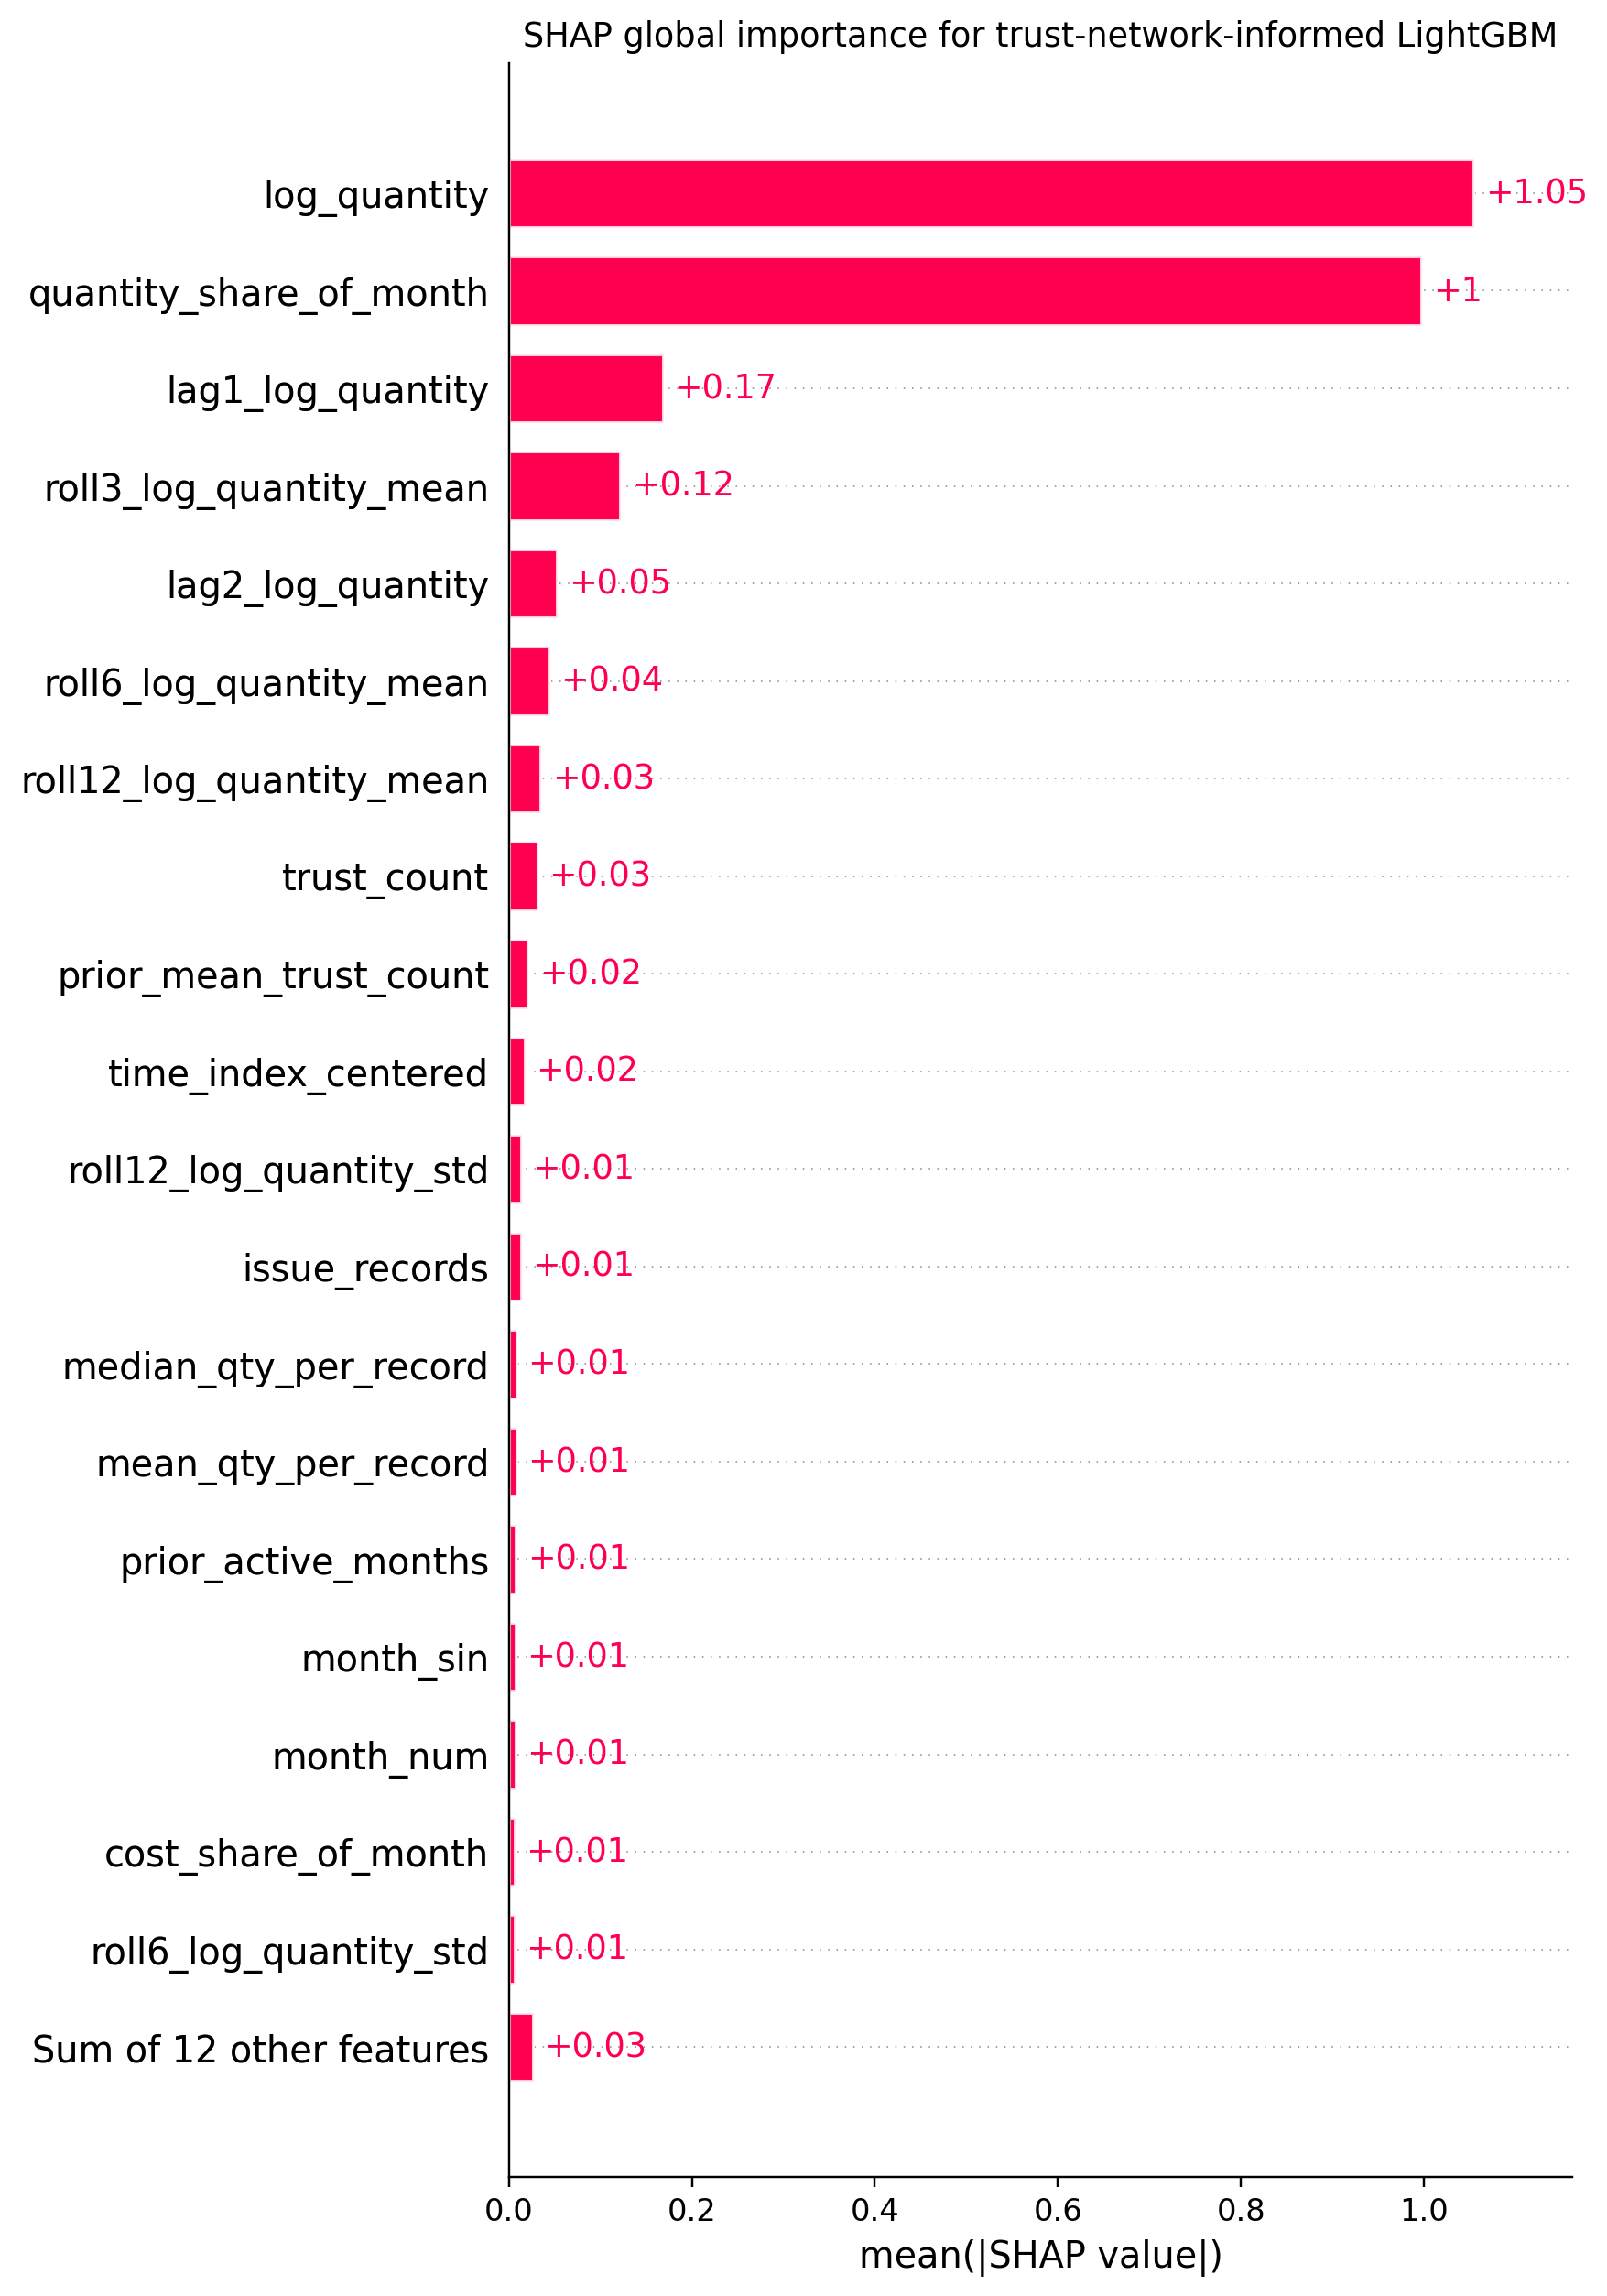

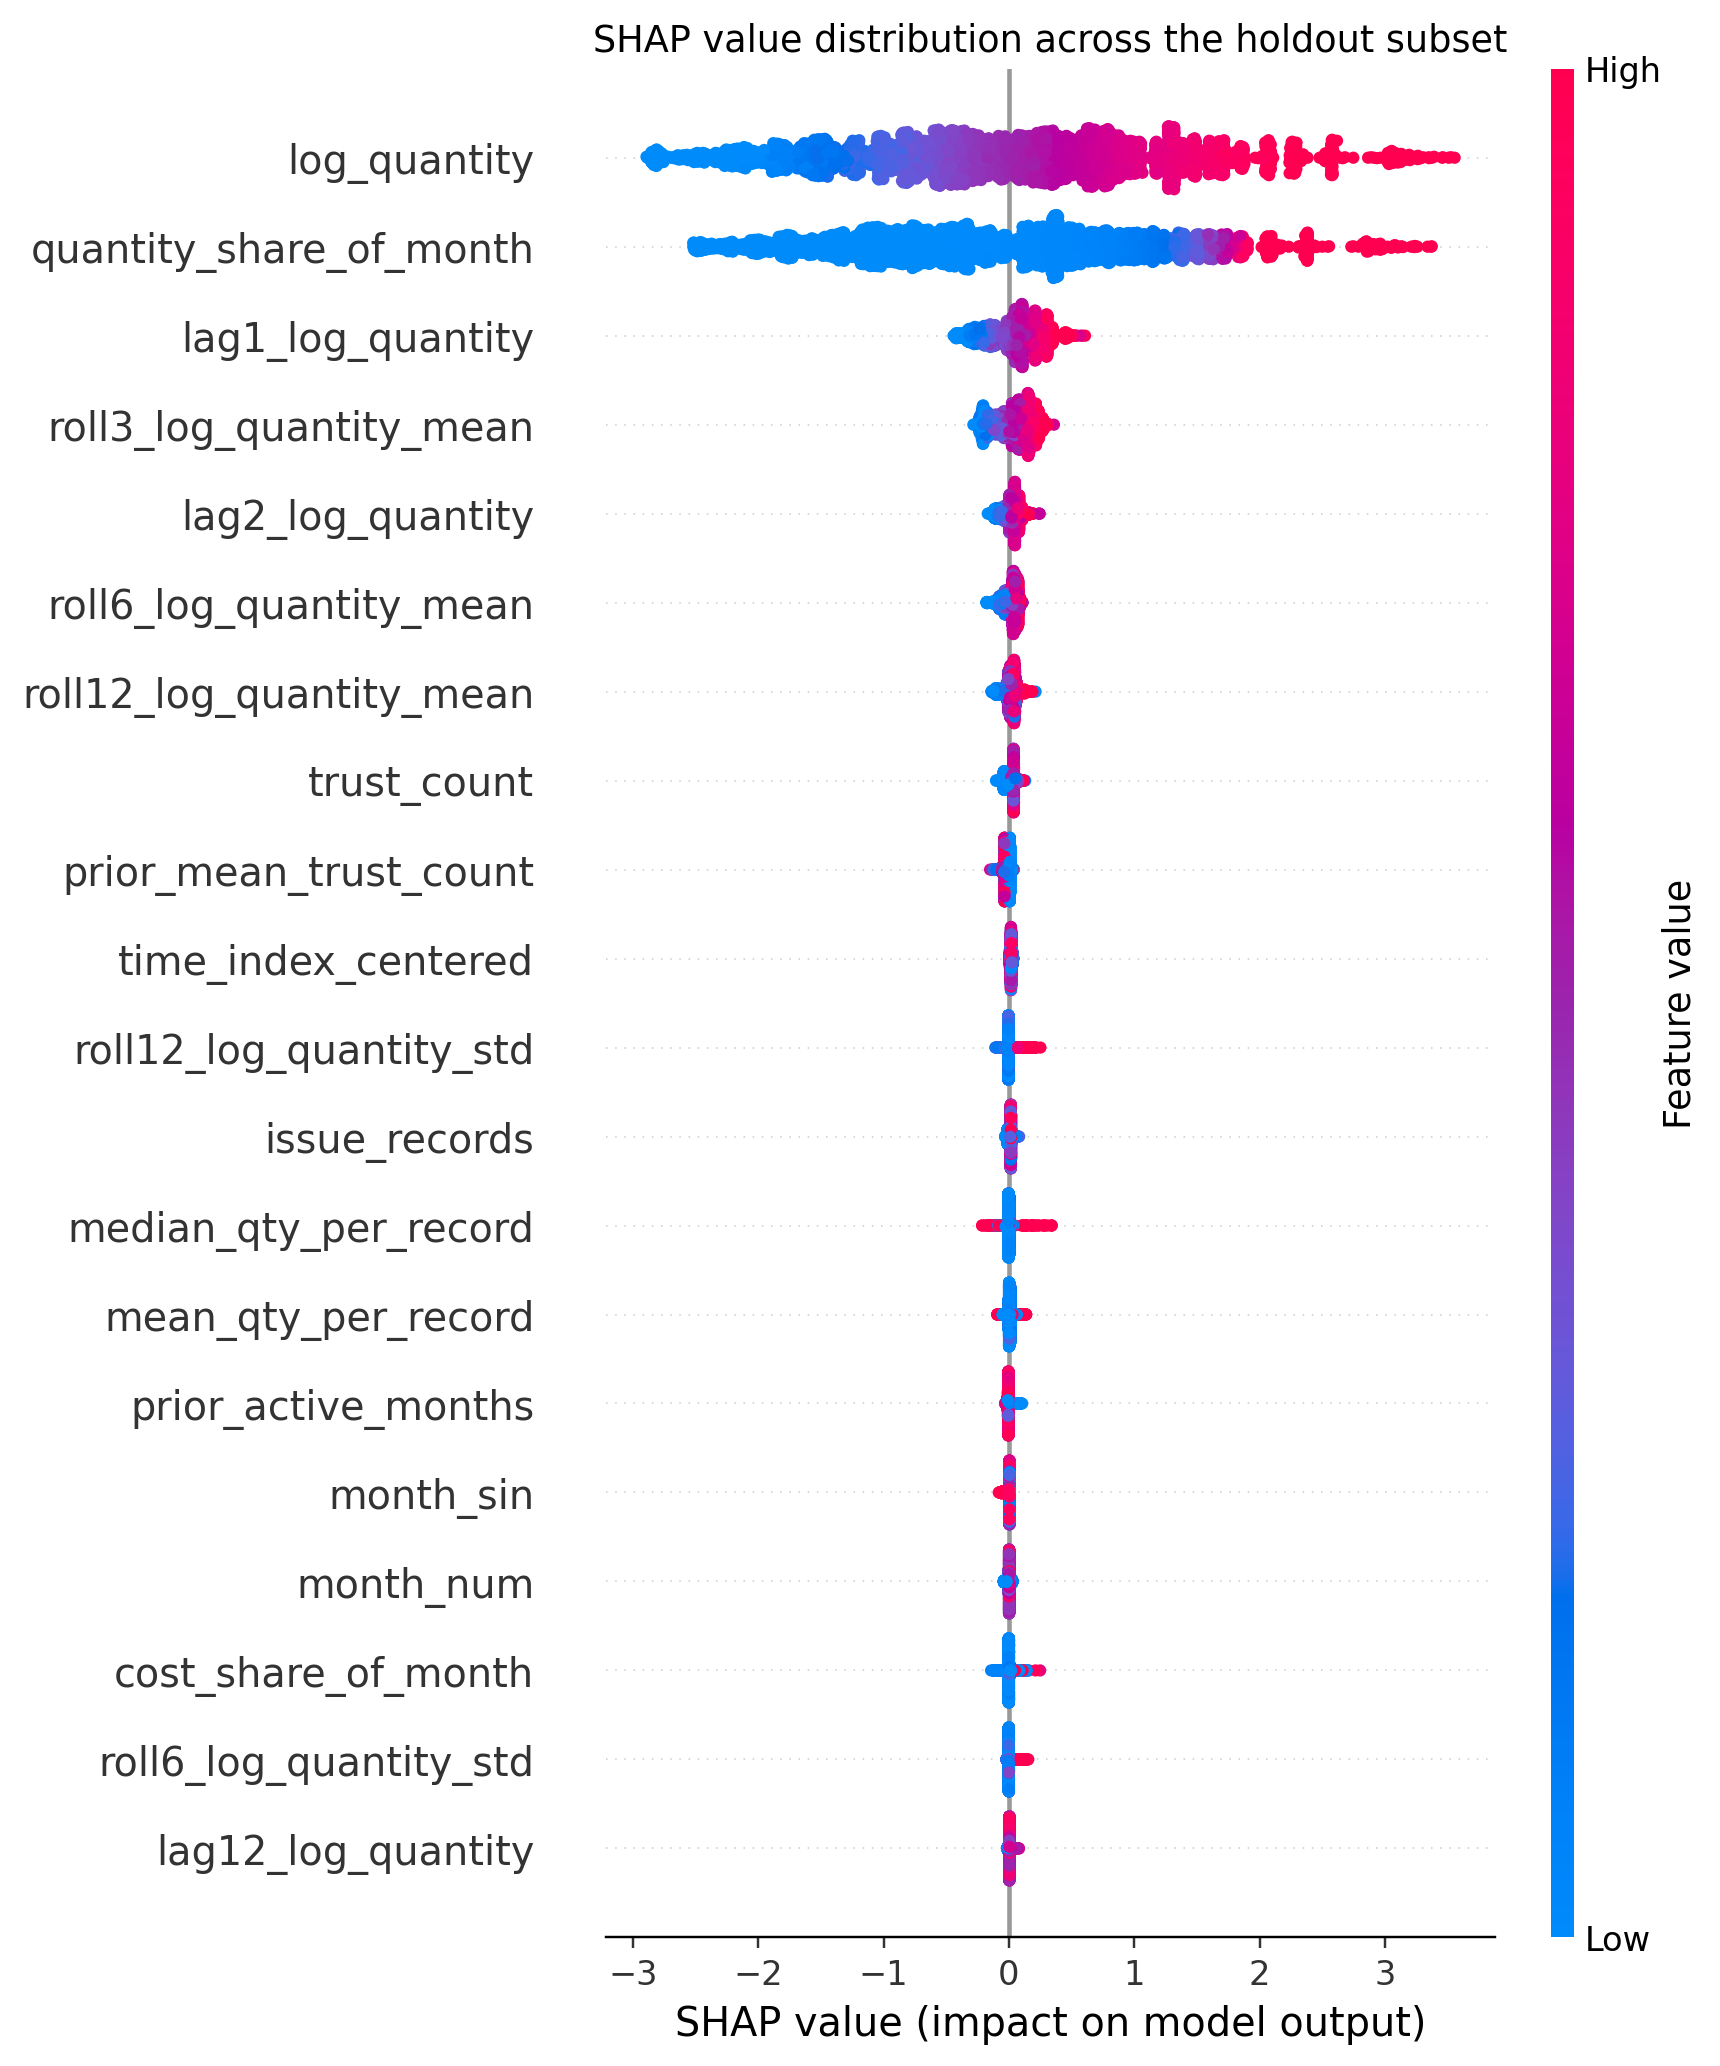

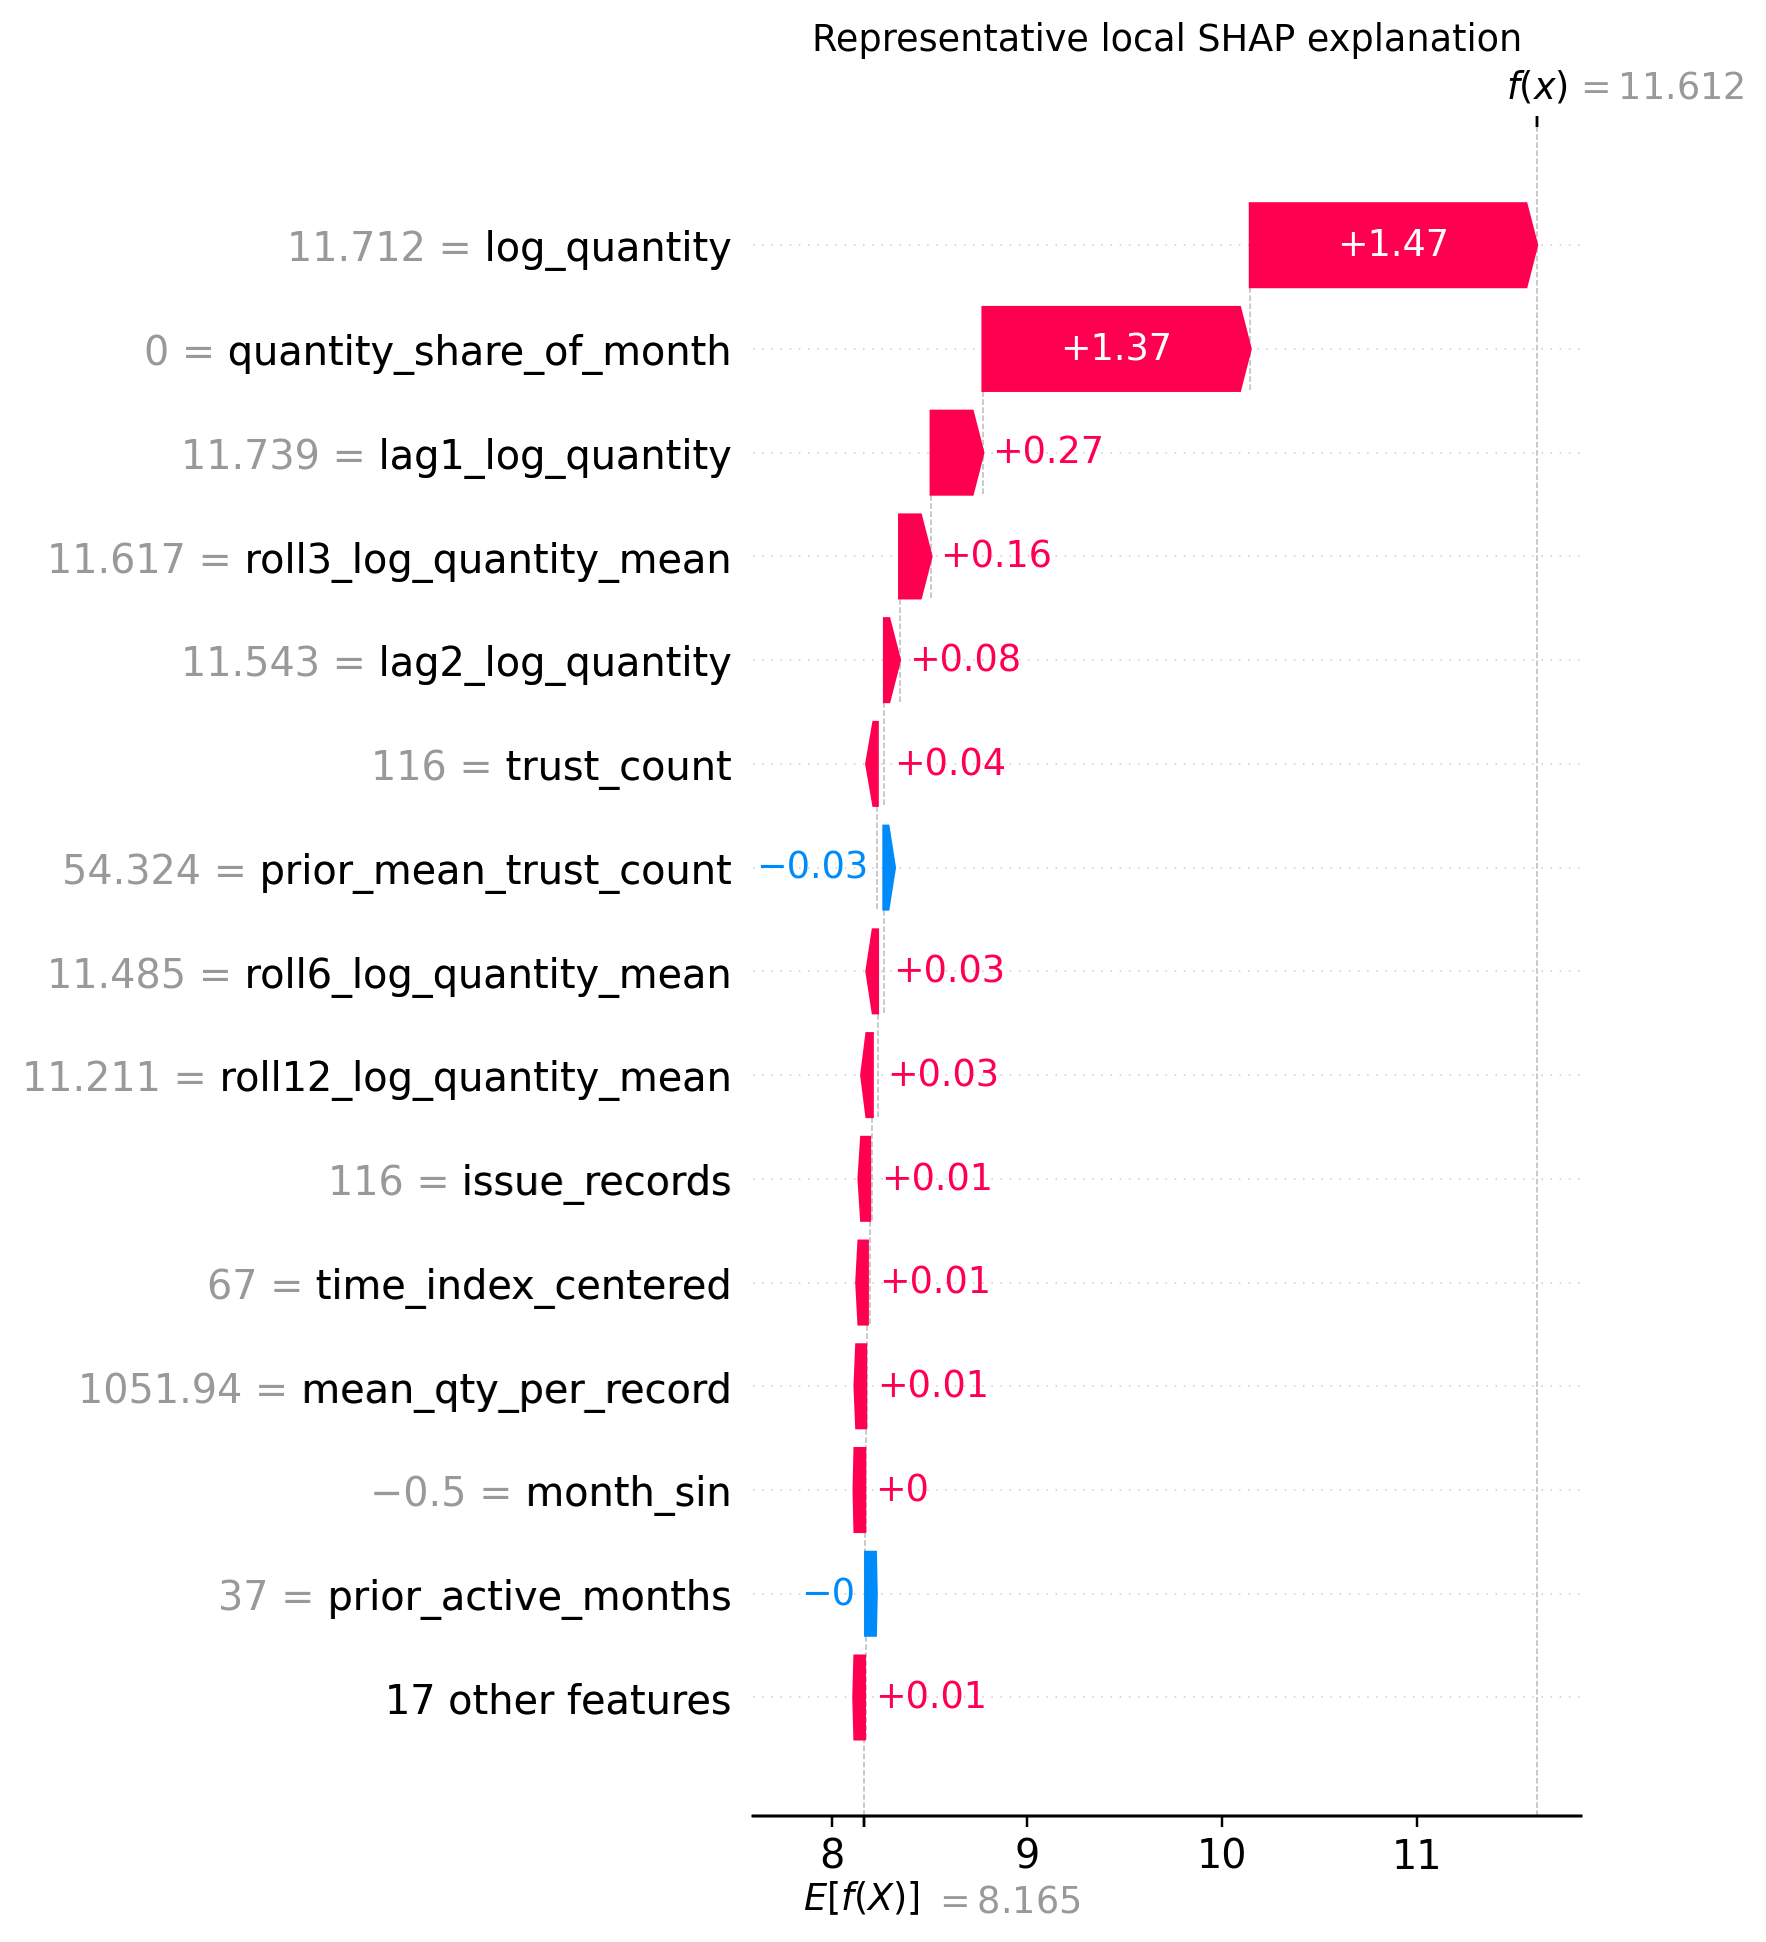

In [ ]:
import sys
import subprocess
import importlib.util
from pathlib import Path

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from IPython.display import display, Image as IPyImage

# -----------------------------
# Configuration
# -----------------------------
SHAP_SAMPLE_SIZE = 5000          # Increase if runtime allows
SHAP_RANDOM_STATE = 42
SHAP_MAX_DISPLAY = 20

if "run" not in globals():
    raise RuntimeError("Run Section 2 configuration first so the variable `run` exists.")

# Load modelling data if necessary
if "model_df" not in globals():
    model_path = Path(run.processed) / "model_df_leakage_free.pkl"
    if not model_path.exists():
        raise RuntimeError("Run Section 4 first, or ensure model_df_leakage_free.pkl exists.")
    model_df = pd.read_pickle(model_path)

model_df = model_df.copy()
model_df["year_month"] = model_df["year_month"].astype(str).str.zfill(6)

# Load trust-network-informed LightGBM model if necessary
if "models" in globals() and isinstance(models, dict) and "lightgbm_trust_network_informed" in models:
    shap_model = models["lightgbm_trust_network_informed"]
else:
    model_file = Path(run.outputs) / "lightgbm_trust_network_informed.joblib"
    if not model_file.exists():
        raise RuntimeError("Run Section 5 first so the trust-network-informed LightGBM model is fitted and saved.")
    shap_model = joblib.load(model_file)

# Resolve feature list. FULL_FEATURES should exist in the notebook module; fallback uses model feature names.
if "FULL_FEATURES" in globals():
    shap_features = list(FULL_FEATURES)
else:
    try:
        shap_features = list(shap_model.booster_.feature_name())
    except Exception:
        shap_features = list(getattr(shap_model, "feature_name_"))

missing_features = [c for c in shap_features if c not in model_df.columns]
if missing_features:
    raise RuntimeError(f"Missing SHAP feature columns in model_df: {missing_features[:10]}")

# Holdout subset: same holdout definition as the manuscript analysis.
holdout = model_df[model_df["year_month"] >= "202401"].copy()
if holdout.empty:
    raise RuntimeError("Holdout data are empty. Check that model_df contains year_month >= 202401.")

n_sample = min(SHAP_SAMPLE_SIZE, len(holdout))
X_sample = holdout[shap_features].sample(n=n_sample, random_state=SHAP_RANDOM_STATE).copy()

# Ensure numeric plotting input while preserving LightGBM-compatible values.
for col in X_sample.columns:
    X_sample[col] = pd.to_numeric(X_sample[col], errors="coerce")

meta_cols = [
    "year_month", "product_unit_key", "vmp_product_name", "unit_of_measure_name",
    "target_next_quantity", "target_next_log_quantity"
]
meta_cols = [c for c in meta_cols if c in holdout.columns]
shap_meta = holdout.loc[X_sample.index, meta_cols].copy()
shap_meta.insert(0, "source_row_index", X_sample.index.to_numpy())
shap_meta["sample_position"] = np.arange(len(shap_meta))

# Add monitoring information if available.
risk_file = Path(run.outputs) / "decision_support_monitoring_scores_leakage_free.csv"
if risk_file.exists() and {"year_month", "product_unit_key"}.issubset(shap_meta.columns):
    risk_cols = [
        "year_month", "product_unit_key", "monitoring_tier", "monitoring_priority_score",
        "predicted", "actual", "predicted_indicative_cost"
    ]
    risk = pd.read_csv(risk_file, dtype={"year_month": str, "product_unit_key": str})
    risk["year_month"] = risk["year_month"].astype(str).str.zfill(6)
    risk_cols = [c for c in risk_cols if c in risk.columns]
    shap_meta = shap_meta.merge(risk[risk_cols], on=["year_month", "product_unit_key"], how="left")

# -----------------------------
# Run TreeSHAP
# -----------------------------
explainer = shap.TreeExplainer(shap_model)

try:
    shap_values = explainer.shap_values(X_sample, check_additivity=False)
except TypeError:
    shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

base_value = explainer.expected_value
if isinstance(base_value, (list, tuple, np.ndarray)):
    base_value = float(np.asarray(base_value).ravel()[0])
else:
    base_value = float(base_value)

# SHAP values explain the log-model output, i.e., log(1 + next-month quantity).
log_pred_from_model = np.asarray(shap_model.predict(X_sample), dtype=float)
log_pred_from_shap = base_value + shap_values.sum(axis=1)

shap_fidelity = pd.DataFrame({
    "n_sample": [len(X_sample)],
    "base_value_log_scale": [base_value],
    "max_abs_difference_between_model_and_shap_log_prediction": [
        float(np.max(np.abs(log_pred_from_model - log_pred_from_shap)))
    ],
    "mean_abs_difference_between_model_and_shap_log_prediction": [
        float(np.mean(np.abs(log_pred_from_model - log_pred_from_shap)))
    ],
})

# -----------------------------
# Save global SHAP importance
# -----------------------------
figdir = Path(run.figures)
outdir = Path(run.outputs)
figdir.mkdir(parents=True, exist_ok=True)
outdir.mkdir(parents=True, exist_ok=True)

shap_importance = pd.DataFrame({
    "feature": shap_features,
    "mean_abs_shap_log_scale": np.abs(shap_values).mean(axis=0),
    "mean_shap_log_scale": shap_values.mean(axis=0),
}).sort_values("mean_abs_shap_log_scale", ascending=False).reset_index(drop=True)

shap_importance["mean_abs_shap_share"] = (
    shap_importance["mean_abs_shap_log_scale"] /
    shap_importance["mean_abs_shap_log_scale"].sum()
)

shap_importance.to_csv(outdir / "shap_global_importance_holdout_subset.csv", index=False)
shap_meta.to_csv(outdir / "shap_sample_metadata.csv", index=False)
shap_fidelity.to_csv(outdir / "shap_fidelity_check.csv", index=False)

# -----------------------------
# Figure S1: SHAP bar summary
# -----------------------------
plt.figure(figsize=(9, 6))
shap.plots.bar(
    shap.Explanation(
        values=shap_values,
        base_values=np.repeat(base_value, len(X_sample)),
        data=X_sample,
        feature_names=shap_features
    ),
    max_display=SHAP_MAX_DISPLAY,
    show=False,
)
plt.title("SHAP global importance for trust-network-informed LightGBM")
plt.tight_layout()
fig_s1 = figdir / "FigS1_SHAP_global_bar_holdout_subset.png"
plt.savefig(fig_s1, dpi=220, bbox_inches="tight")
plt.close()

# -----------------------------
# Figure S2: SHAP beeswarm summary
# -----------------------------
plt.figure(figsize=(9, 7))
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=shap_features,
    max_display=SHAP_MAX_DISPLAY,
    show=False
)
plt.title("SHAP value distribution across the holdout subset")
plt.tight_layout()
fig_s2 = figdir / "FigS2_SHAP_beeswarm_holdout_subset.png"
plt.savefig(fig_s2, dpi=220, bbox_inches="tight")
plt.close()

# -----------------------------
# Figure S3: representative local explanation
# -----------------------------
if "monitoring_priority_score" in shap_meta.columns and shap_meta["monitoring_priority_score"].notna().any():
    representative_pos = int(
        shap_meta.sort_values("monitoring_priority_score", ascending=False).iloc[0]["sample_position"]
    )
else:
    representative_pos = int(np.argmax(log_pred_from_model))

representative_meta = shap_meta.iloc[[representative_pos]].copy()
representative_meta.to_csv(outdir / "shap_representative_product_month_metadata.csv", index=False)

try:
    local_exp = shap.Explanation(
        values=shap_values[representative_pos],
        base_values=base_value,
        data=X_sample.iloc[representative_pos].to_numpy(),
        feature_names=shap_features,
    )

    plt.figure(figsize=(9, 6))
    shap.plots.waterfall(local_exp, max_display=15, show=False)
    plt.title("Representative local SHAP explanation")
    plt.tight_layout()
    fig_s3 = figdir / "FigS3_SHAP_local_waterfall_representative_product_month.png"
    plt.savefig(fig_s3, dpi=220, bbox_inches="tight")
    plt.close()

except Exception as exc:
    # Fallback for older SHAP/matplotlib combinations.
    local = pd.DataFrame({
        "feature": shap_features,
        "shap_value_log_scale": shap_values[representative_pos],
    })
    local["abs_value"] = local["shap_value_log_scale"].abs()
    local = (
        local.sort_values("abs_value", ascending=False)
        .head(15)
        .sort_values("shap_value_log_scale")
    )

    ax = local.plot(
        kind="barh",
        x="feature",
        y="shap_value_log_scale",
        legend=False,
        figsize=(9, 6)
    )
    ax.set_xlabel("SHAP value on log(1 + quantity) scale")
    ax.set_title("Representative local SHAP explanation")
    plt.tight_layout()
    fig_s3 = figdir / "FigS3_SHAP_local_bar_representative_product_month.png"
    plt.savefig(fig_s3, dpi=220, bbox_inches="tight")
    plt.close()

    print(f"Waterfall plot failed; saved fallback local bar chart. Reason: {exc}")

print("SHAP analysis completed.")
print("Important: SHAP values explain model output on the log(1 + next-month quantity) scale, not raw quantity directly.")

print("Saved outputs:")
for p in [
    outdir / "shap_global_importance_holdout_subset.csv",
    outdir / "shap_sample_metadata.csv",
    outdir / "shap_fidelity_check.csv",
    outdir / "shap_representative_product_month_metadata.csv",
    fig_s1,
    fig_s2,
    fig_s3,
]:
    print(" -", p)

print("\nTop SHAP features:")
display(shap_importance.head(15))

print("\nSHAP fidelity check:")
display(shap_fidelity)

print("\nRepresentative product-month metadata:")
display(representative_meta)

for fig_path in [fig_s1, fig_s2, fig_s3]:
    if Path(fig_path).exists():
        display(IPyImage(filename=str(fig_path)))

Loading and displaying SHAP outputs:

Top SHAP features:


,feature,mean_abs_shap_log_scale,mean_shap_log_scale,mean_abs_shap_share
0,log_quantity,1.054214,0.022221,0.398423
1,quantity_share_of_month,0.997273,-0.029797,0.376904
2,lag1_log_quantity,0.168178,0.038834,0.063560
3,roll3_log_quantity_mean,0.121658,0.022048,0.045979
4,lag2_log_quantity,0.052680,0.015930,0.019909
5,roll6_log_quantity_mean,0.044587,0.013815,0.016851
6,roll12_log_quantity_mean,0.034689,0.011766,0.013110
7,trust_count,0.031371,0.006515,0.011856
8,prior_mean_trust_count,0.020618,-0.015752,0.007792
9,time_index_centered,0.016948,0.016948,0.006405



SHAP fidelity check:


,n_sample,base_value_log_scale,max_abs_difference_between_model_and_shap_log_prediction,mean_abs_difference_between_model_and_shap_log_prediction
0,5000,8.164901,2.131628e-14,4.242429e-15



Representative product-month metadata:


,source_row_index,year_month,product_unit_key,vmp_product_name,unit_of_measure_name,target_next_quantity,target_next_log_quantity,sample_position,monitoring_tier,monitoring_priority_score,predicted,actual,predicted_indicative_cost
0,307995,202411,40087811000001102|428673006,Upadacitinib 30mg modified-release tablets,TABLET,121262.0,11.705717,661,High monitoring priority,92.8916,110394.124634,121262.0,5.052660e+06



Displaying SHAP figures:
 - FigS1_SHAP_global_bar_holdout_subset.png


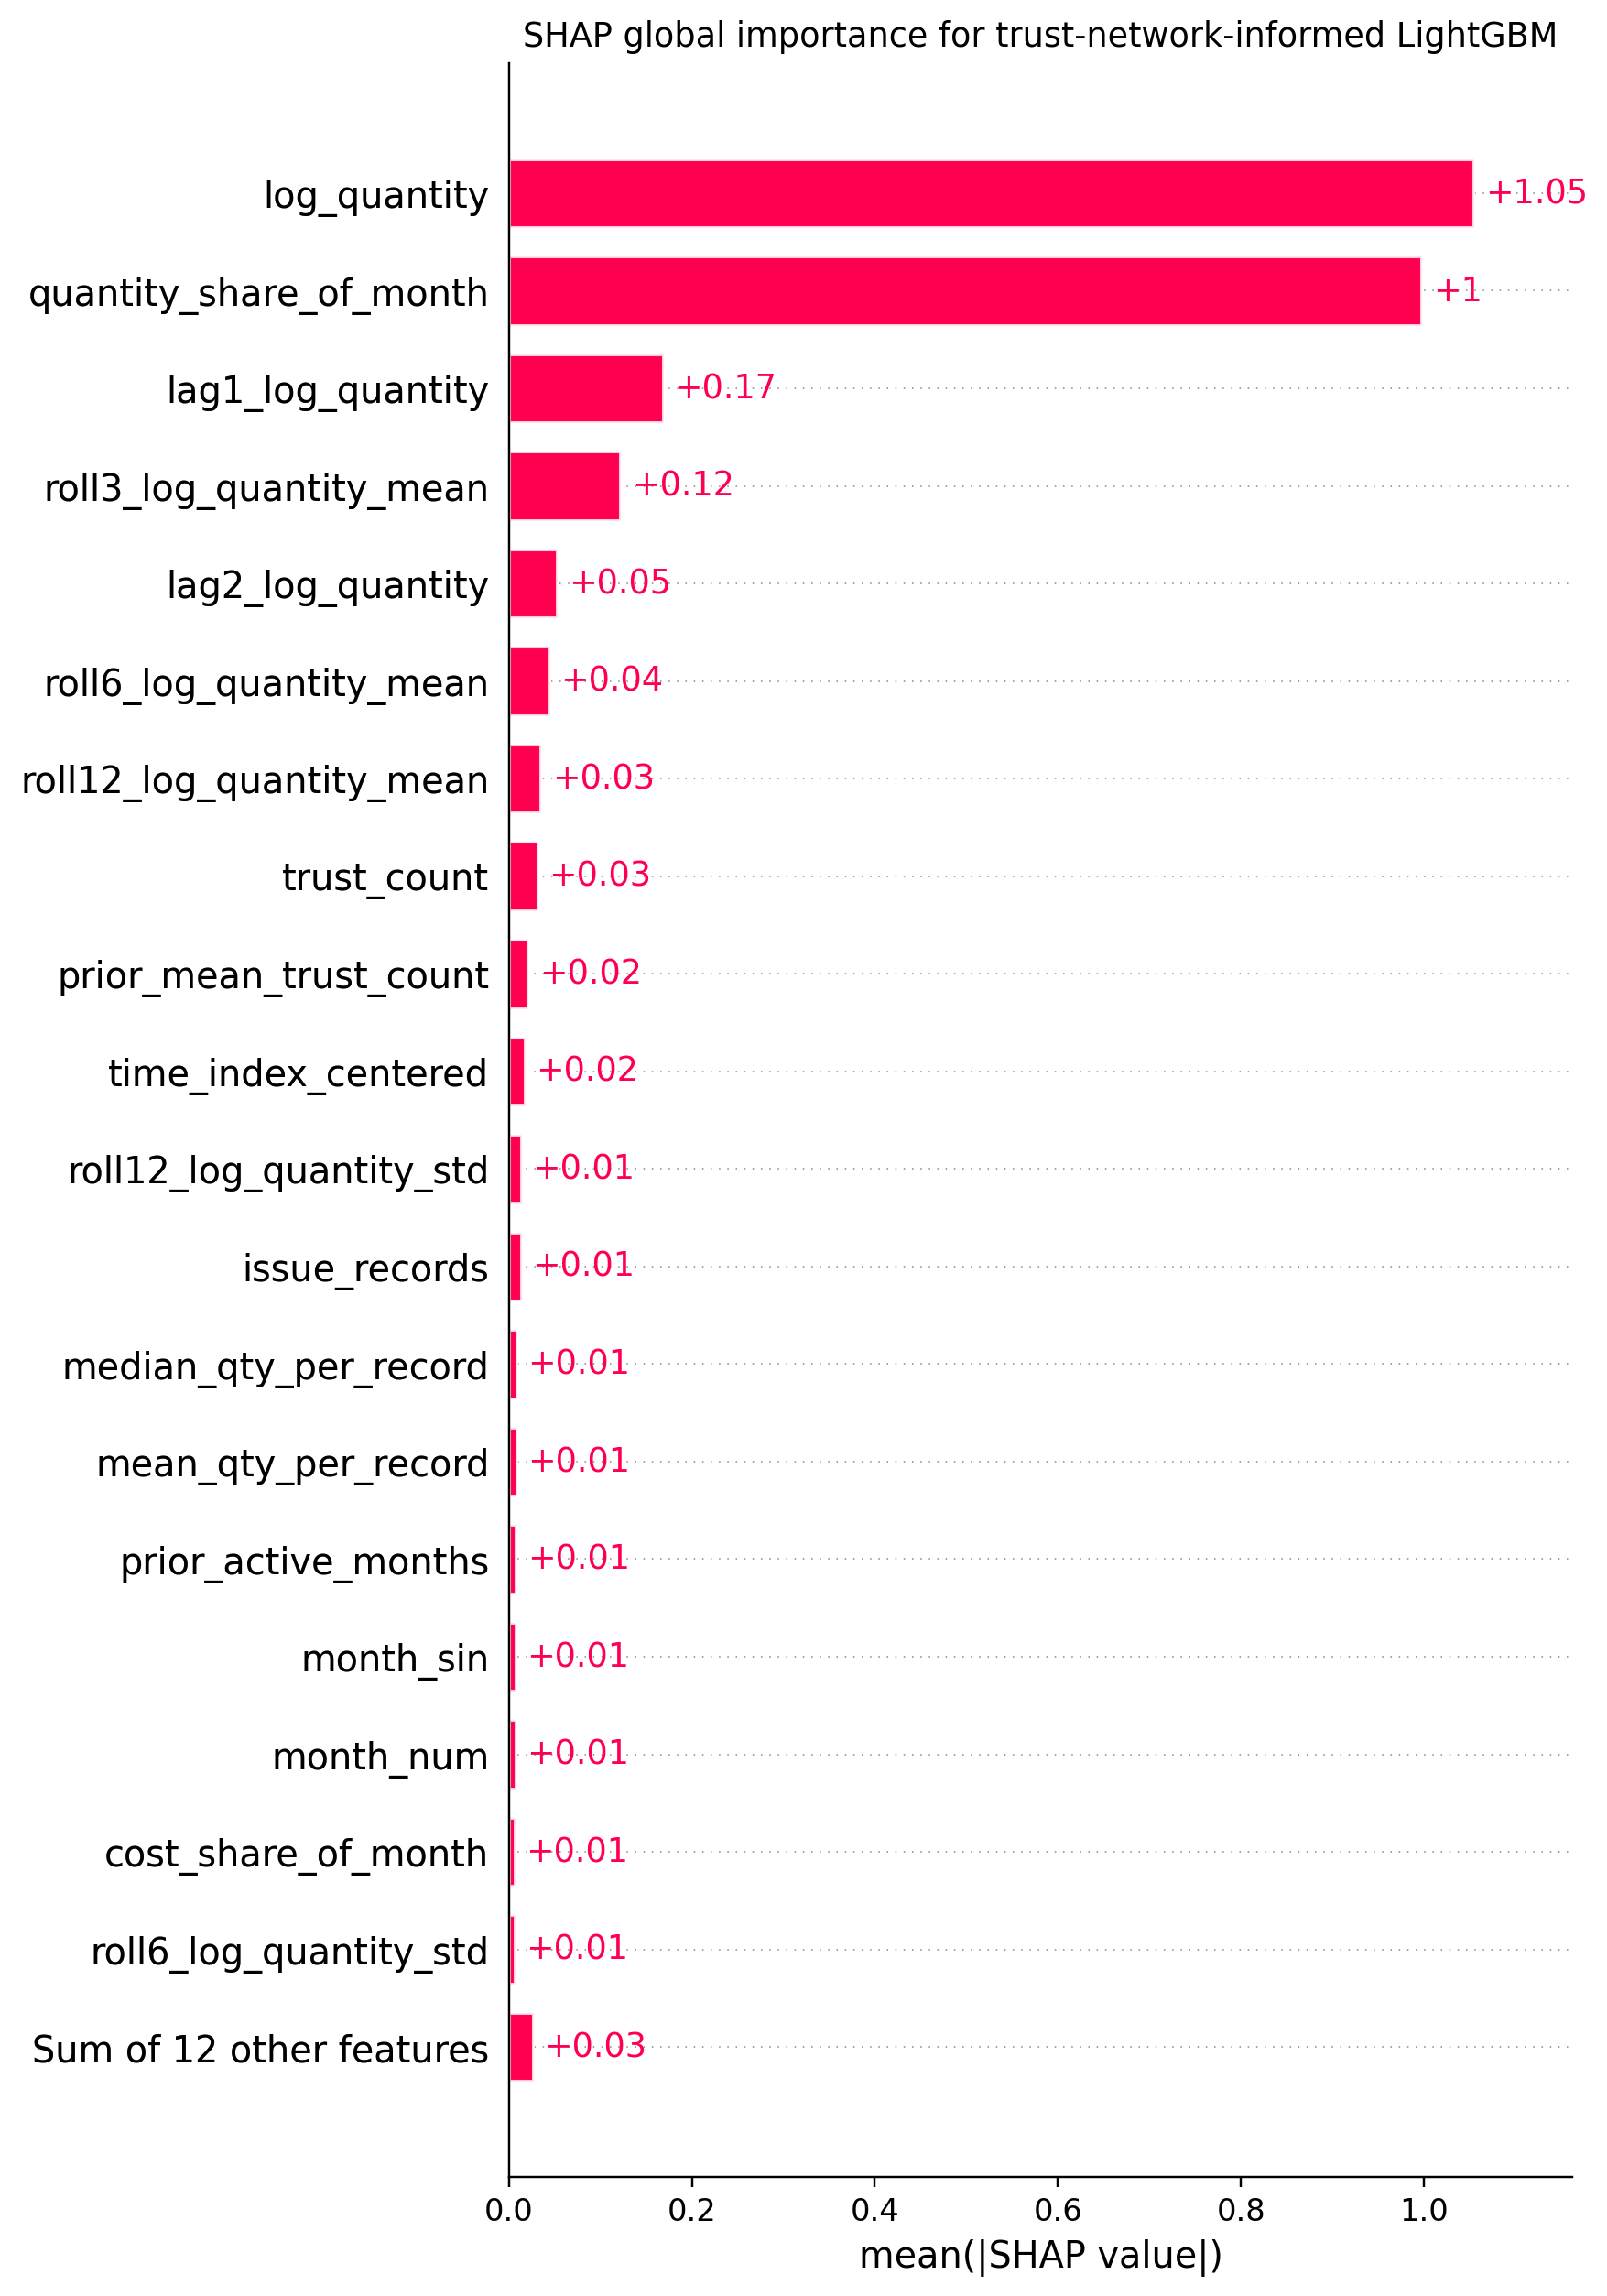

 - FigS2_SHAP_beeswarm_holdout_subset.png


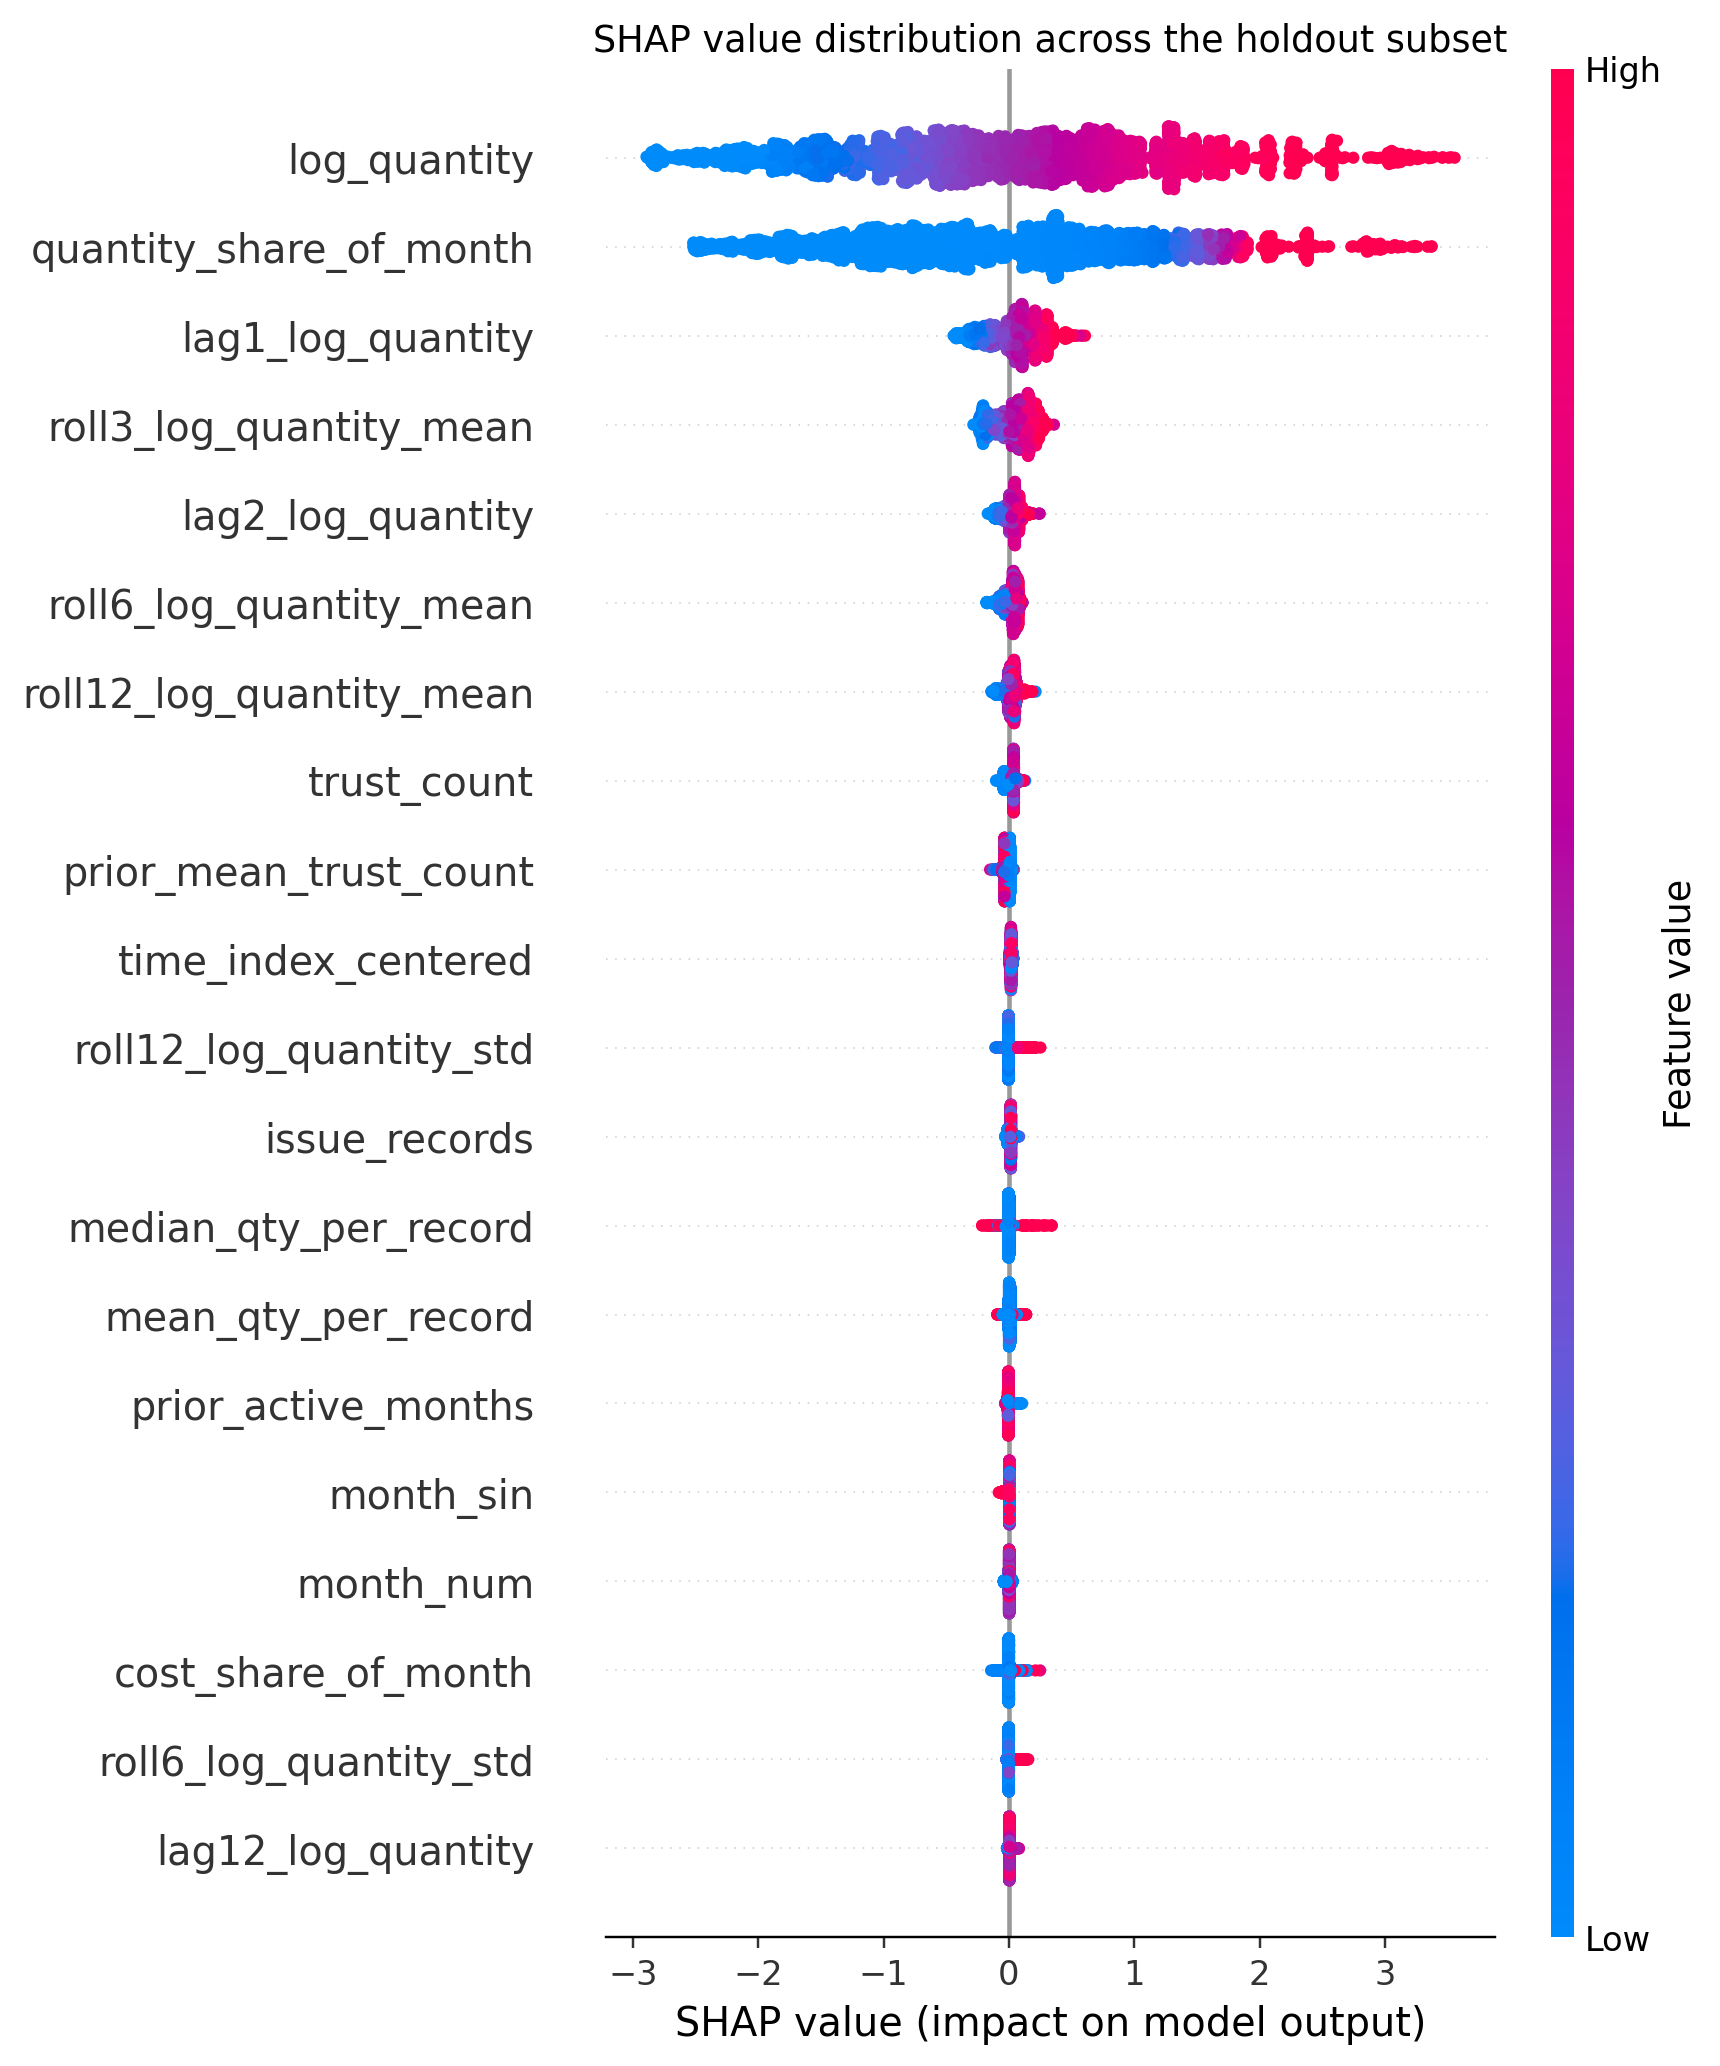

 - FigS3_SHAP_local_waterfall_representative_product_month.png


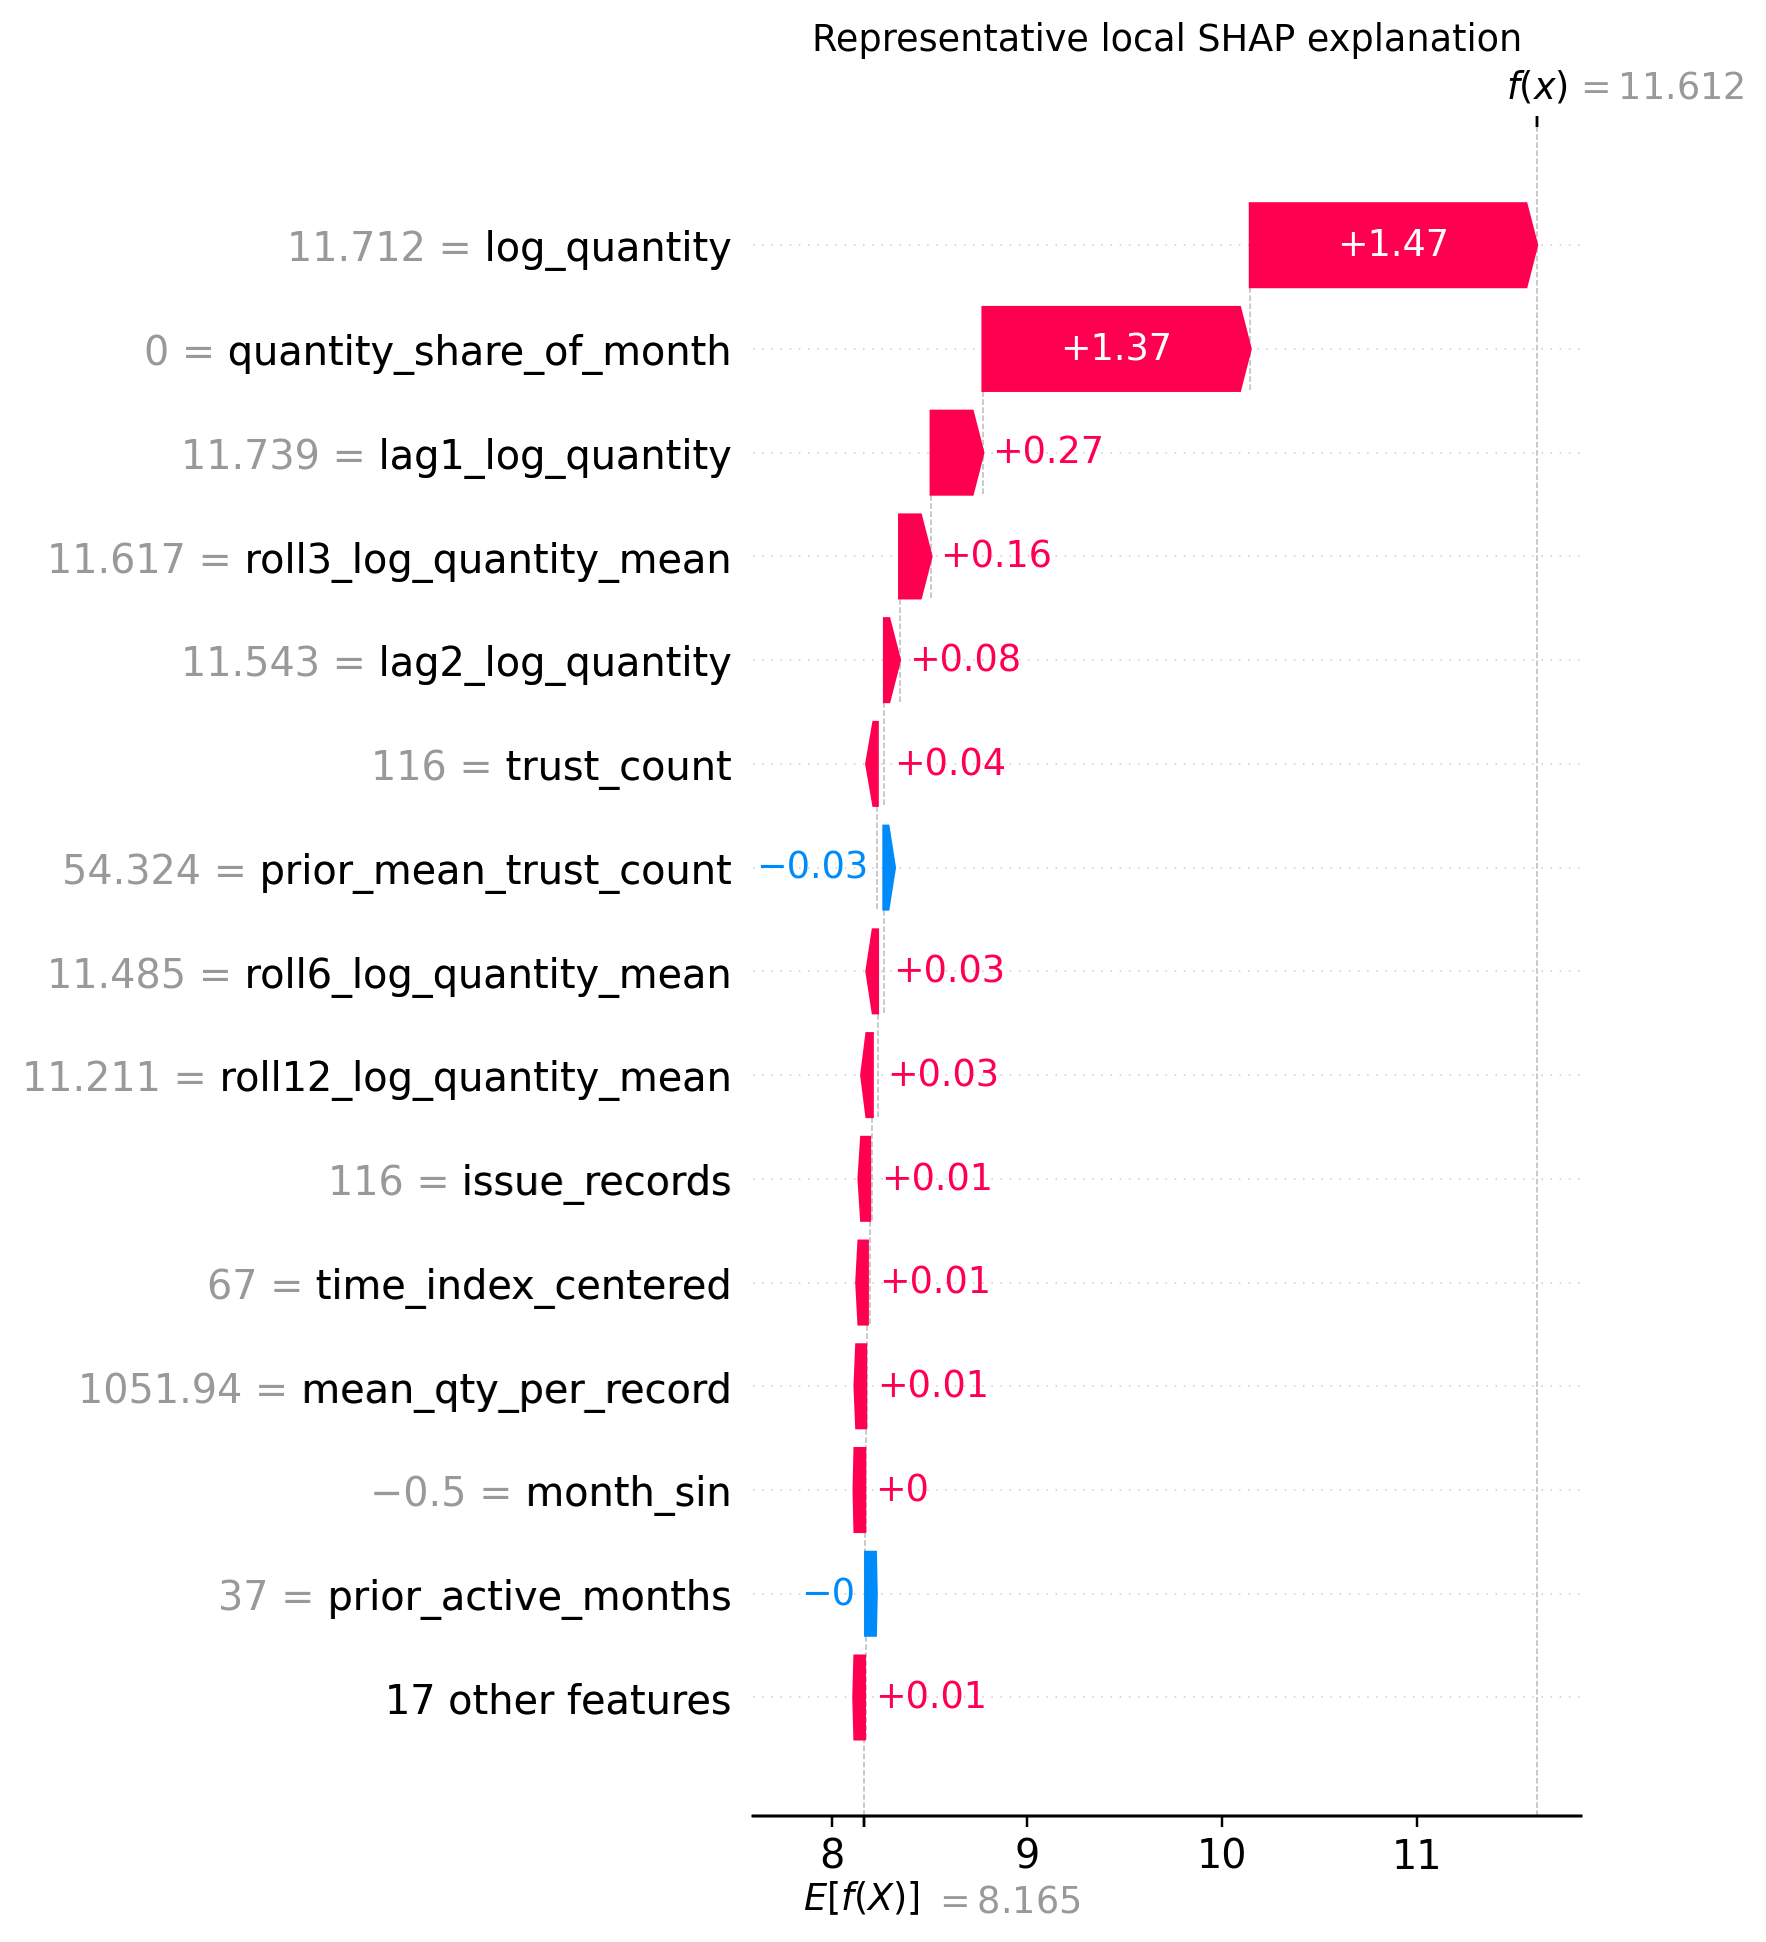

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

# Ensure 'run' object is available, assuming section 2 was run.
if 'run' not in globals():
    raise RuntimeError('Please run Section 2 (Configuration) first to initialize the `run` object.')

outdir = Path(run.outputs)
figdir = Path(run.figures)

print("Loading and displaying SHAP outputs:")

# Load and display Top SHAP features
shap_importance_path = outdir / "shap_global_importance_holdout_subset.csv"
if shap_importance_path.exists():
    shap_importance = pd.read_csv(shap_importance_path)
    print("\nTop SHAP features:")
    display(shap_importance.head(15))
else:
    print(f"Warning: {shap_importance_path} not found.")

# Load and display SHAP fidelity check
shap_fidelity_path = outdir / "shap_fidelity_check.csv"
if shap_fidelity_path.exists():
    shap_fidelity = pd.read_csv(shap_fidelity_path)
    print("\nSHAP fidelity check:")
    display(shap_fidelity)
else:
    print(f"Warning: {shap_fidelity_path} not found.")

# Load and display Representative product-month metadata
representative_meta_path = outdir / "shap_representative_product_month_metadata.csv"
if representative_meta_path.exists():
    representative_meta = pd.read_csv(representative_meta_path)
    print("\nRepresentative product-month metadata:")
    display(representative_meta)
else:
    print(f"Warning: {representative_meta_path} not found.")

# Display SHAP figures
print("\nDisplaying SHAP figures:")
for fig_name in [
    "FigS1_SHAP_global_bar_holdout_subset.png",
    "FigS2_SHAP_beeswarm_holdout_subset.png",
    "FigS3_SHAP_local_waterfall_representative_product_month.png",
]:
    fig_path = figdir / fig_name
    if fig_path.exists():
        print(f" - {fig_name}")
        display(Image(filename=str(fig_path)))
    else:
        print(f"Warning: {fig_path} not found.")


## 6 Descriptive analysis

The following cell generates all core figures from the raw analysis outputs. These are programmatic figures, not generative-AI figures.

Fig1_monthly_quantity_trend.png


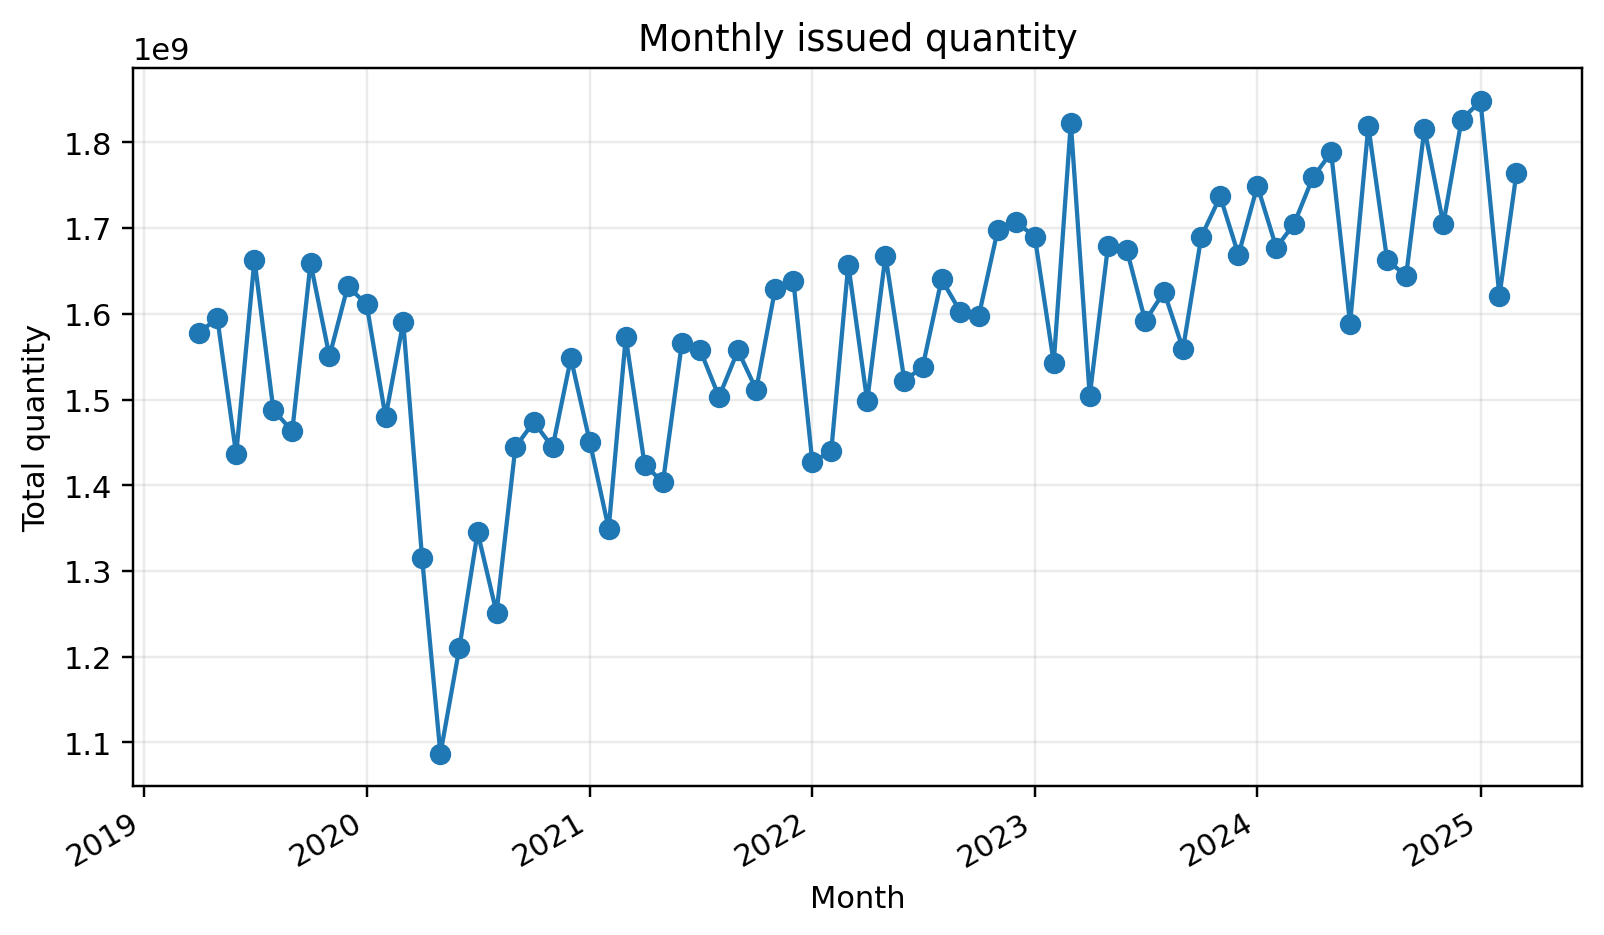

Fig2_monthly_cost_trend.png


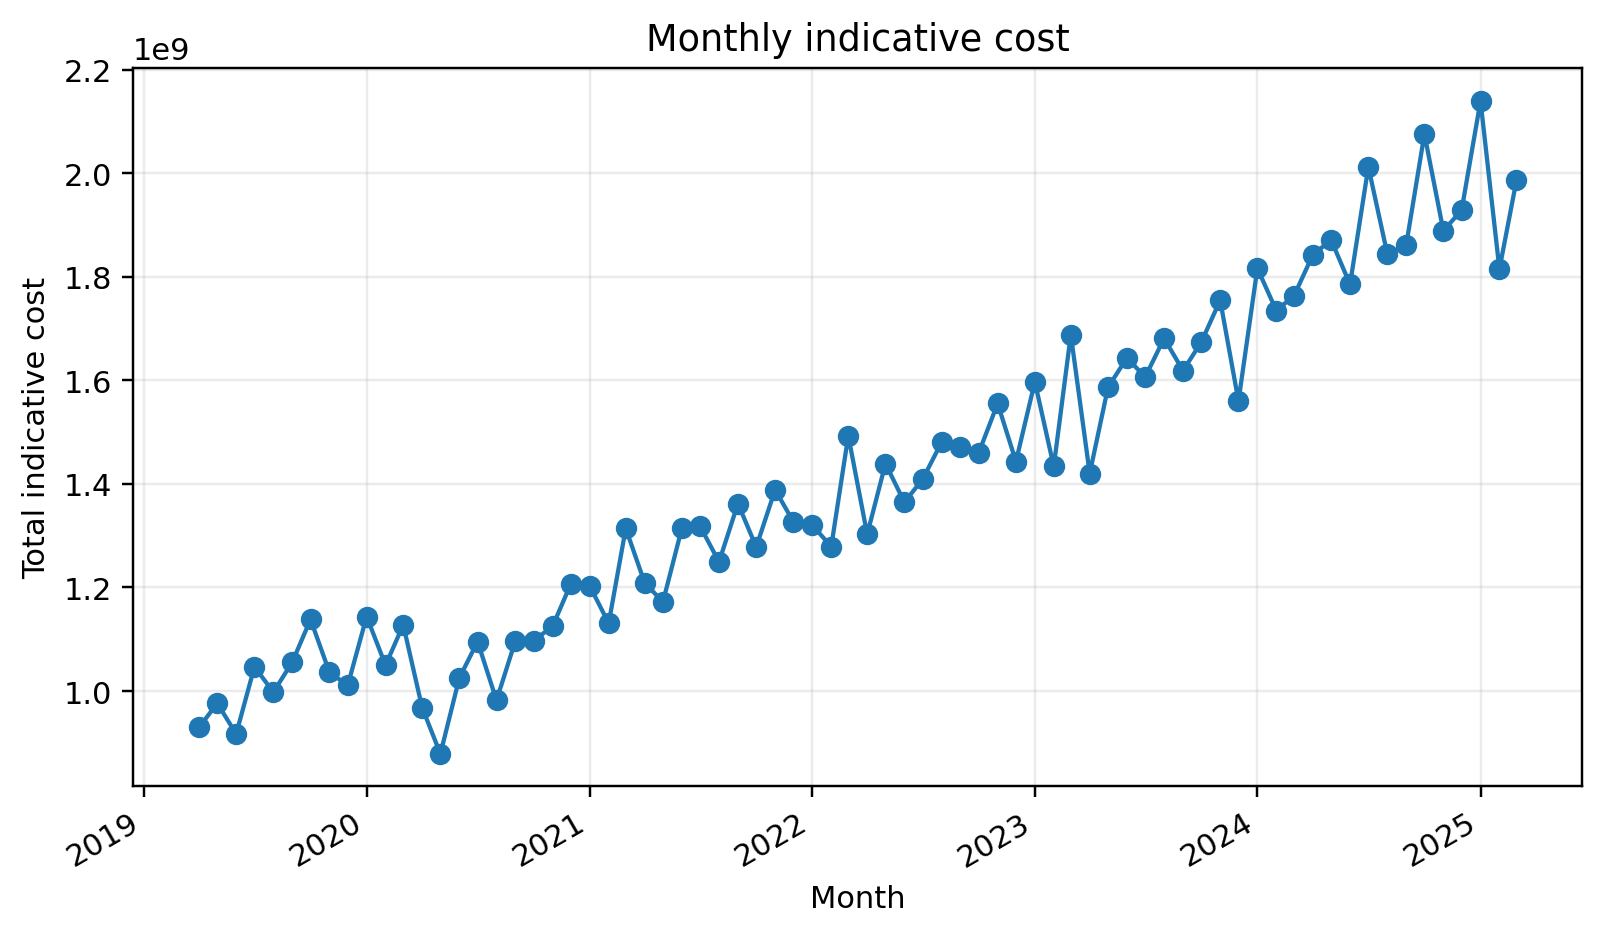

Fig3_distribution_before_after_log.png


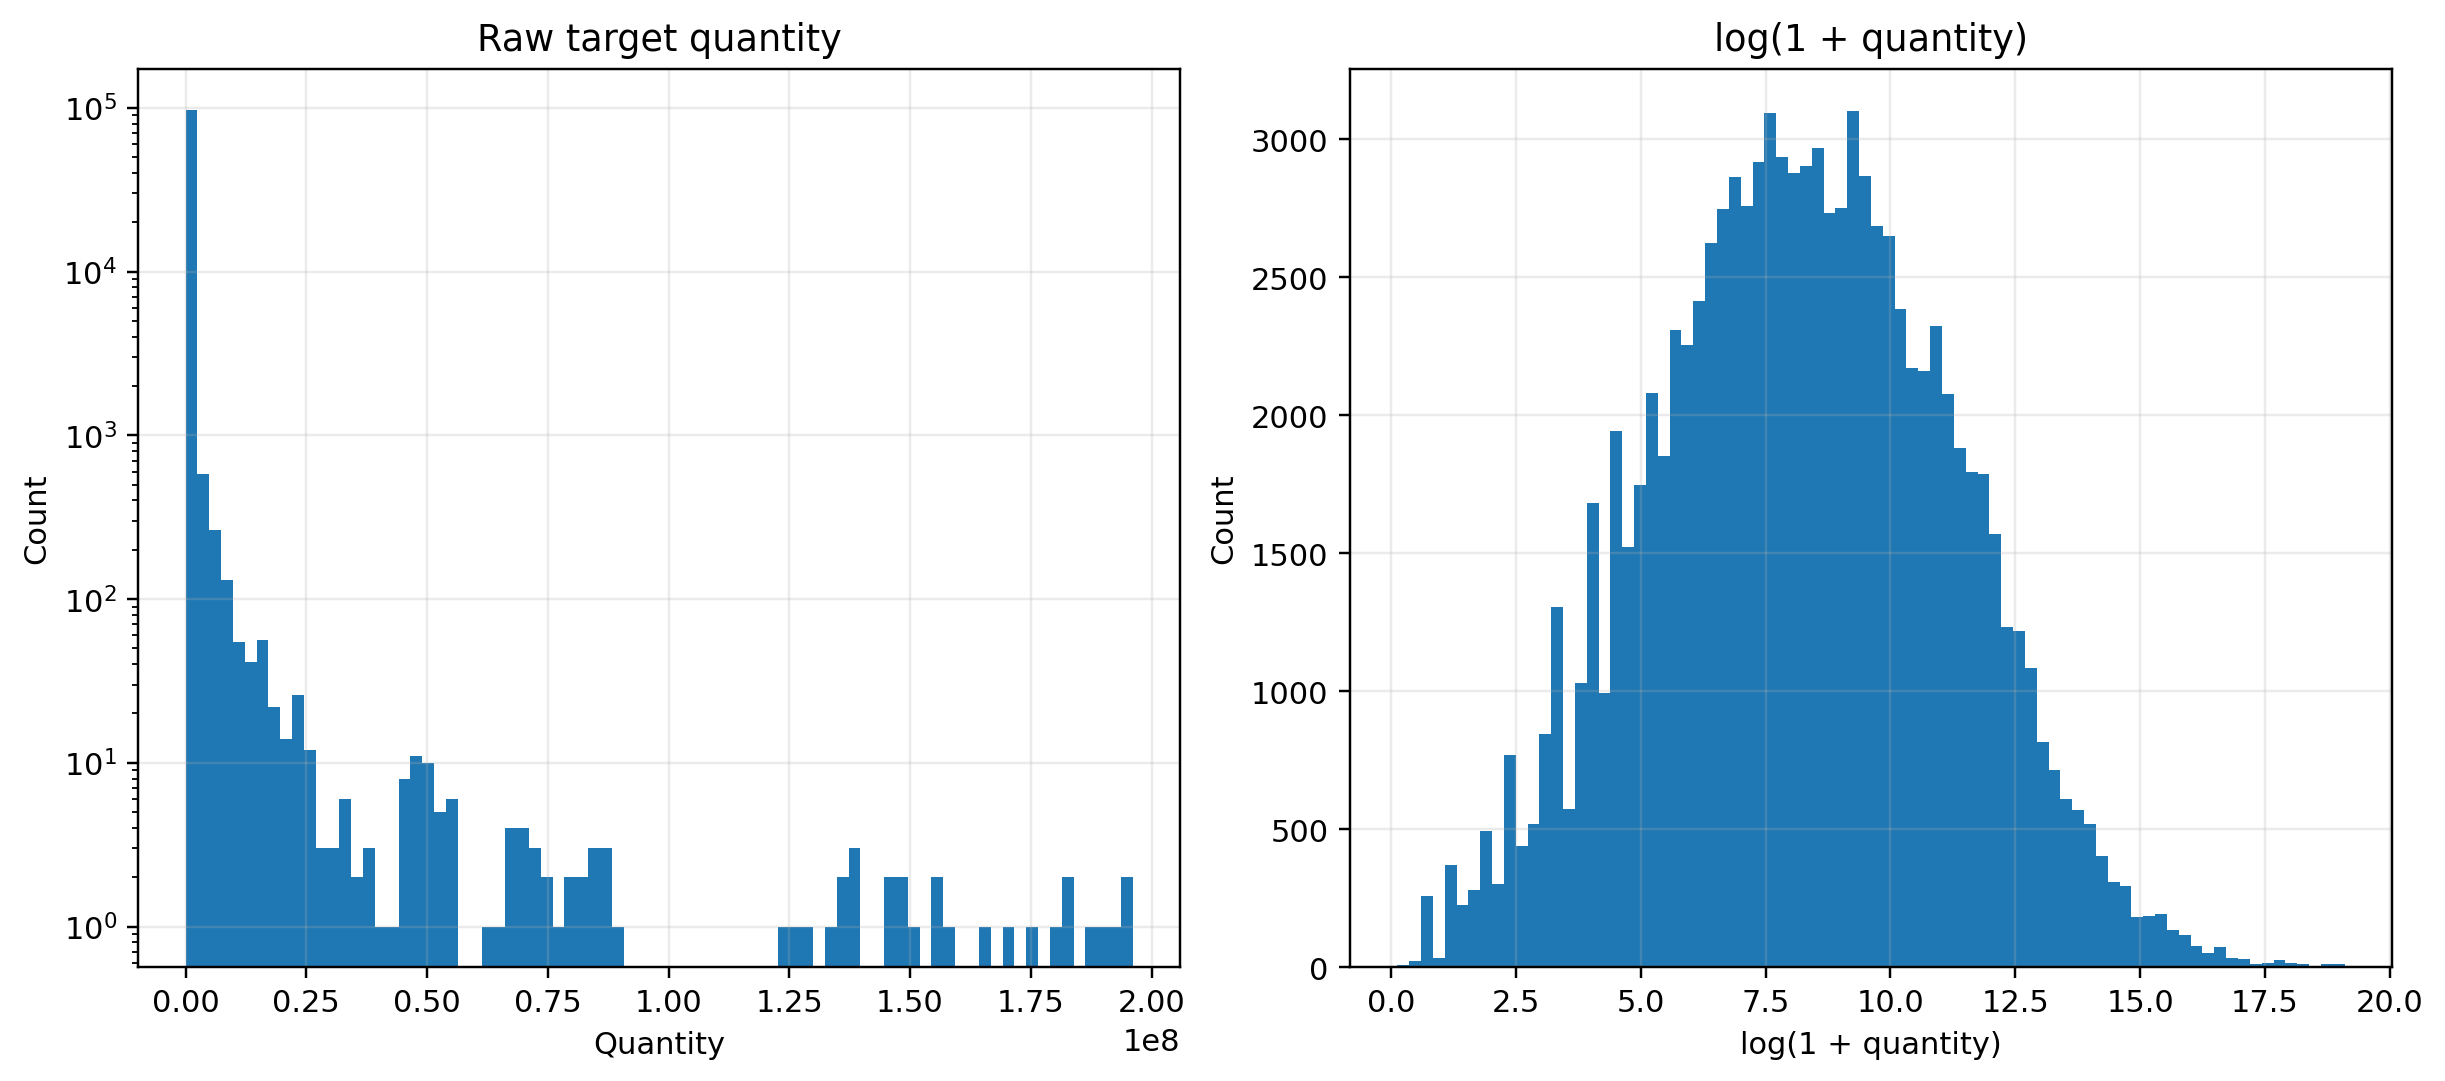

Fig4_revised_workflow.png


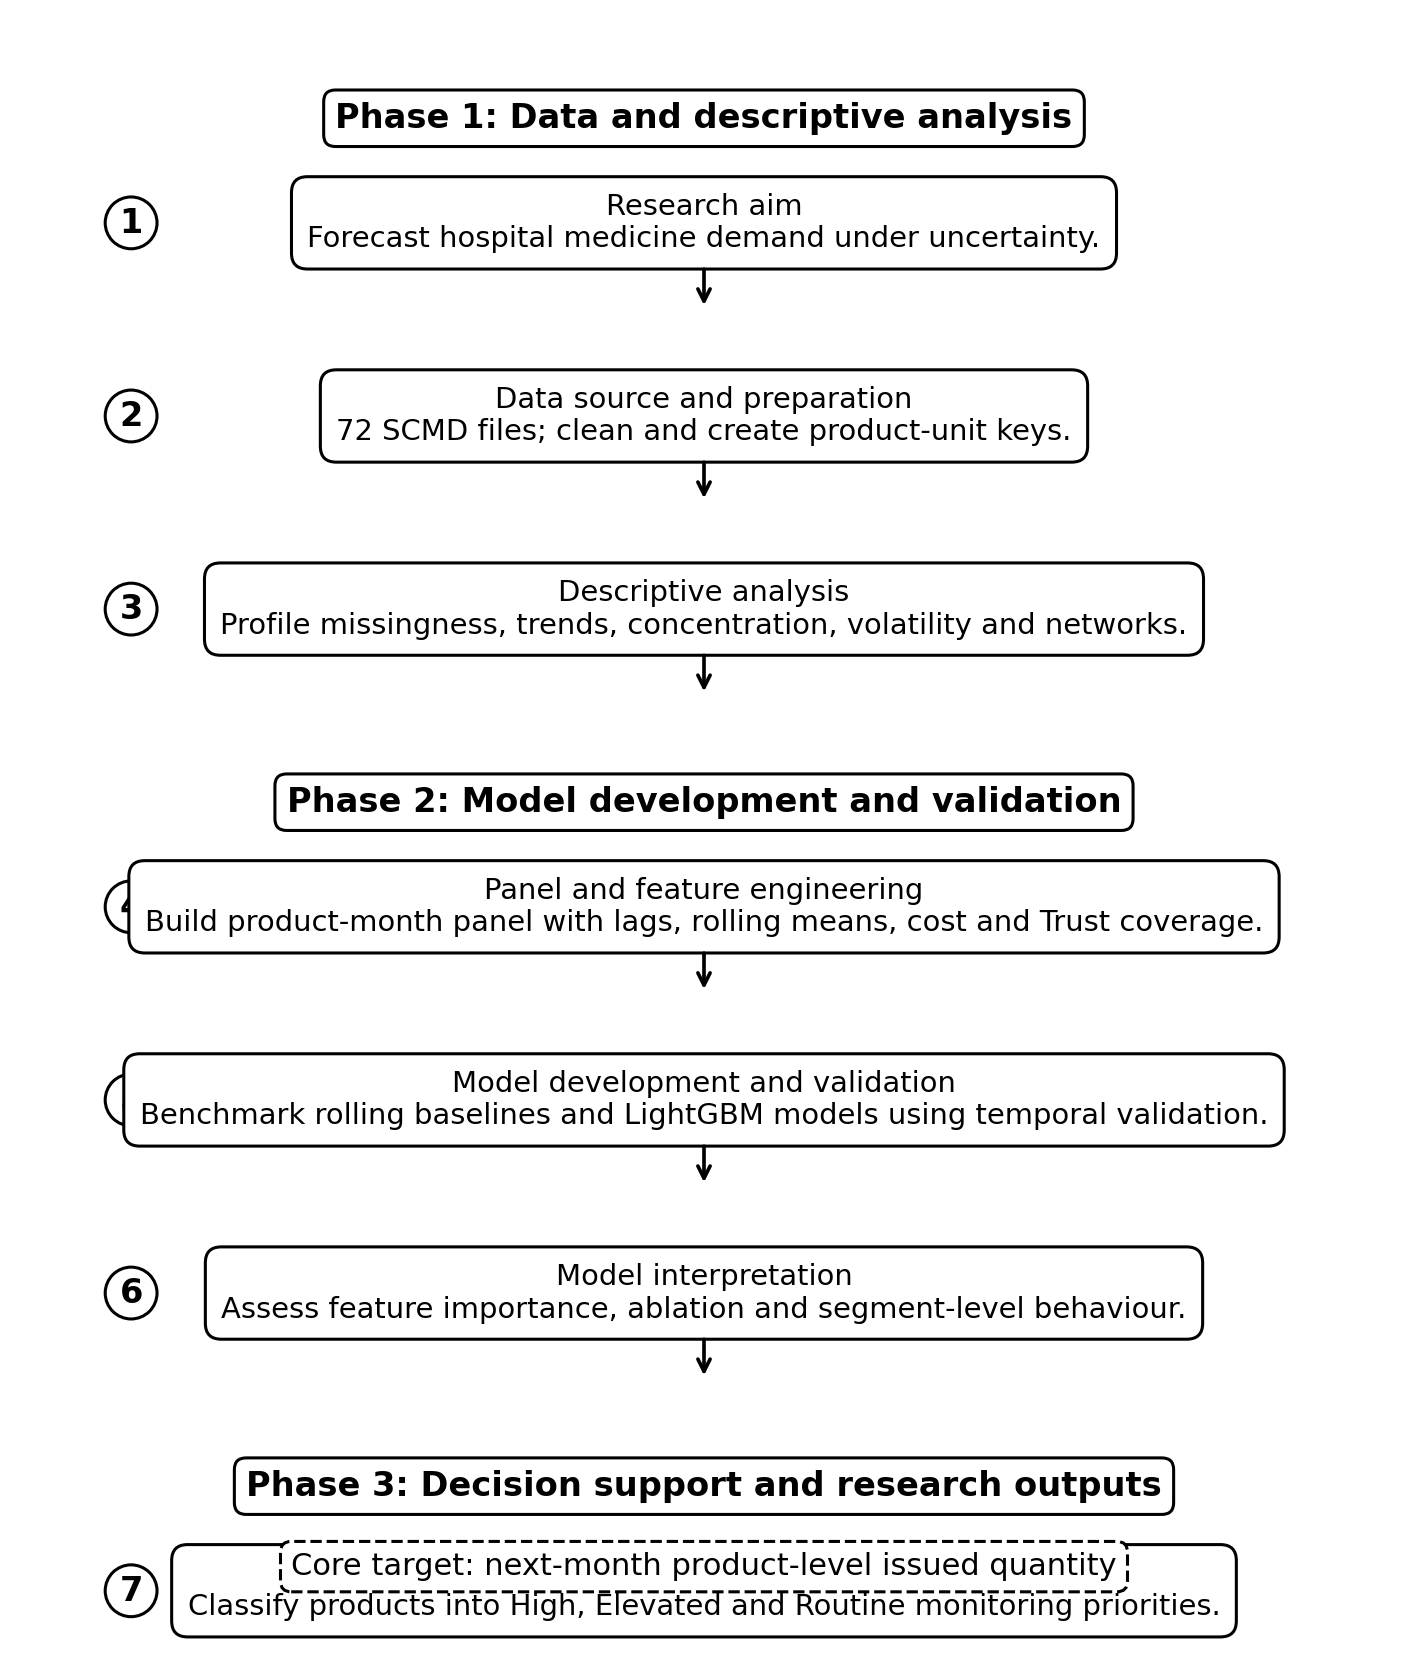

Fig5_holdout_validation_results.png


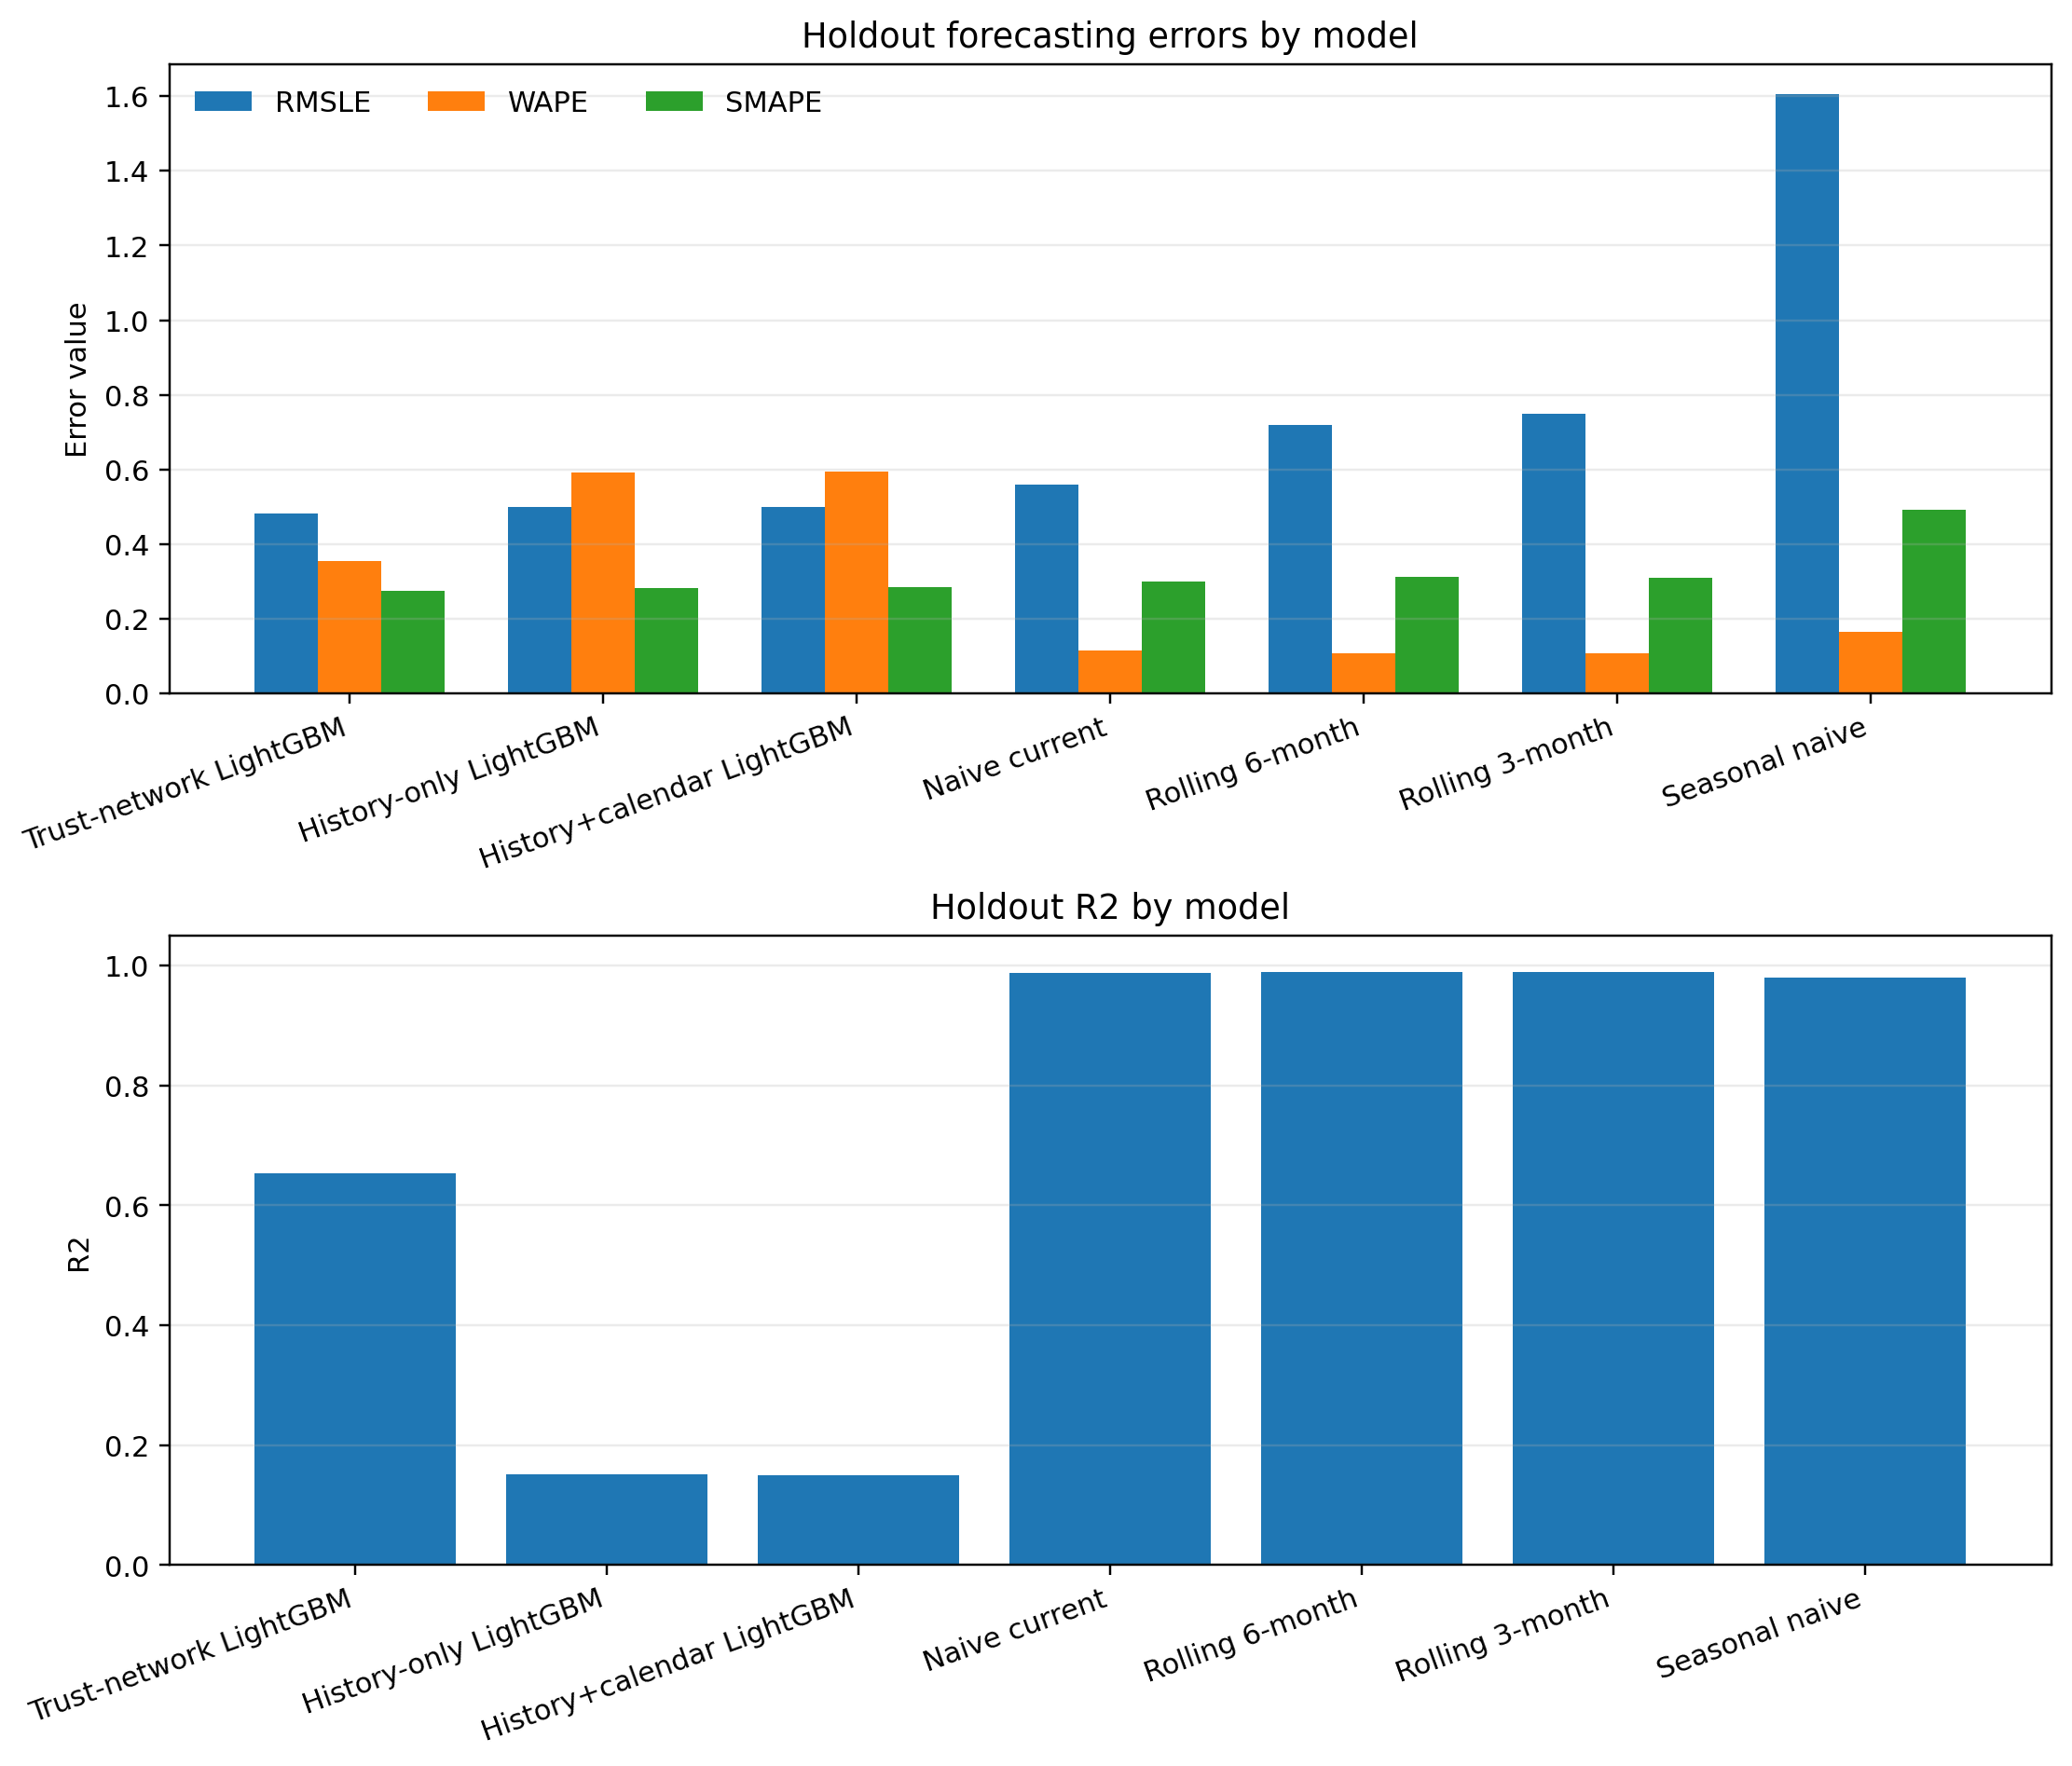

Fig6_monitoring_priority_tiers.png


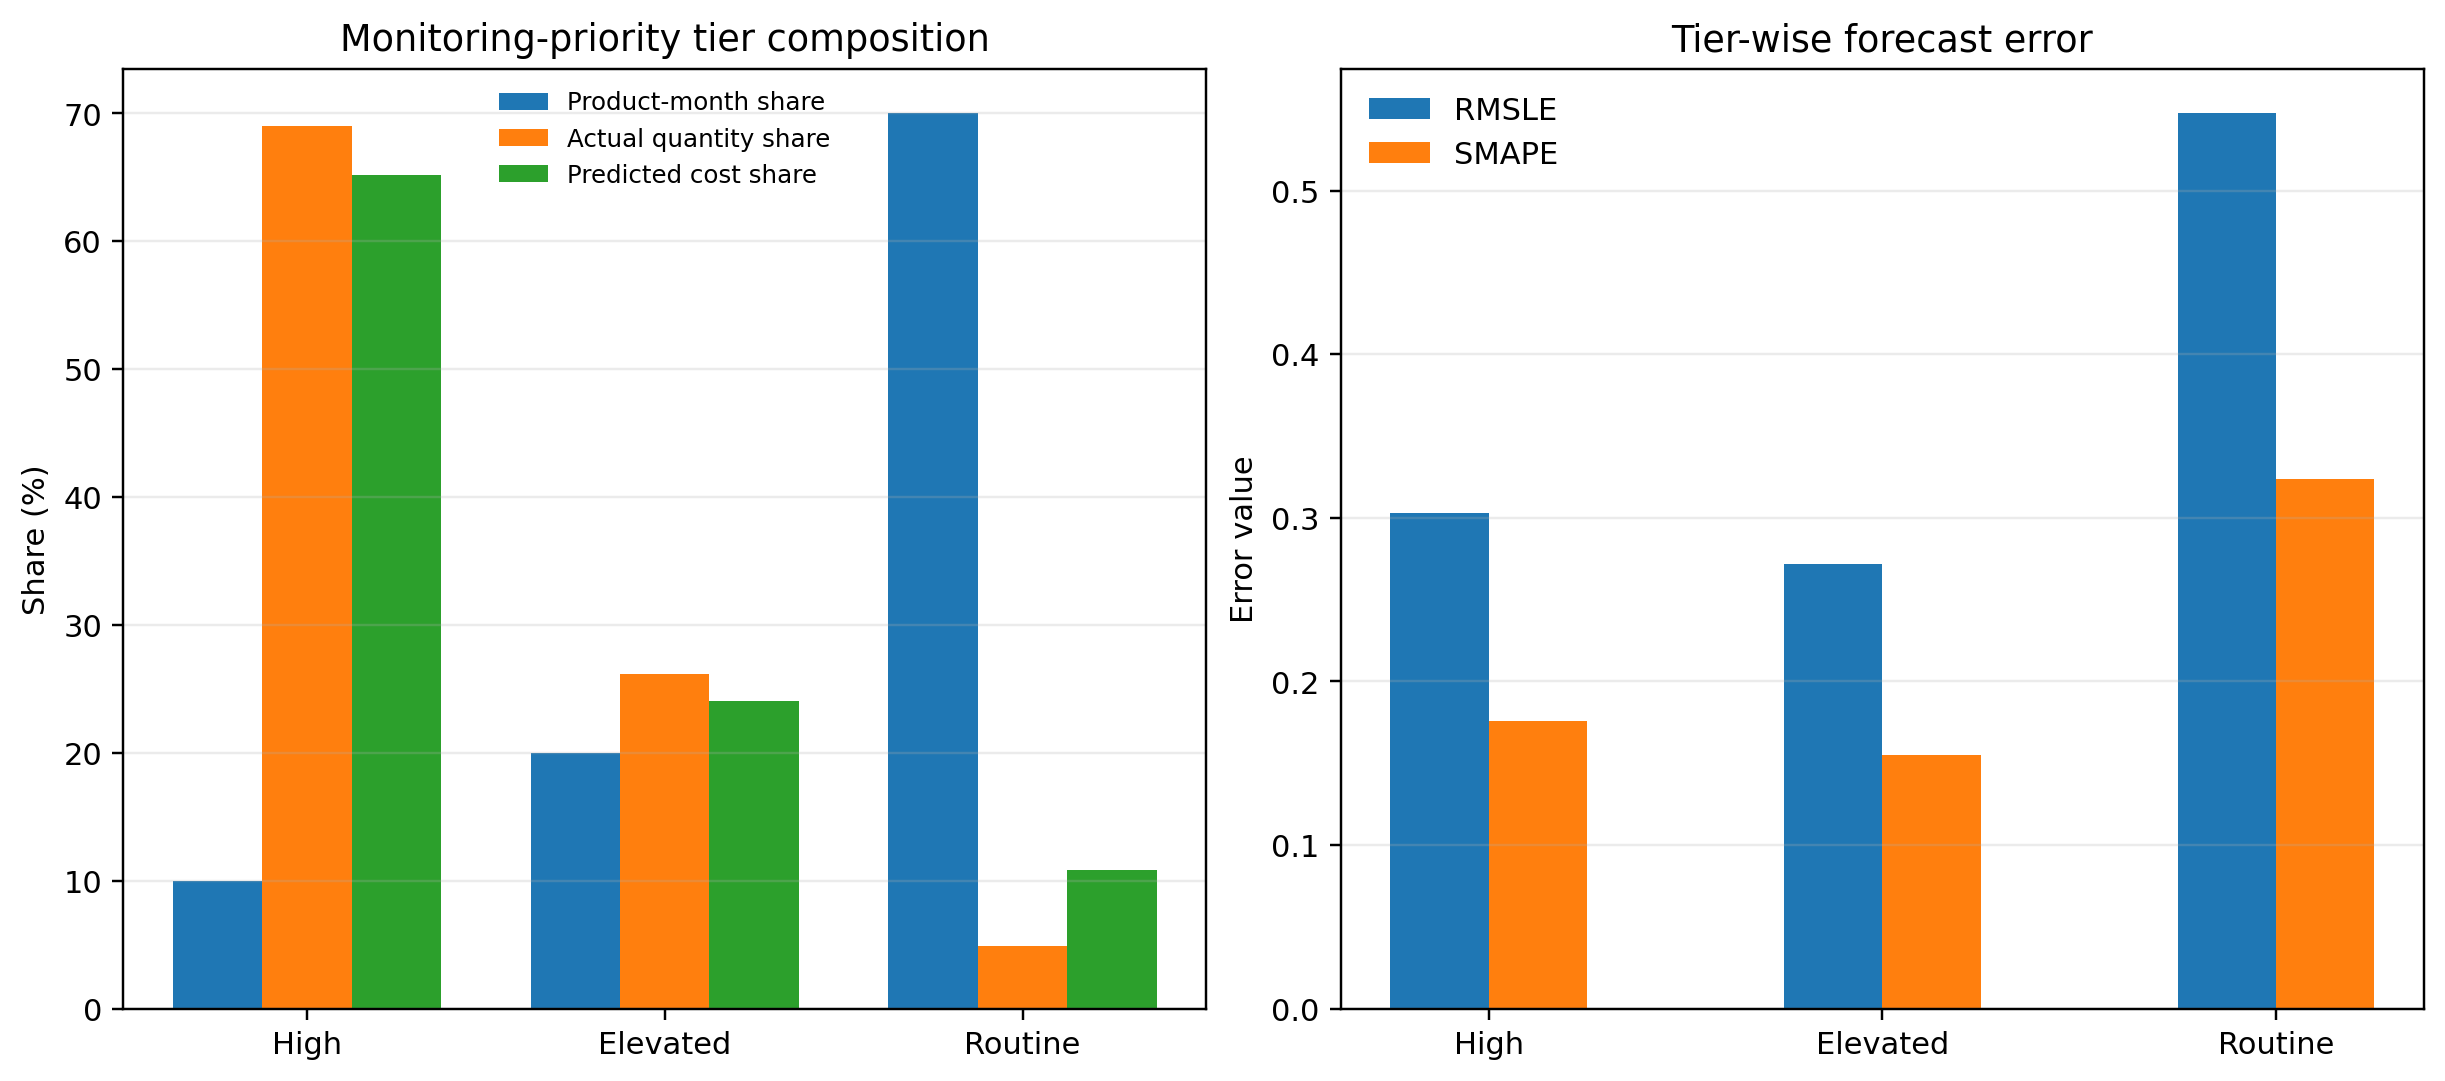

Fig7_feature_importance.png


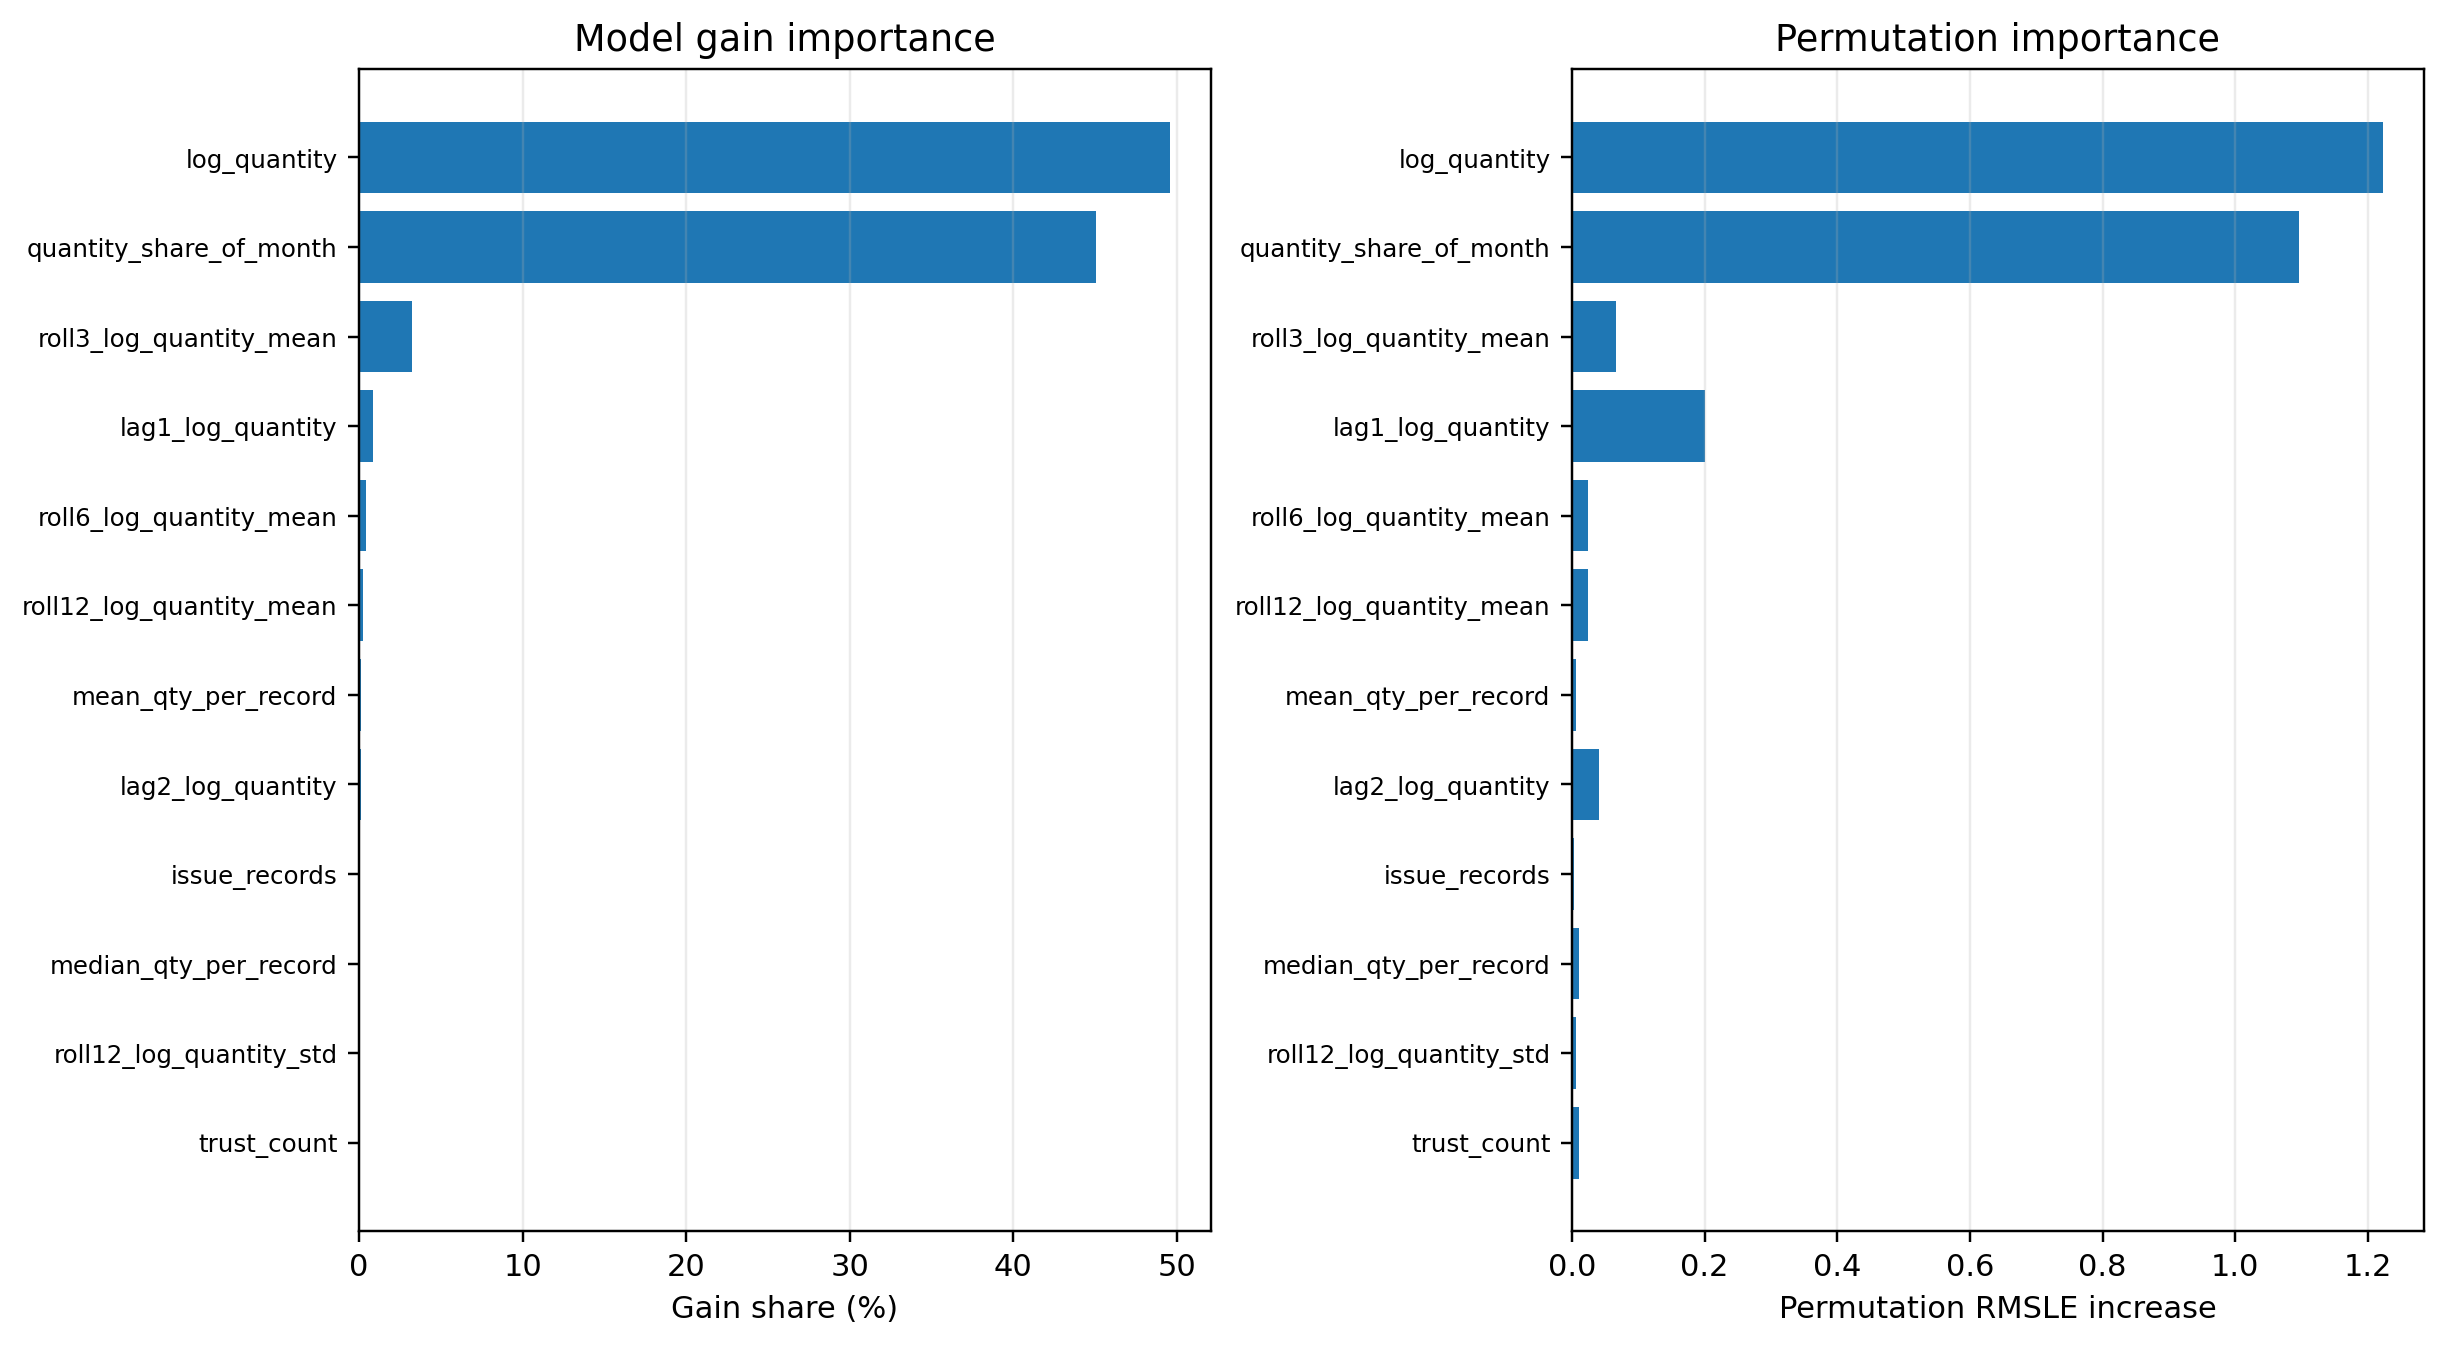

FigS1_SHAP_global_bar_holdout_subset.png


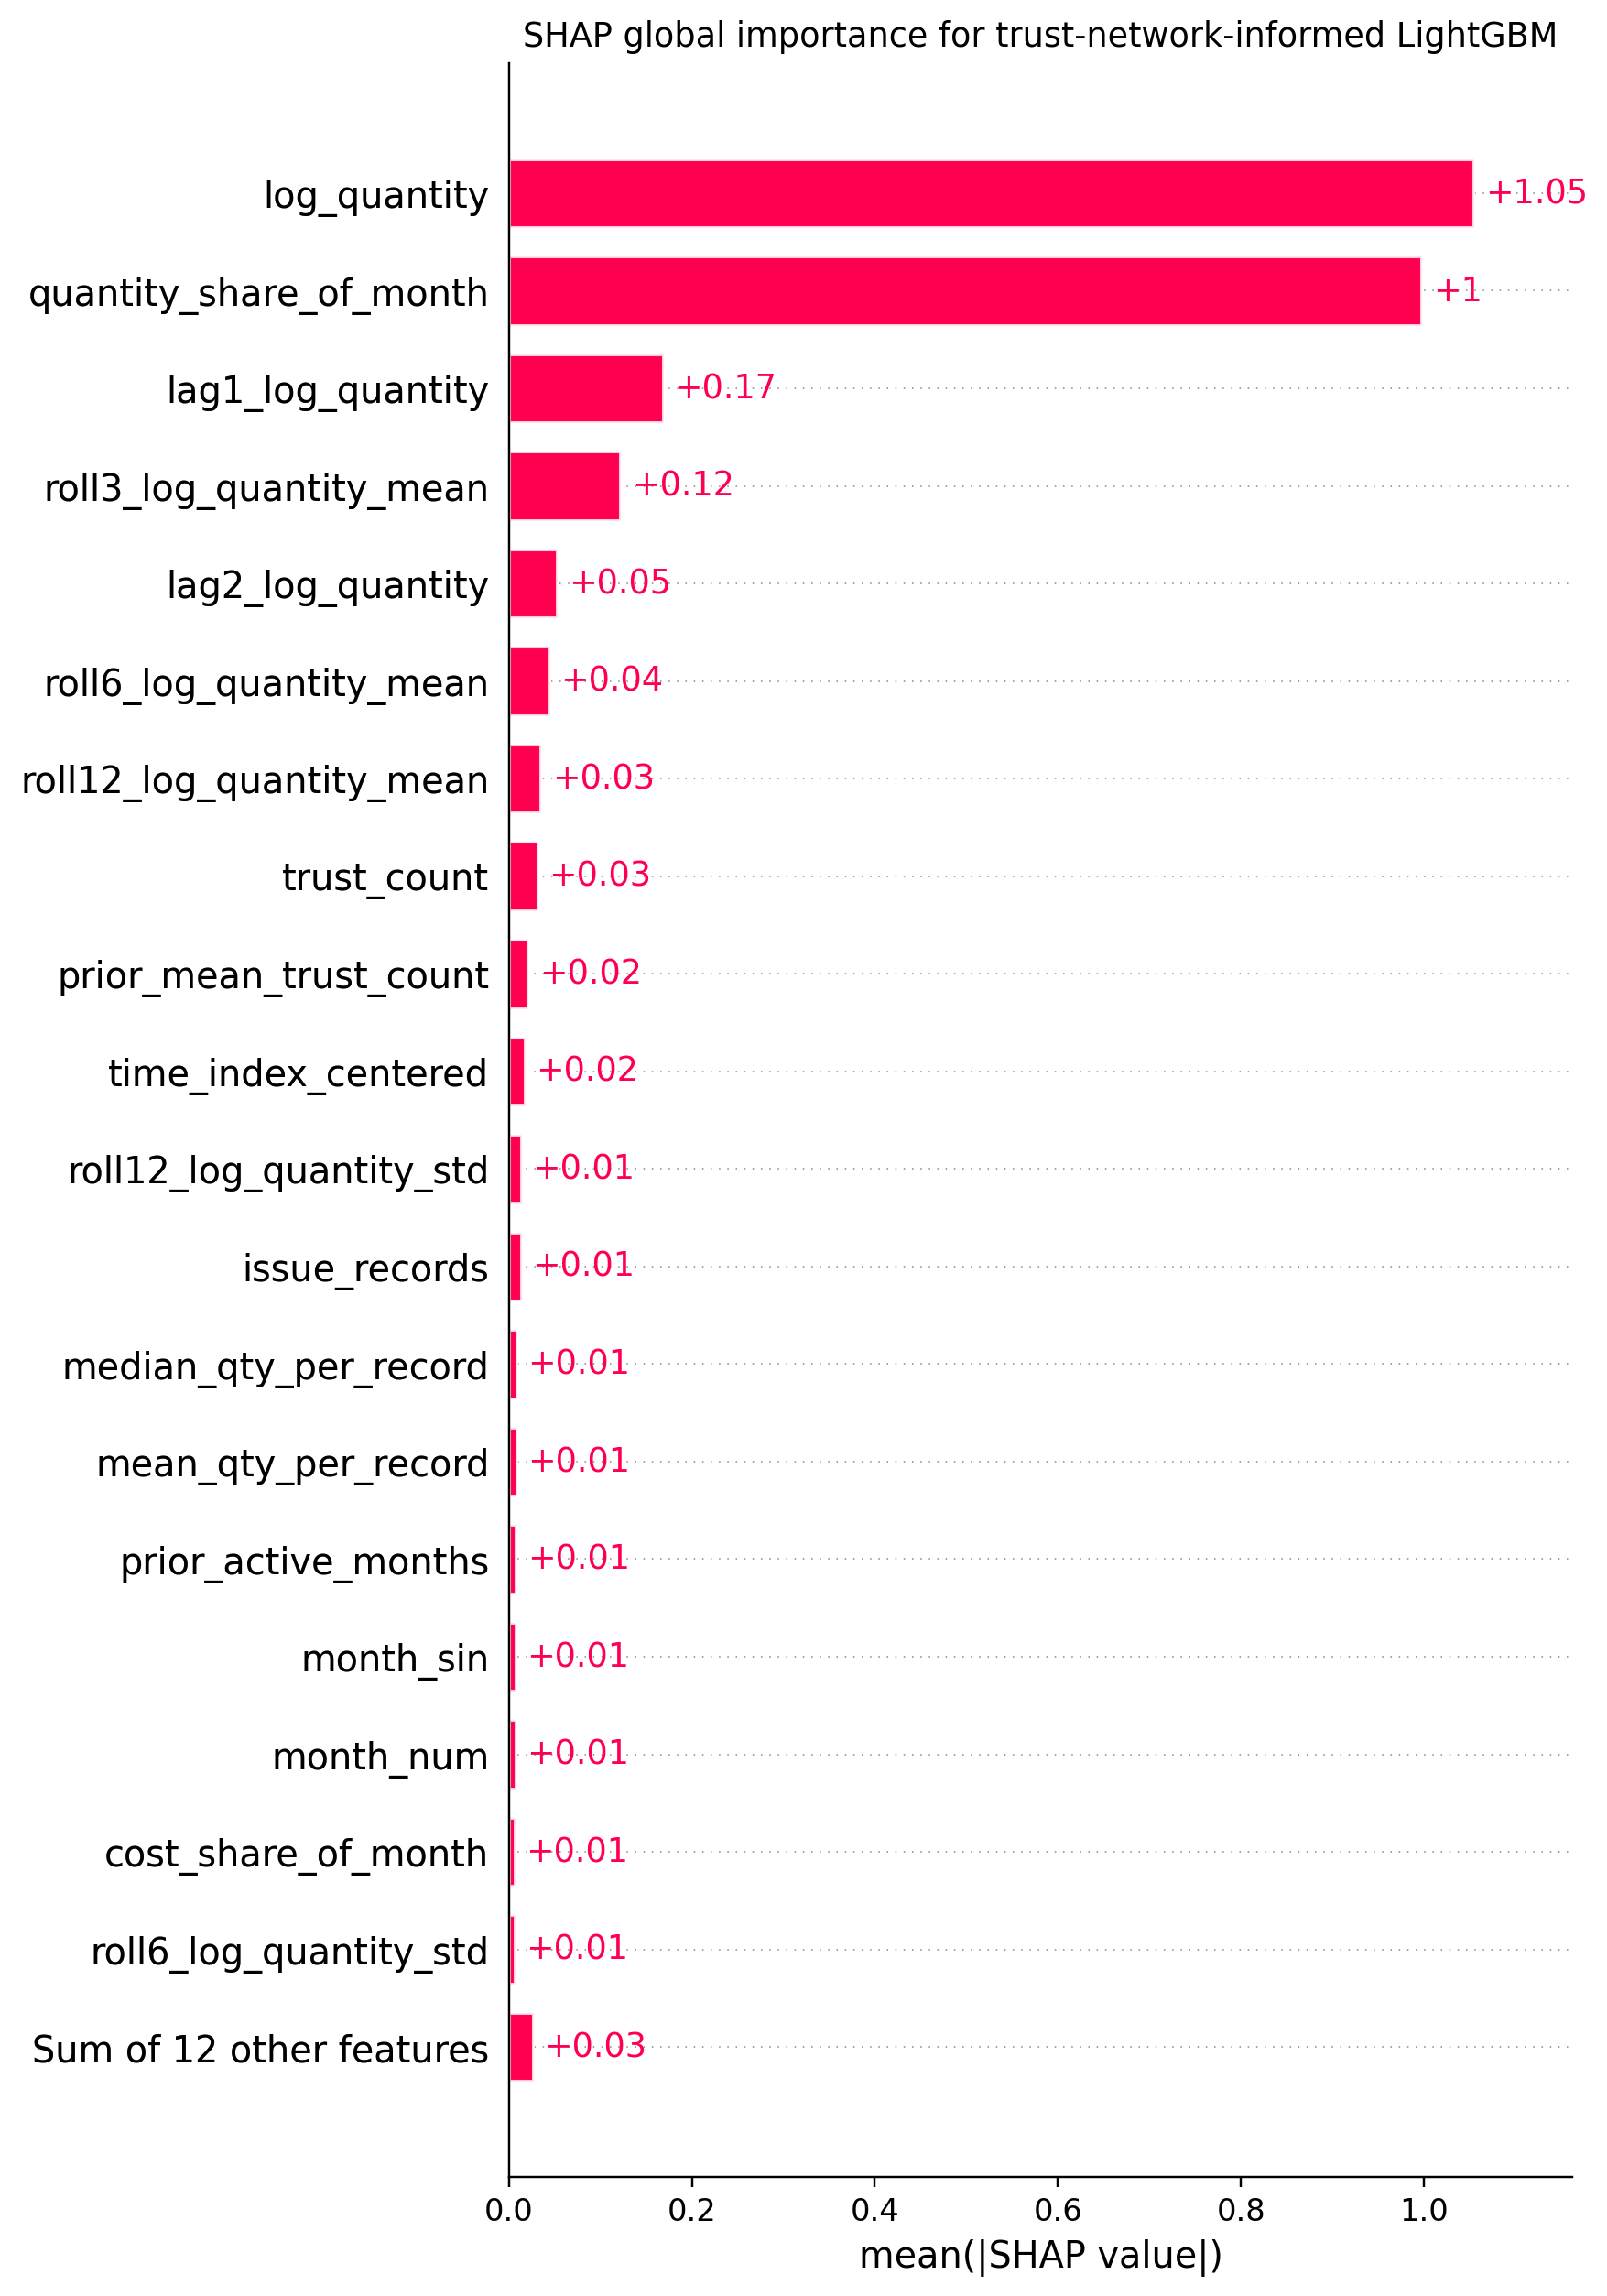

FigS2_SHAP_beeswarm_holdout_subset.png


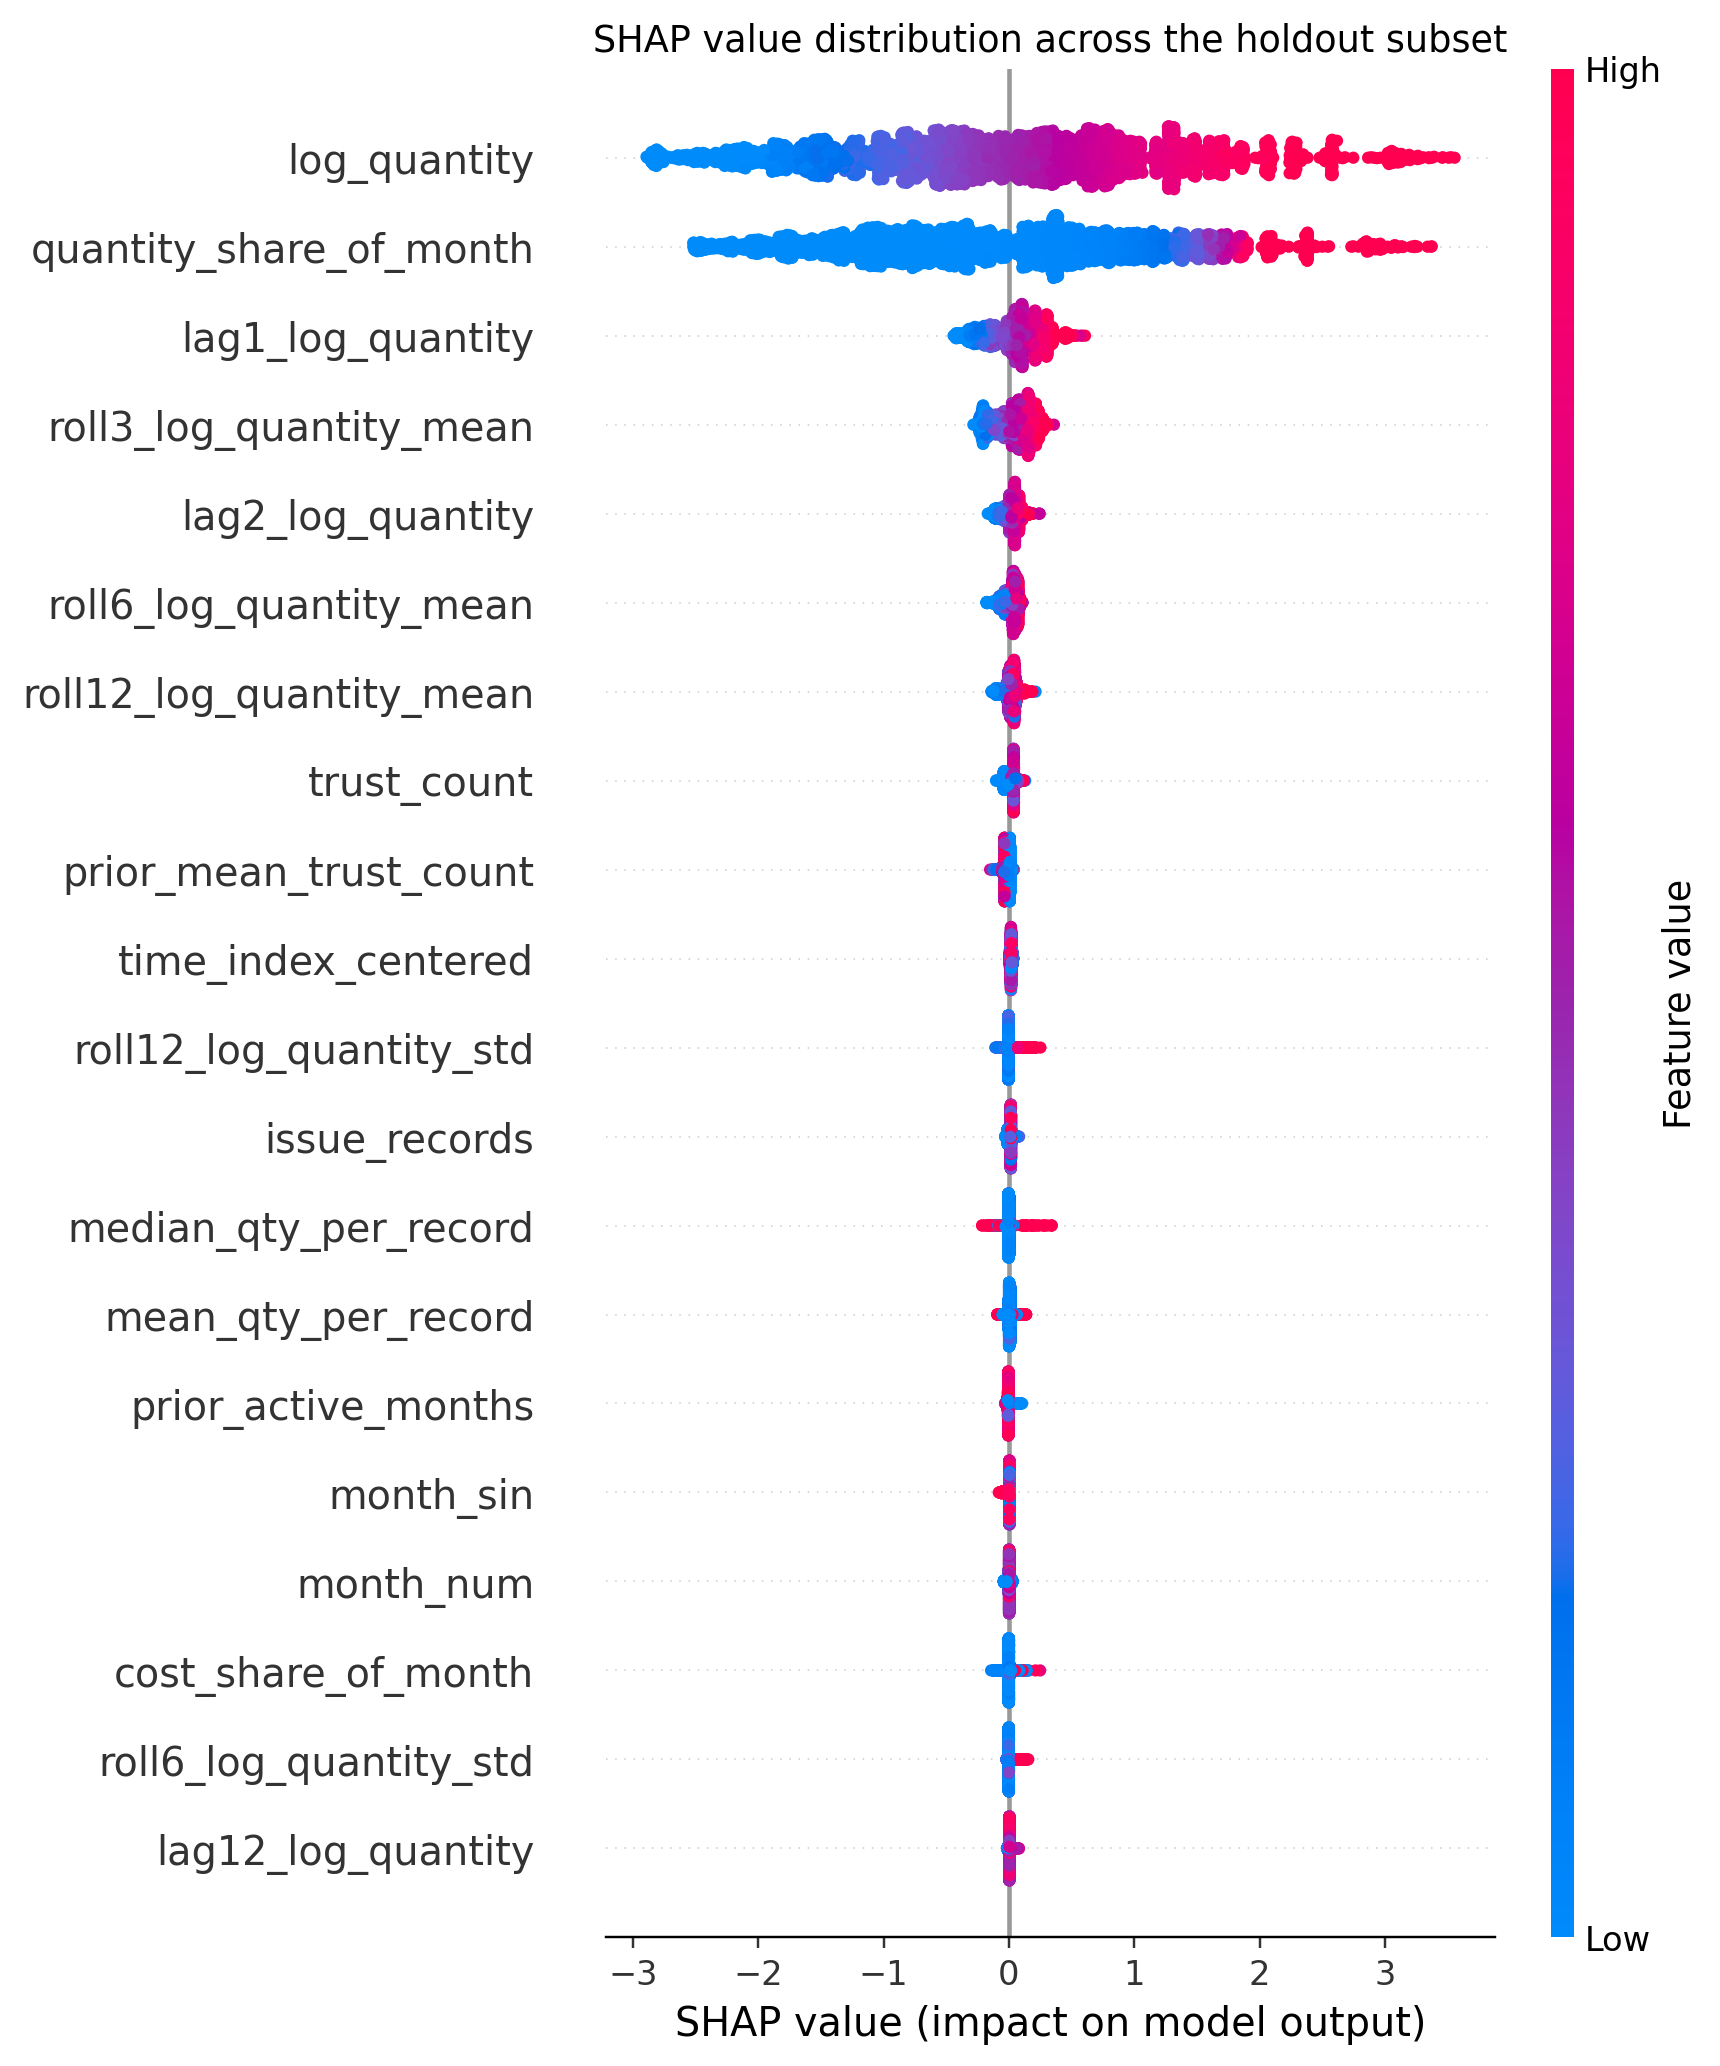

FigS3_SHAP_local_waterfall_representative_product_month.png


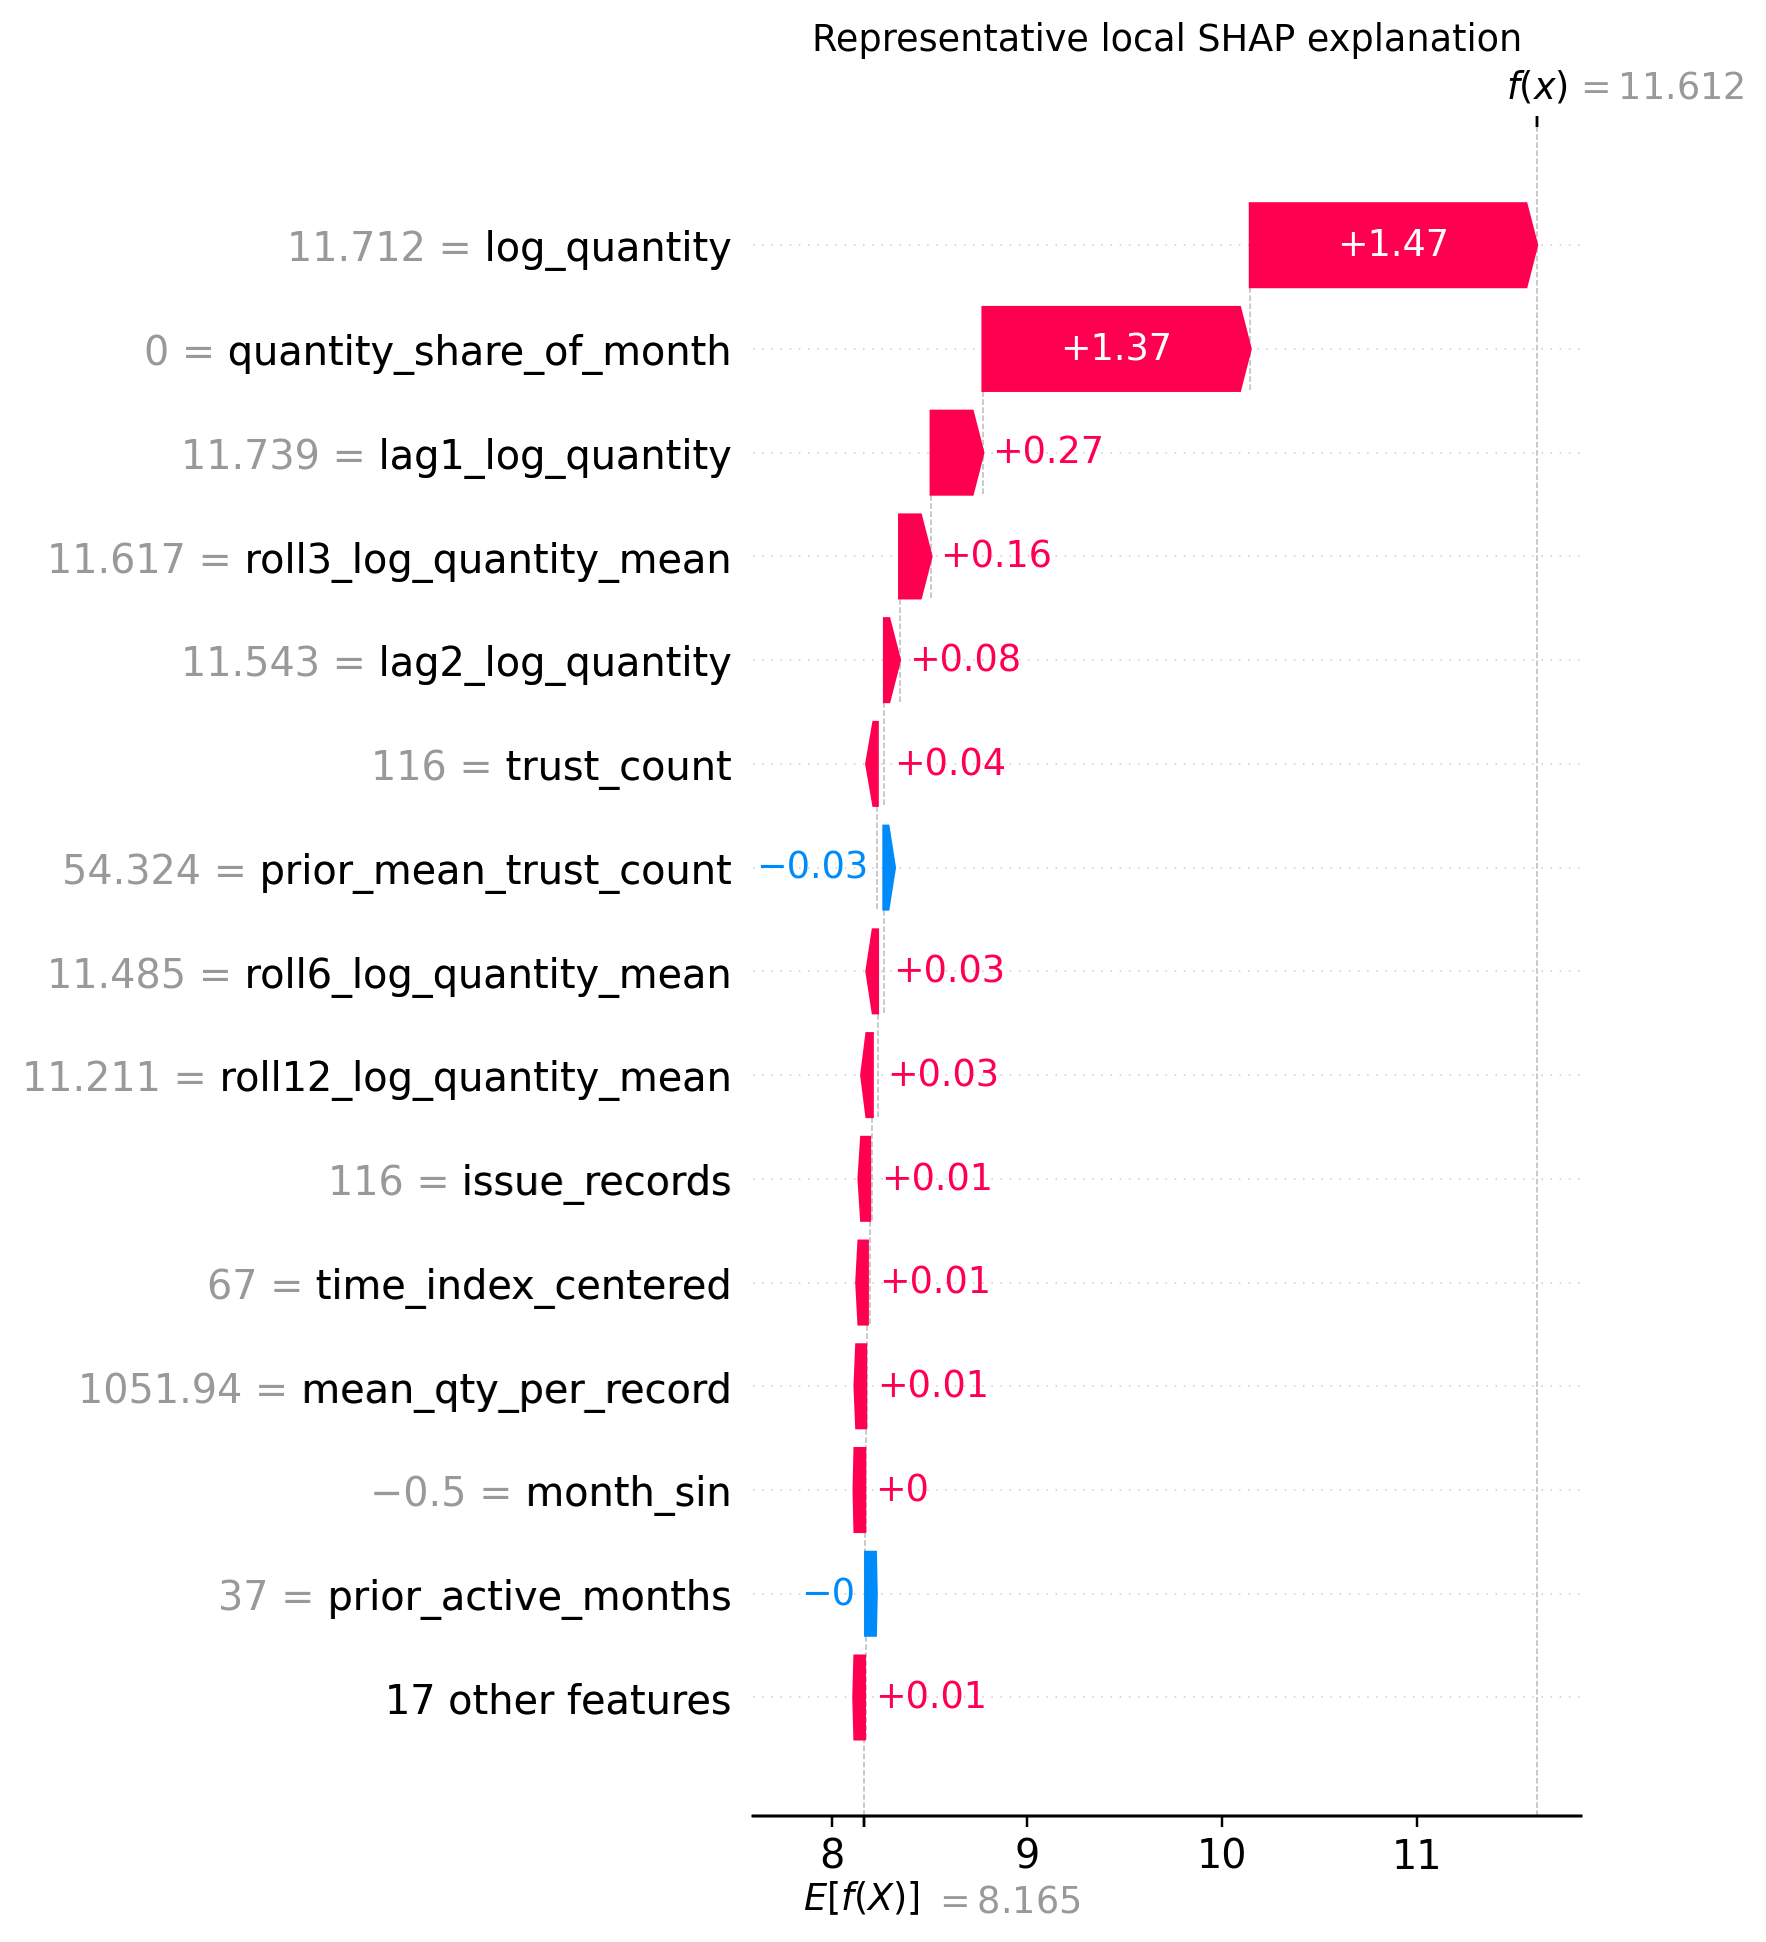

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display as show

figdir = run.figures
figdir.mkdir(parents=True, exist_ok=True)

# Fig. 1 Monthly quantity trend
m = monthly.sort_values('year_month').copy()
m['date'] = pd.to_datetime(m['year_month'].astype(str) + '01', format='%Y%m%d')
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(m['date'], m['total_quantity'], marker='o', linewidth=1.4)
ax.set_title('Monthly issued quantity')
ax.set_xlabel('Month')
ax.set_ylabel('Total quantity')
ax.grid(True, alpha=0.25)
fig.autofmt_xdate()
fig.savefig(figdir / 'Fig1_monthly_quantity_trend.png', dpi=220, bbox_inches='tight')
plt.close(fig)

# Fig. 2 Monthly indicative cost trend
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(m['date'], m['total_indicative_cost'], marker='o', linewidth=1.4)
ax.set_title('Monthly indicative cost')
ax.set_xlabel('Month')
ax.set_ylabel('Total indicative cost')
ax.grid(True, alpha=0.25)
fig.autofmt_xdate()
fig.savefig(figdir / 'Fig2_monthly_cost_trend.png', dpi=220, bbox_inches='tight')
plt.close(fig)

# Fig. 3 Distribution before and after log transformation
actual = predictions.loc[predictions['model'].eq('lightgbm_trust_network_informed'), 'actual'].to_numpy(float)
log_actual = np.log1p(actual)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
axes[0].hist(actual, bins=80)
axes[0].set_title('Raw target quantity')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Count')
axes[0].set_yscale('log')
axes[0].grid(True, alpha=0.25)
axes[1].hist(log_actual, bins=80)
axes[1].set_title('log(1 + quantity)')
axes[1].set_xlabel('log(1 + quantity)')
axes[1].set_ylabel('Count')
axes[1].grid(True, alpha=0.25)
fig.savefig(figdir / 'Fig3_distribution_before_after_log.png', dpi=220, bbox_inches='tight')
plt.close(fig)

# Fig. 4 Research workflow
fig, ax = plt.subplots(figsize=(8.0, 9.5))
ax.axis('off')
steps = [
    ('Phase 1: Data and descriptive analysis', 'Research aim\nForecast hospital medicine demand under uncertainty.'),
    ('', 'Data source and preparation\n72 SCMD files; clean and create product-unit keys.'),
    ('', 'Descriptive analysis\nProfile missingness, trends, concentration, volatility and networks.'),
    ('Phase 2: Model development and validation', 'Panel and feature engineering\nBuild product-month panel with lags, rolling means, cost and Trust coverage.'),
    ('', 'Model development and validation\nBenchmark rolling baselines and LightGBM models using temporal validation.'),
    ('', 'Model interpretation\nAssess feature importance, ablation and segment-level behaviour.'),
    ('Phase 3: Decision support and research outputs', 'Decision-support output\nClassify products into High, Elevated and Routine monitoring priorities.'),
]
y = 0.94
for idx, (phase, text) in enumerate(steps, 1):
    if phase:
        ax.text(0.5, y, phase, ha='center', va='center', fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='black'))
        y -= 0.065
    ax.text(0.08, y, str(idx), ha='center', va='center', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='circle,pad=0.28', facecolor='white', edgecolor='black'))
    ax.text(0.5, y, text, ha='center', va='center', fontsize=9.5,
            bbox=dict(boxstyle='round,pad=0.55', facecolor='white', edgecolor='black'))
    if idx < len(steps):
        ax.annotate('', xy=(0.5, y-0.055), xytext=(0.5, y-0.025), arrowprops=dict(arrowstyle='->', lw=1.2))
    y -= 0.12
ax.text(0.5, 0.04, 'Core target: next-month product-level issued quantity', ha='center', va='center', fontsize=10,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='black', linestyle='--'))
fig.savefig(figdir / 'Fig4_revised_workflow.png', dpi=220, bbox_inches='tight')
plt.close(fig)

# Fig. 5 Holdout validation results
plot_df = comparison.copy()
label_map = {
    'lightgbm_trust_network_informed':'Trust-network LightGBM',
    'lightgbm_history_only':'History-only LightGBM',
    'lightgbm_history_calendar':'History+calendar LightGBM',
    'rolling3_quantity_mean':'Rolling 3-month',
    'rolling6_quantity_mean':'Rolling 6-month',
    'naive_current_quantity':'Naive current',
    'seasonal12_quantity':'Seasonal naive',
}
plot_df['label'] = plot_df['model'].map(label_map).fillna(plot_df['model'])
fig, axes = plt.subplots(2, 1, figsize=(10, 8.5), constrained_layout=True)
x = np.arange(len(plot_df))
width = 0.25
axes[0].bar(x-width, plot_df['RMSLE'], width, label='RMSLE')
axes[0].bar(x, plot_df['WAPE'], width, label='WAPE')
axes[0].bar(x+width, plot_df['SMAPE'], width, label='SMAPE')
axes[0].set_ylabel('Error value')
axes[0].set_title('Holdout forecasting errors by model')
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_df['label'], rotation=20, ha='right')
axes[0].legend(frameon=False, ncol=3)
axes[0].grid(axis='y', alpha=0.25)
axes[1].bar(x, plot_df['R2'])
axes[1].set_ylabel('R2')
axes[1].set_title('Holdout R2 by model')
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot_df['label'], rotation=20, ha='right')
axes[1].grid(axis='y', alpha=0.25)
fig.savefig(figdir / 'Fig5_holdout_validation_results.png', dpi=220, bbox_inches='tight')
plt.close(fig)

# Fig. 6 Monitoring priority tiers
ts = tier_summary.copy()
ts['short_tier'] = ts['monitoring_tier'].str.replace(' monitoring priority','', regex=False).str.replace(' monitoring','', regex=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
x = np.arange(len(ts)); width = 0.25
axes[0].bar(x-width, ts['product_month_share']*100, width, label='Product-month share')
axes[0].bar(x, ts['actual_quantity_share']*100, width, label='Actual quantity share')
axes[0].bar(x+width, ts['predicted_cost_share']*100, width, label='Predicted cost share')
axes[0].set_xticks(x); axes[0].set_xticklabels(ts['short_tier'])
axes[0].set_ylabel('Share (%)')
axes[0].set_title('Monitoring-priority tier composition')
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(axis='y', alpha=0.25)
axes[1].bar(x-width/2, ts['RMSLE'], width, label='RMSLE')
axes[1].bar(x+width/2, ts['SMAPE'], width, label='SMAPE')
axes[1].set_xticks(x); axes[1].set_xticklabels(ts['short_tier'])
axes[1].set_ylabel('Error value')
axes[1].set_title('Tier-wise forecast error')
axes[1].legend(frameon=False)
axes[1].grid(axis='y', alpha=0.25)
fig.savefig(figdir / 'Fig6_monitoring_priority_tiers.png', dpi=220, bbox_inches='tight')
plt.close(fig)

# Fig. 7 Variable importance
imp = importance[['feature', 'gain_share']].copy()
perm = permutation[['feature', 'mean_rmsle_increase']].copy()
merged = imp.merge(perm, on='feature', how='left').sort_values('gain_share', ascending=False).head(12)
y = np.arange(len(merged))
fig, axes = plt.subplots(1, 2, figsize=(11, 6), constrained_layout=True)
axes[0].barh(y, merged['gain_share']*100)
axes[0].set_yticks(y); axes[0].set_yticklabels(merged['feature'], fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlabel('Gain share (%)')
axes[0].set_title('Model gain importance')
axes[0].grid(axis='x', alpha=0.25)
axes[1].barh(y, merged['mean_rmsle_increase'])
axes[1].set_yticks(y); axes[1].set_yticklabels(merged['feature'], fontsize=8)
axes[1].invert_yaxis()
axes[1].set_xlabel('Permutation RMSLE increase')
axes[1].set_title('Permutation importance')
axes[1].grid(axis='x', alpha=0.25)
fig.savefig(figdir / 'Fig7_feature_importance.png', dpi=220, bbox_inches='tight')
plt.close(fig)

for path in sorted(figdir.glob('*.png')):
    print(path.name)
    show(Image(filename=str(path)))

Displaying descriptive analysis figures again:
 - Fig1_monthly_quantity_trend.png


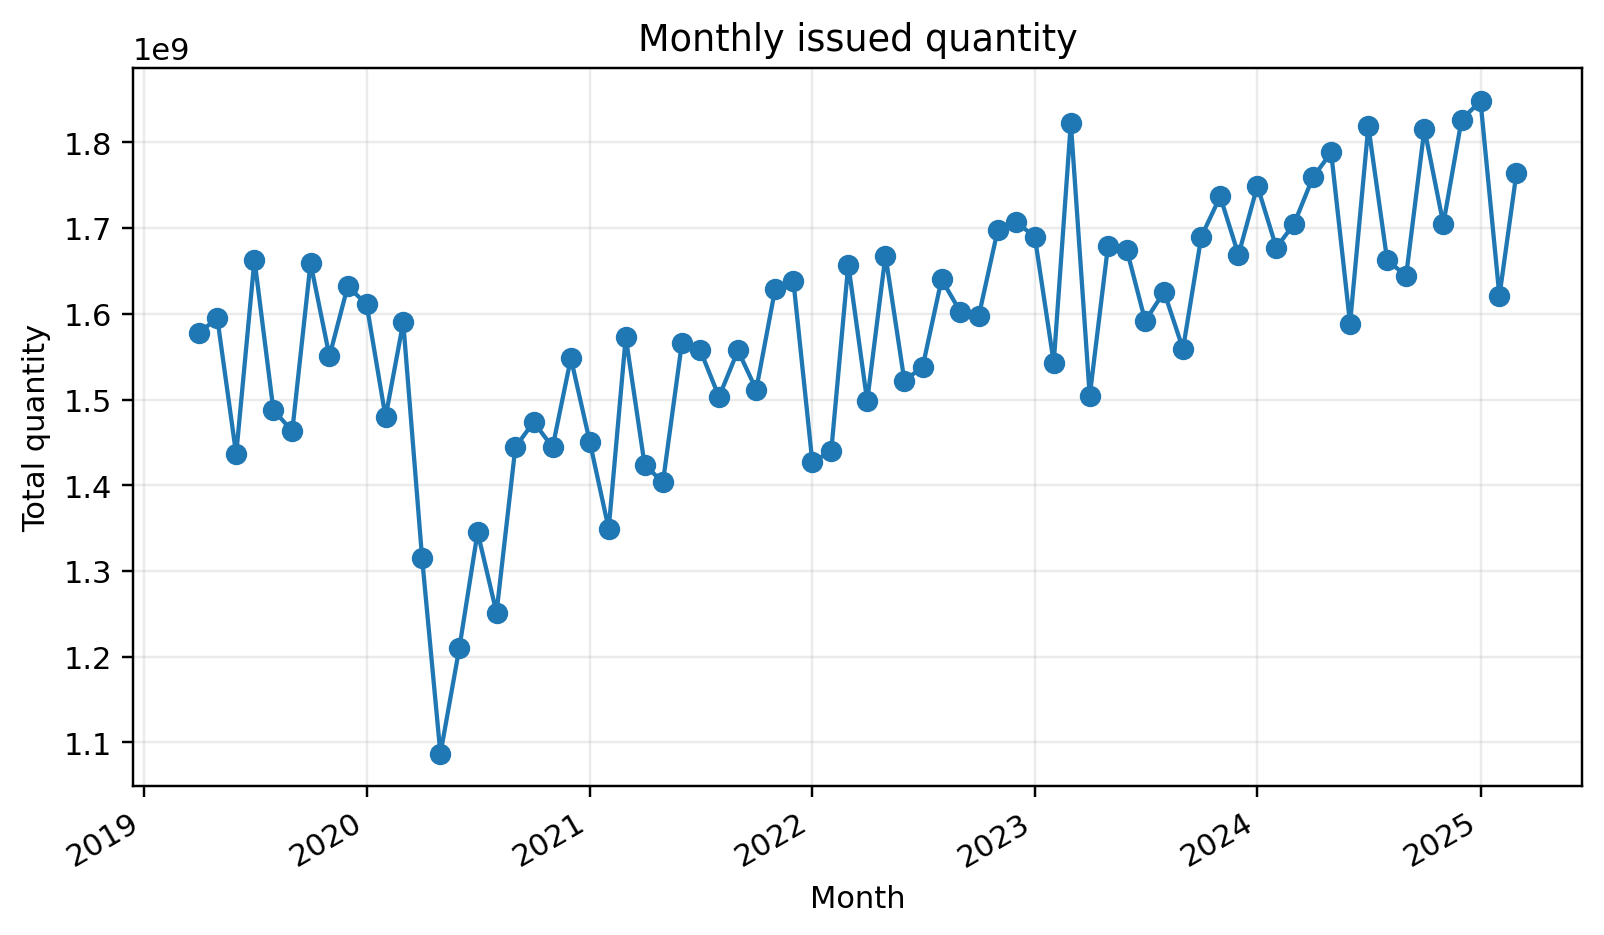

 - Fig2_monthly_cost_trend.png


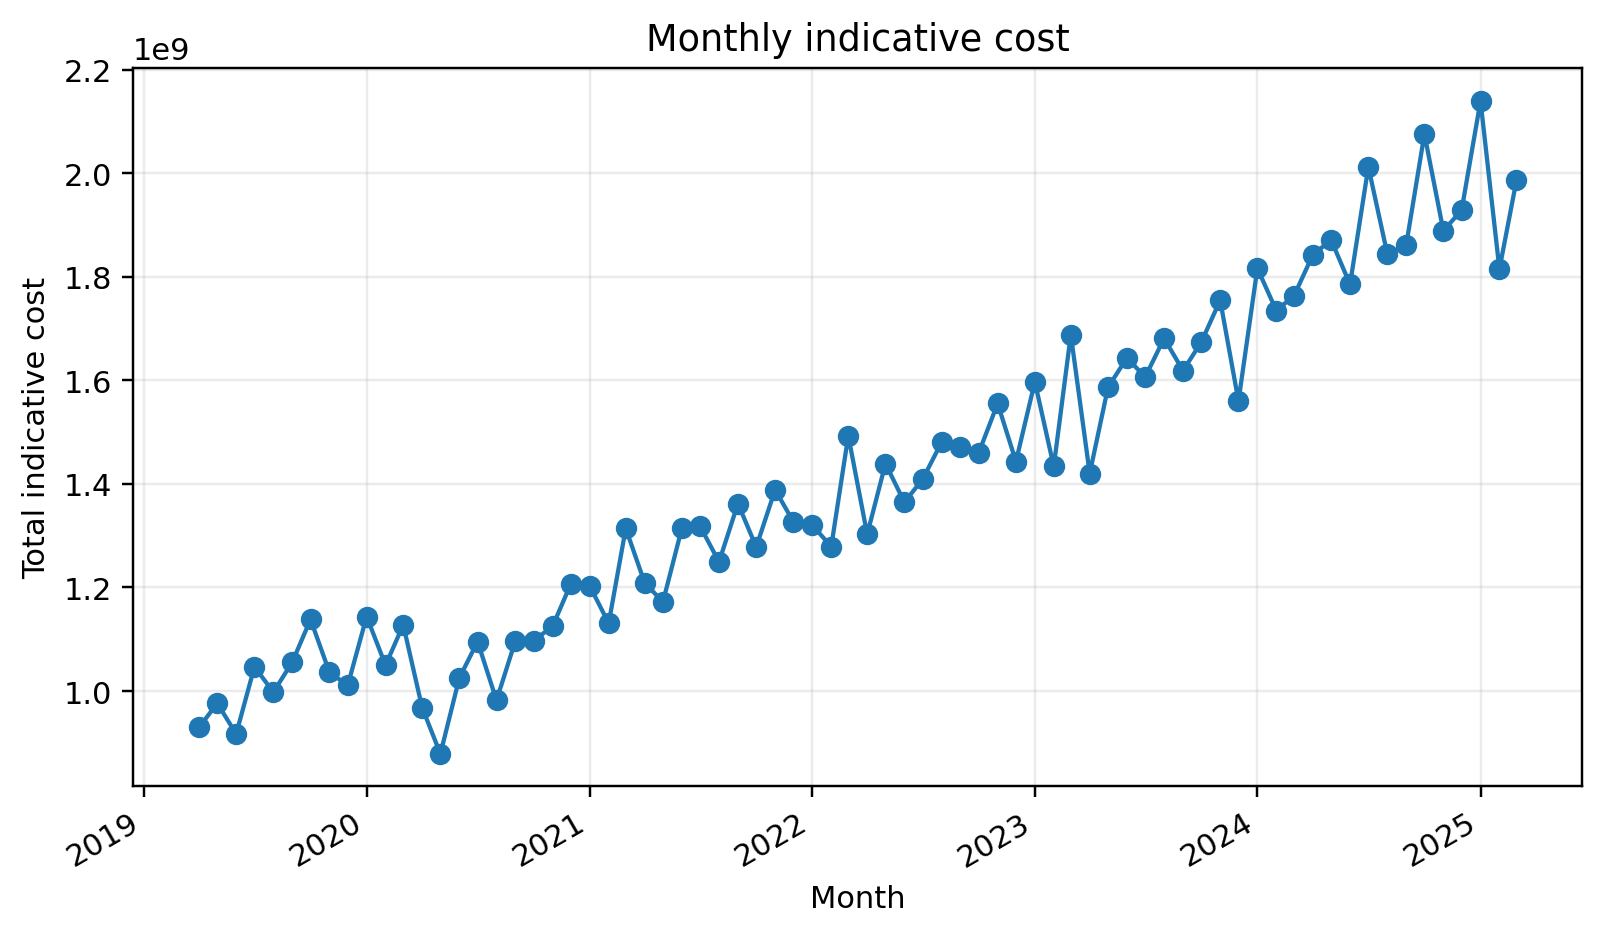

 - Fig3_distribution_before_after_log.png


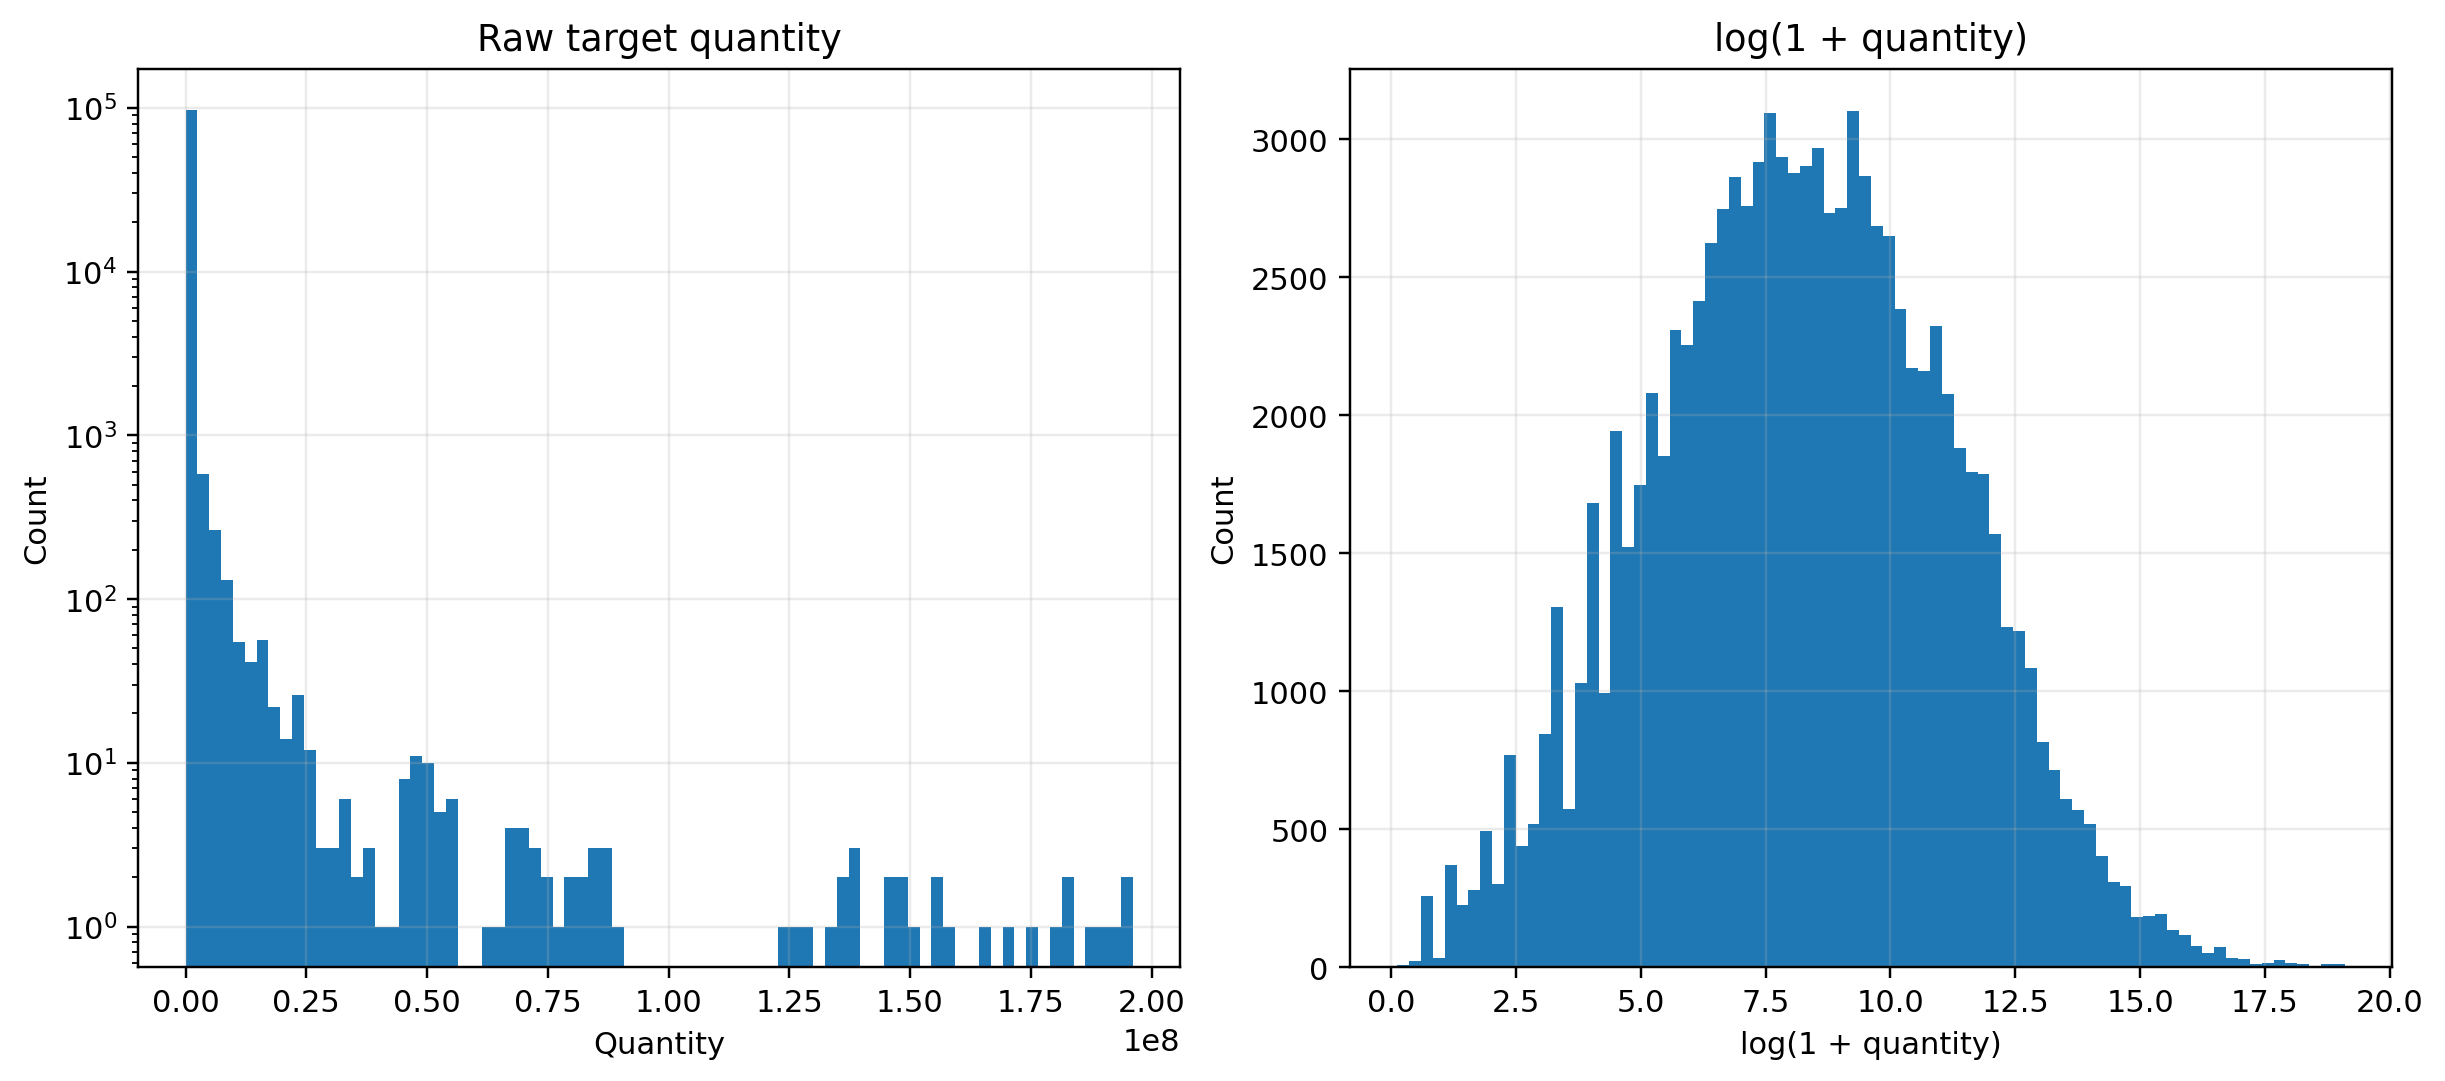

 - Fig4_revised_workflow.png


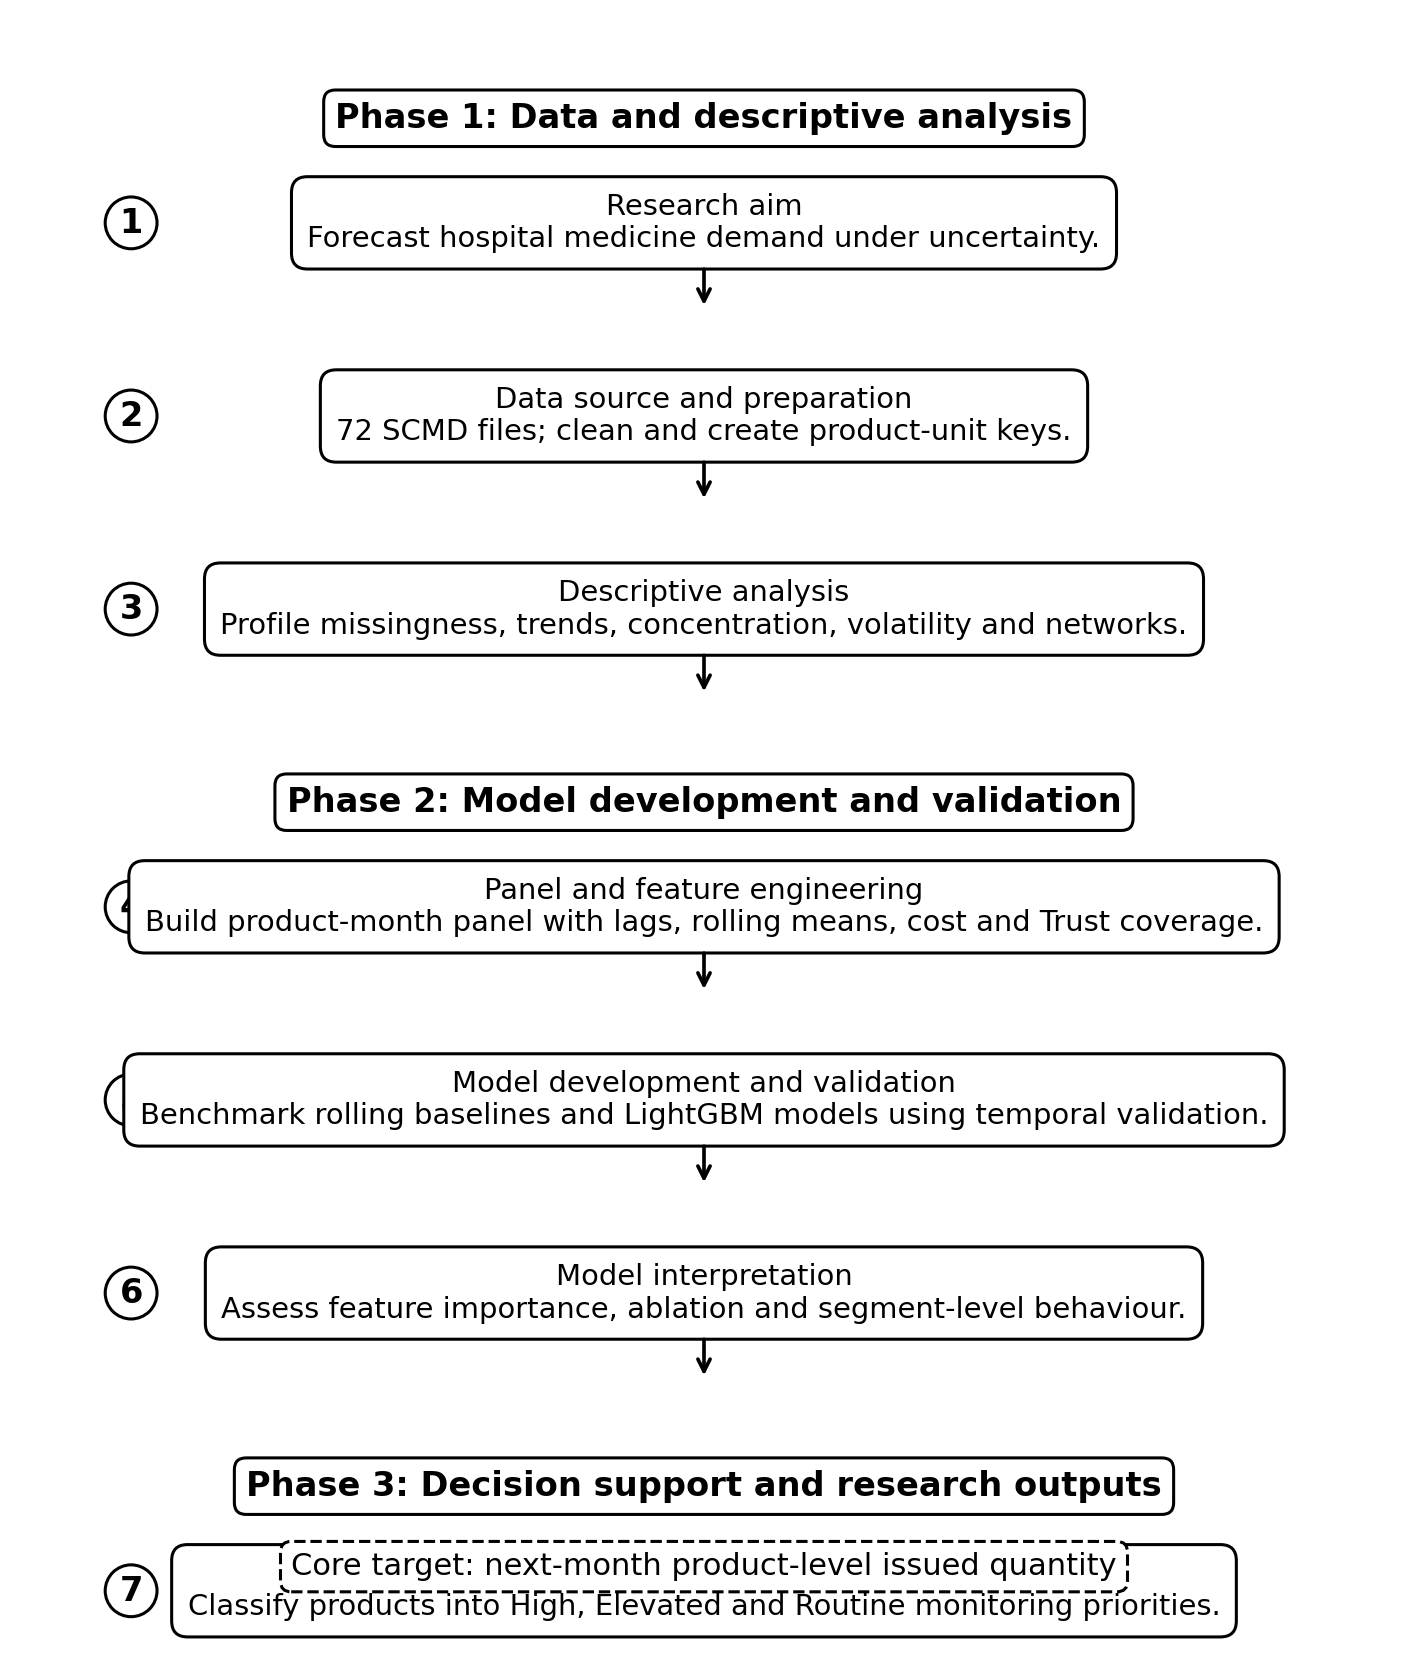

 - Fig5_holdout_validation_results.png


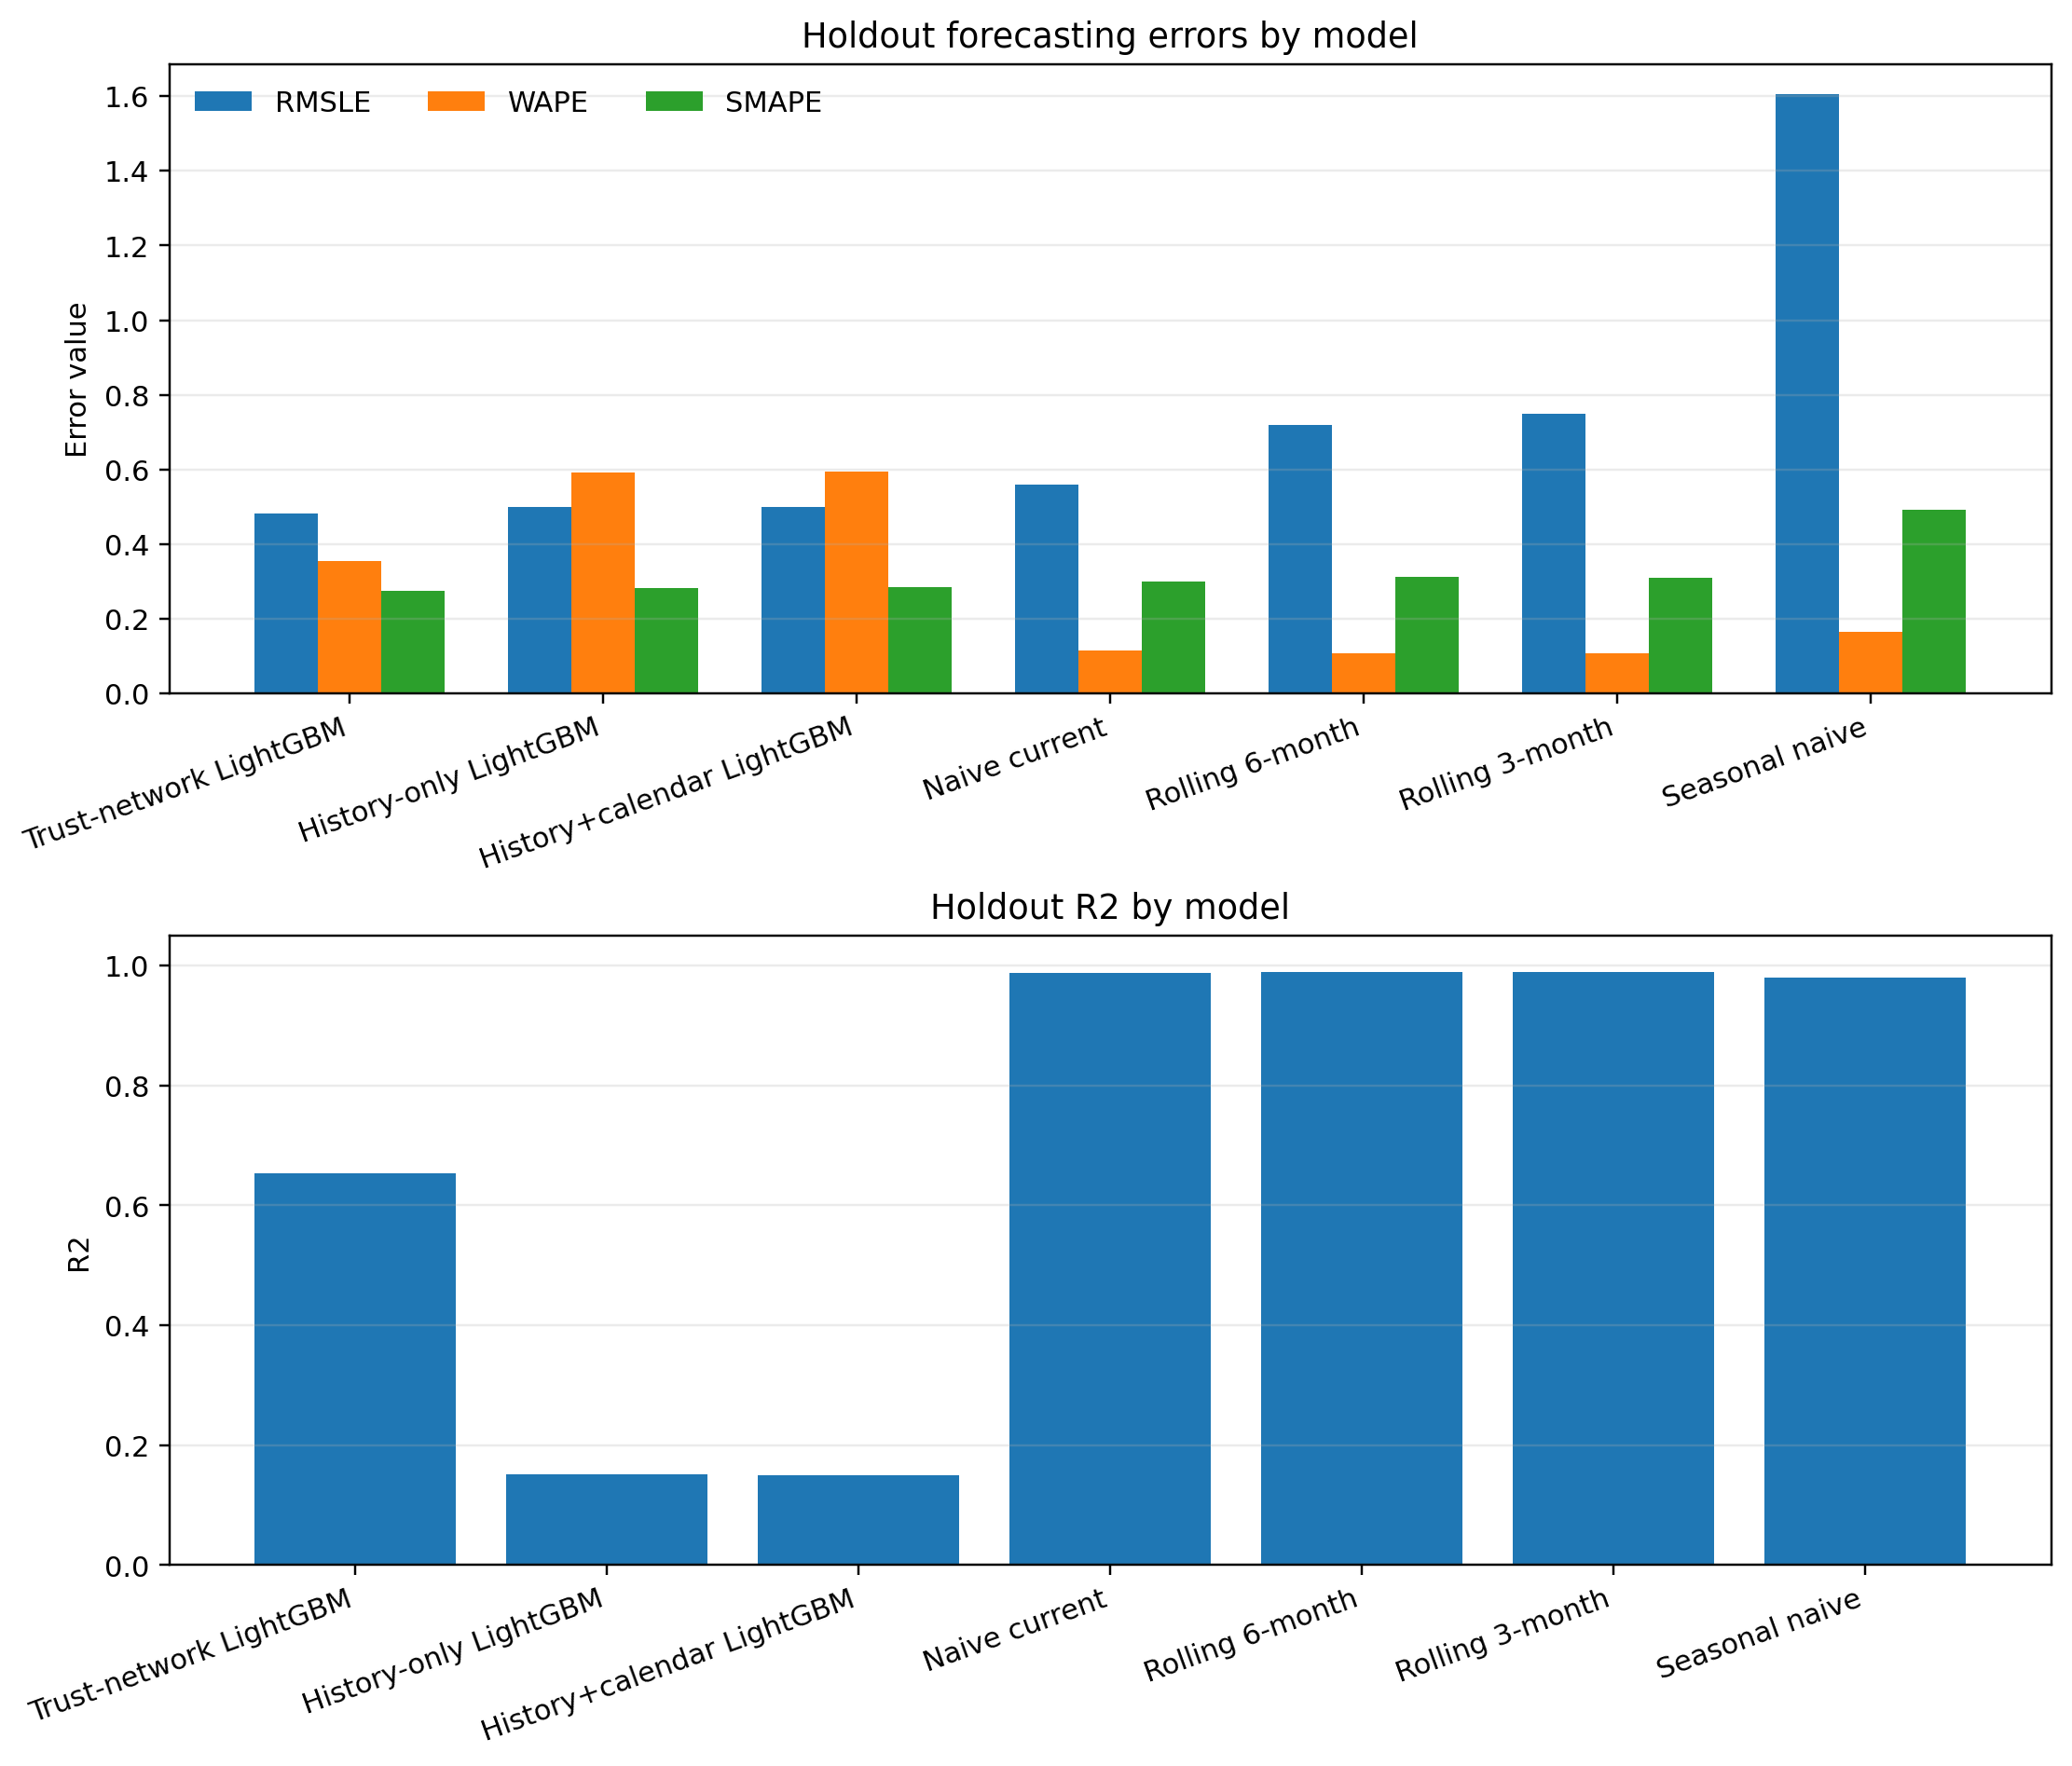

 - Fig6_monitoring_priority_tiers.png


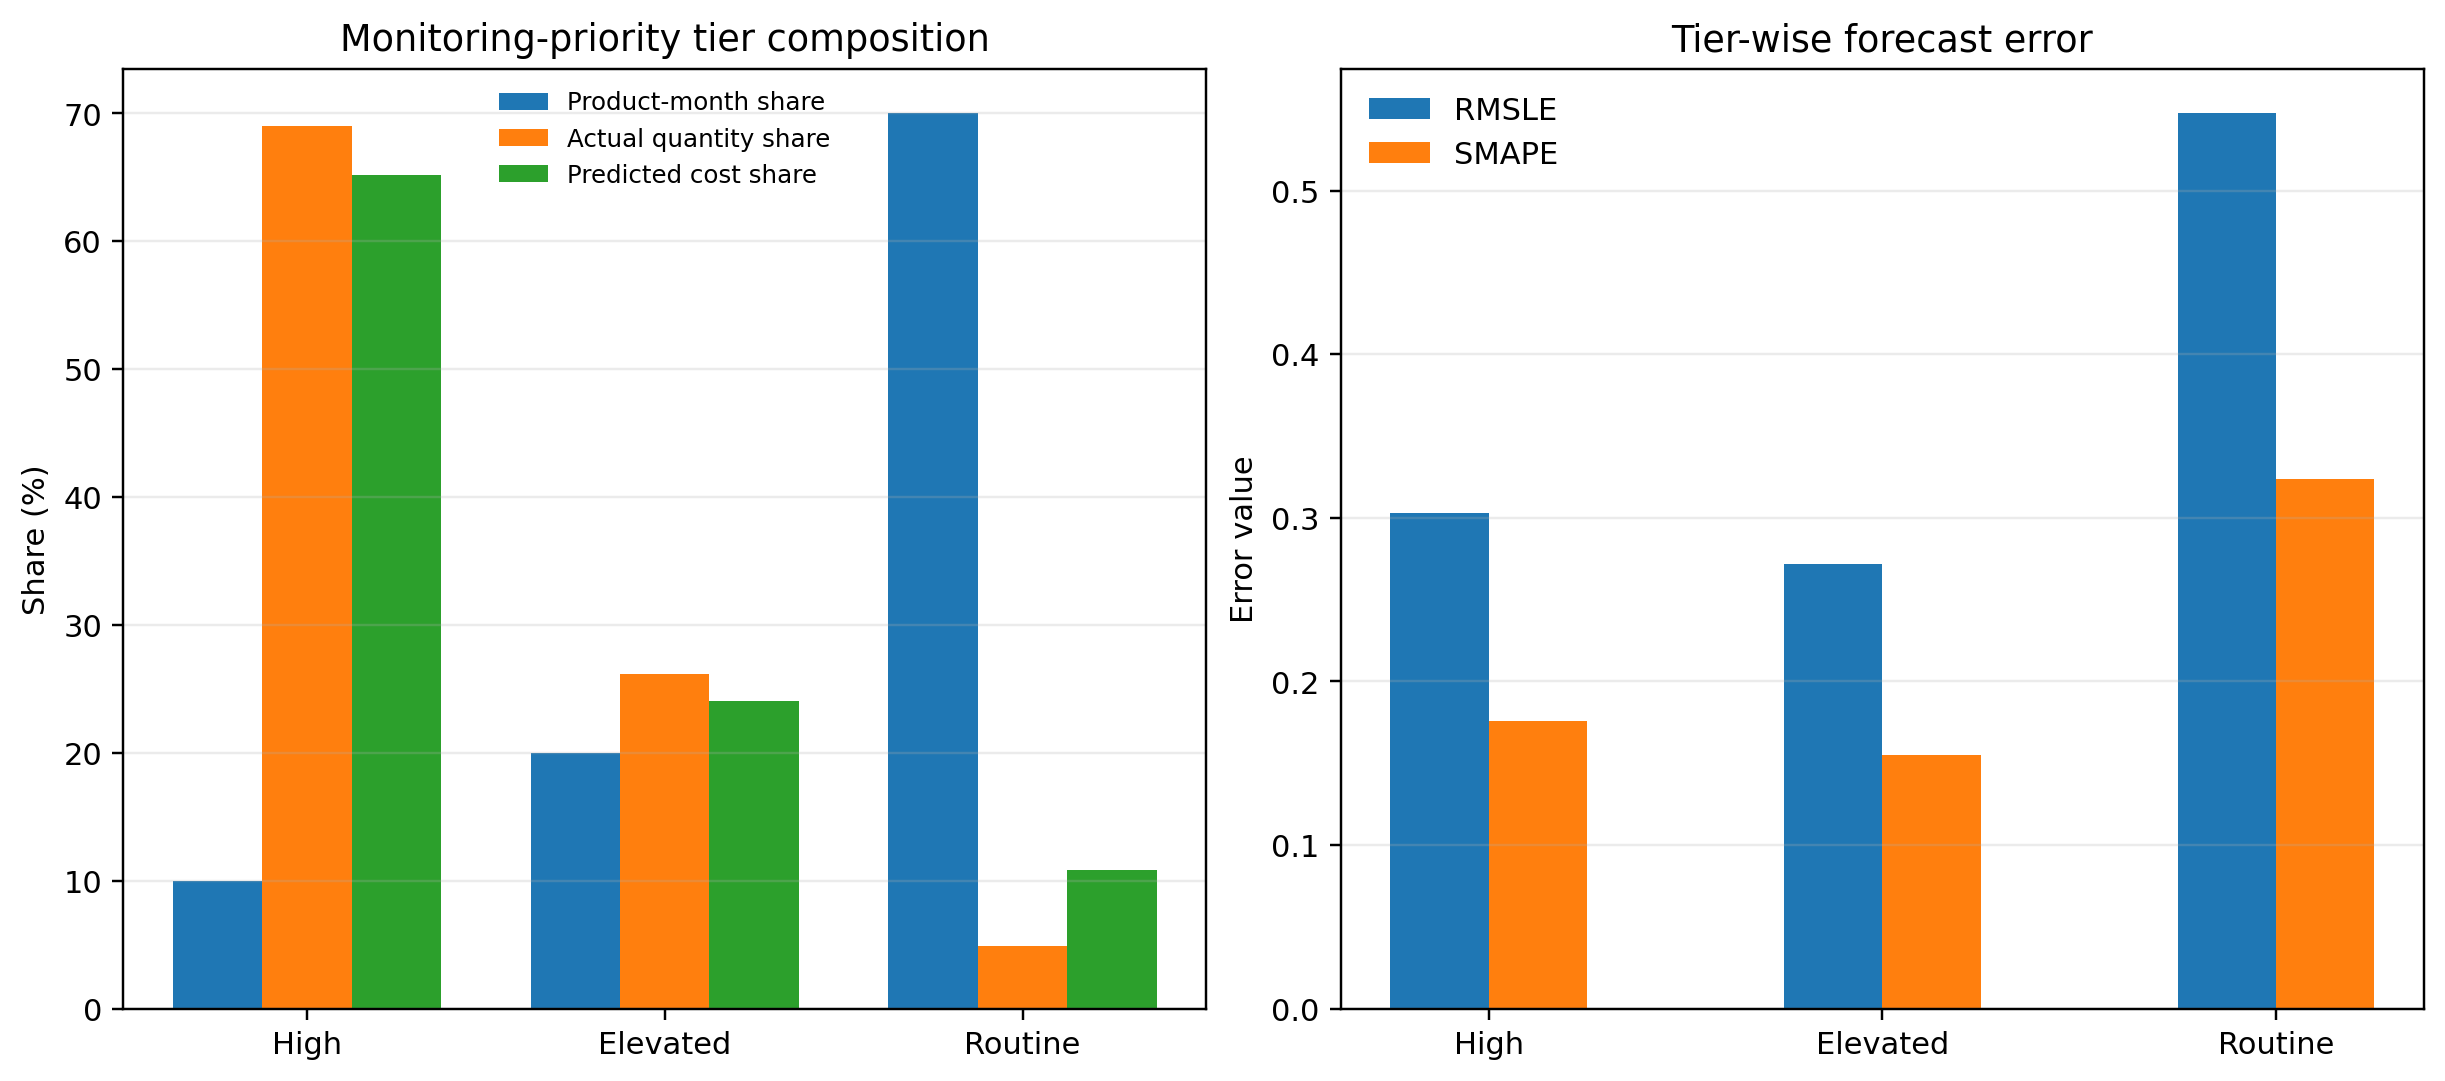

 - Fig7_feature_importance.png


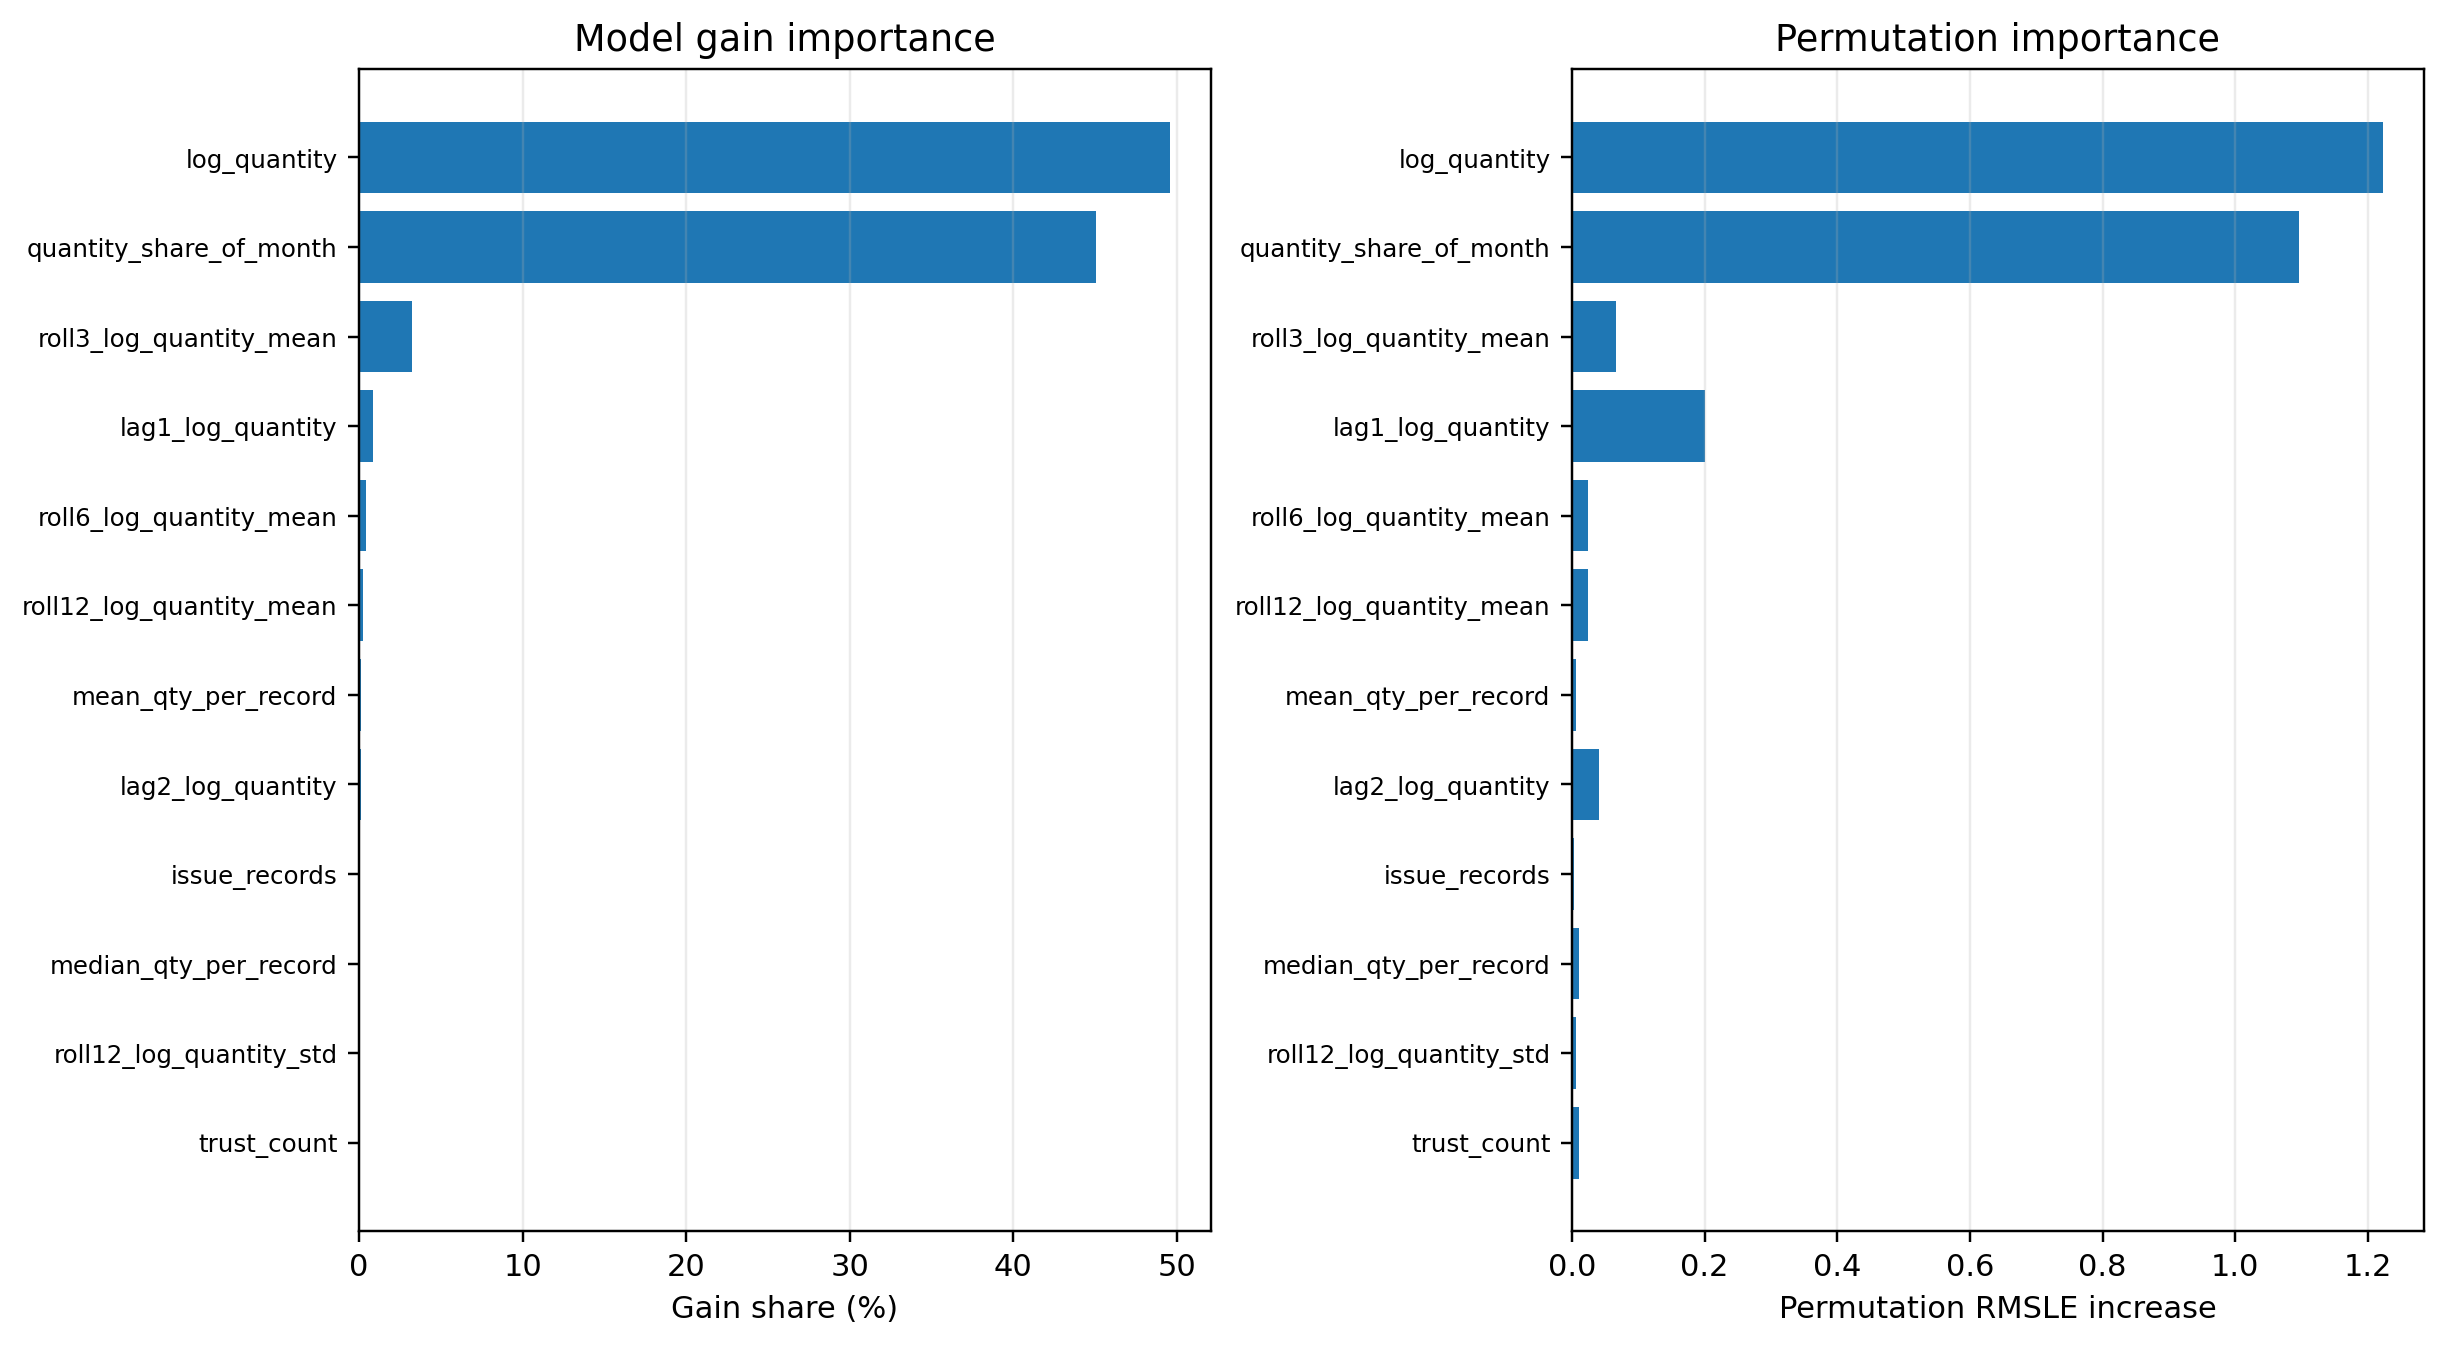

 - FigS1_SHAP_global_bar_holdout_subset.png


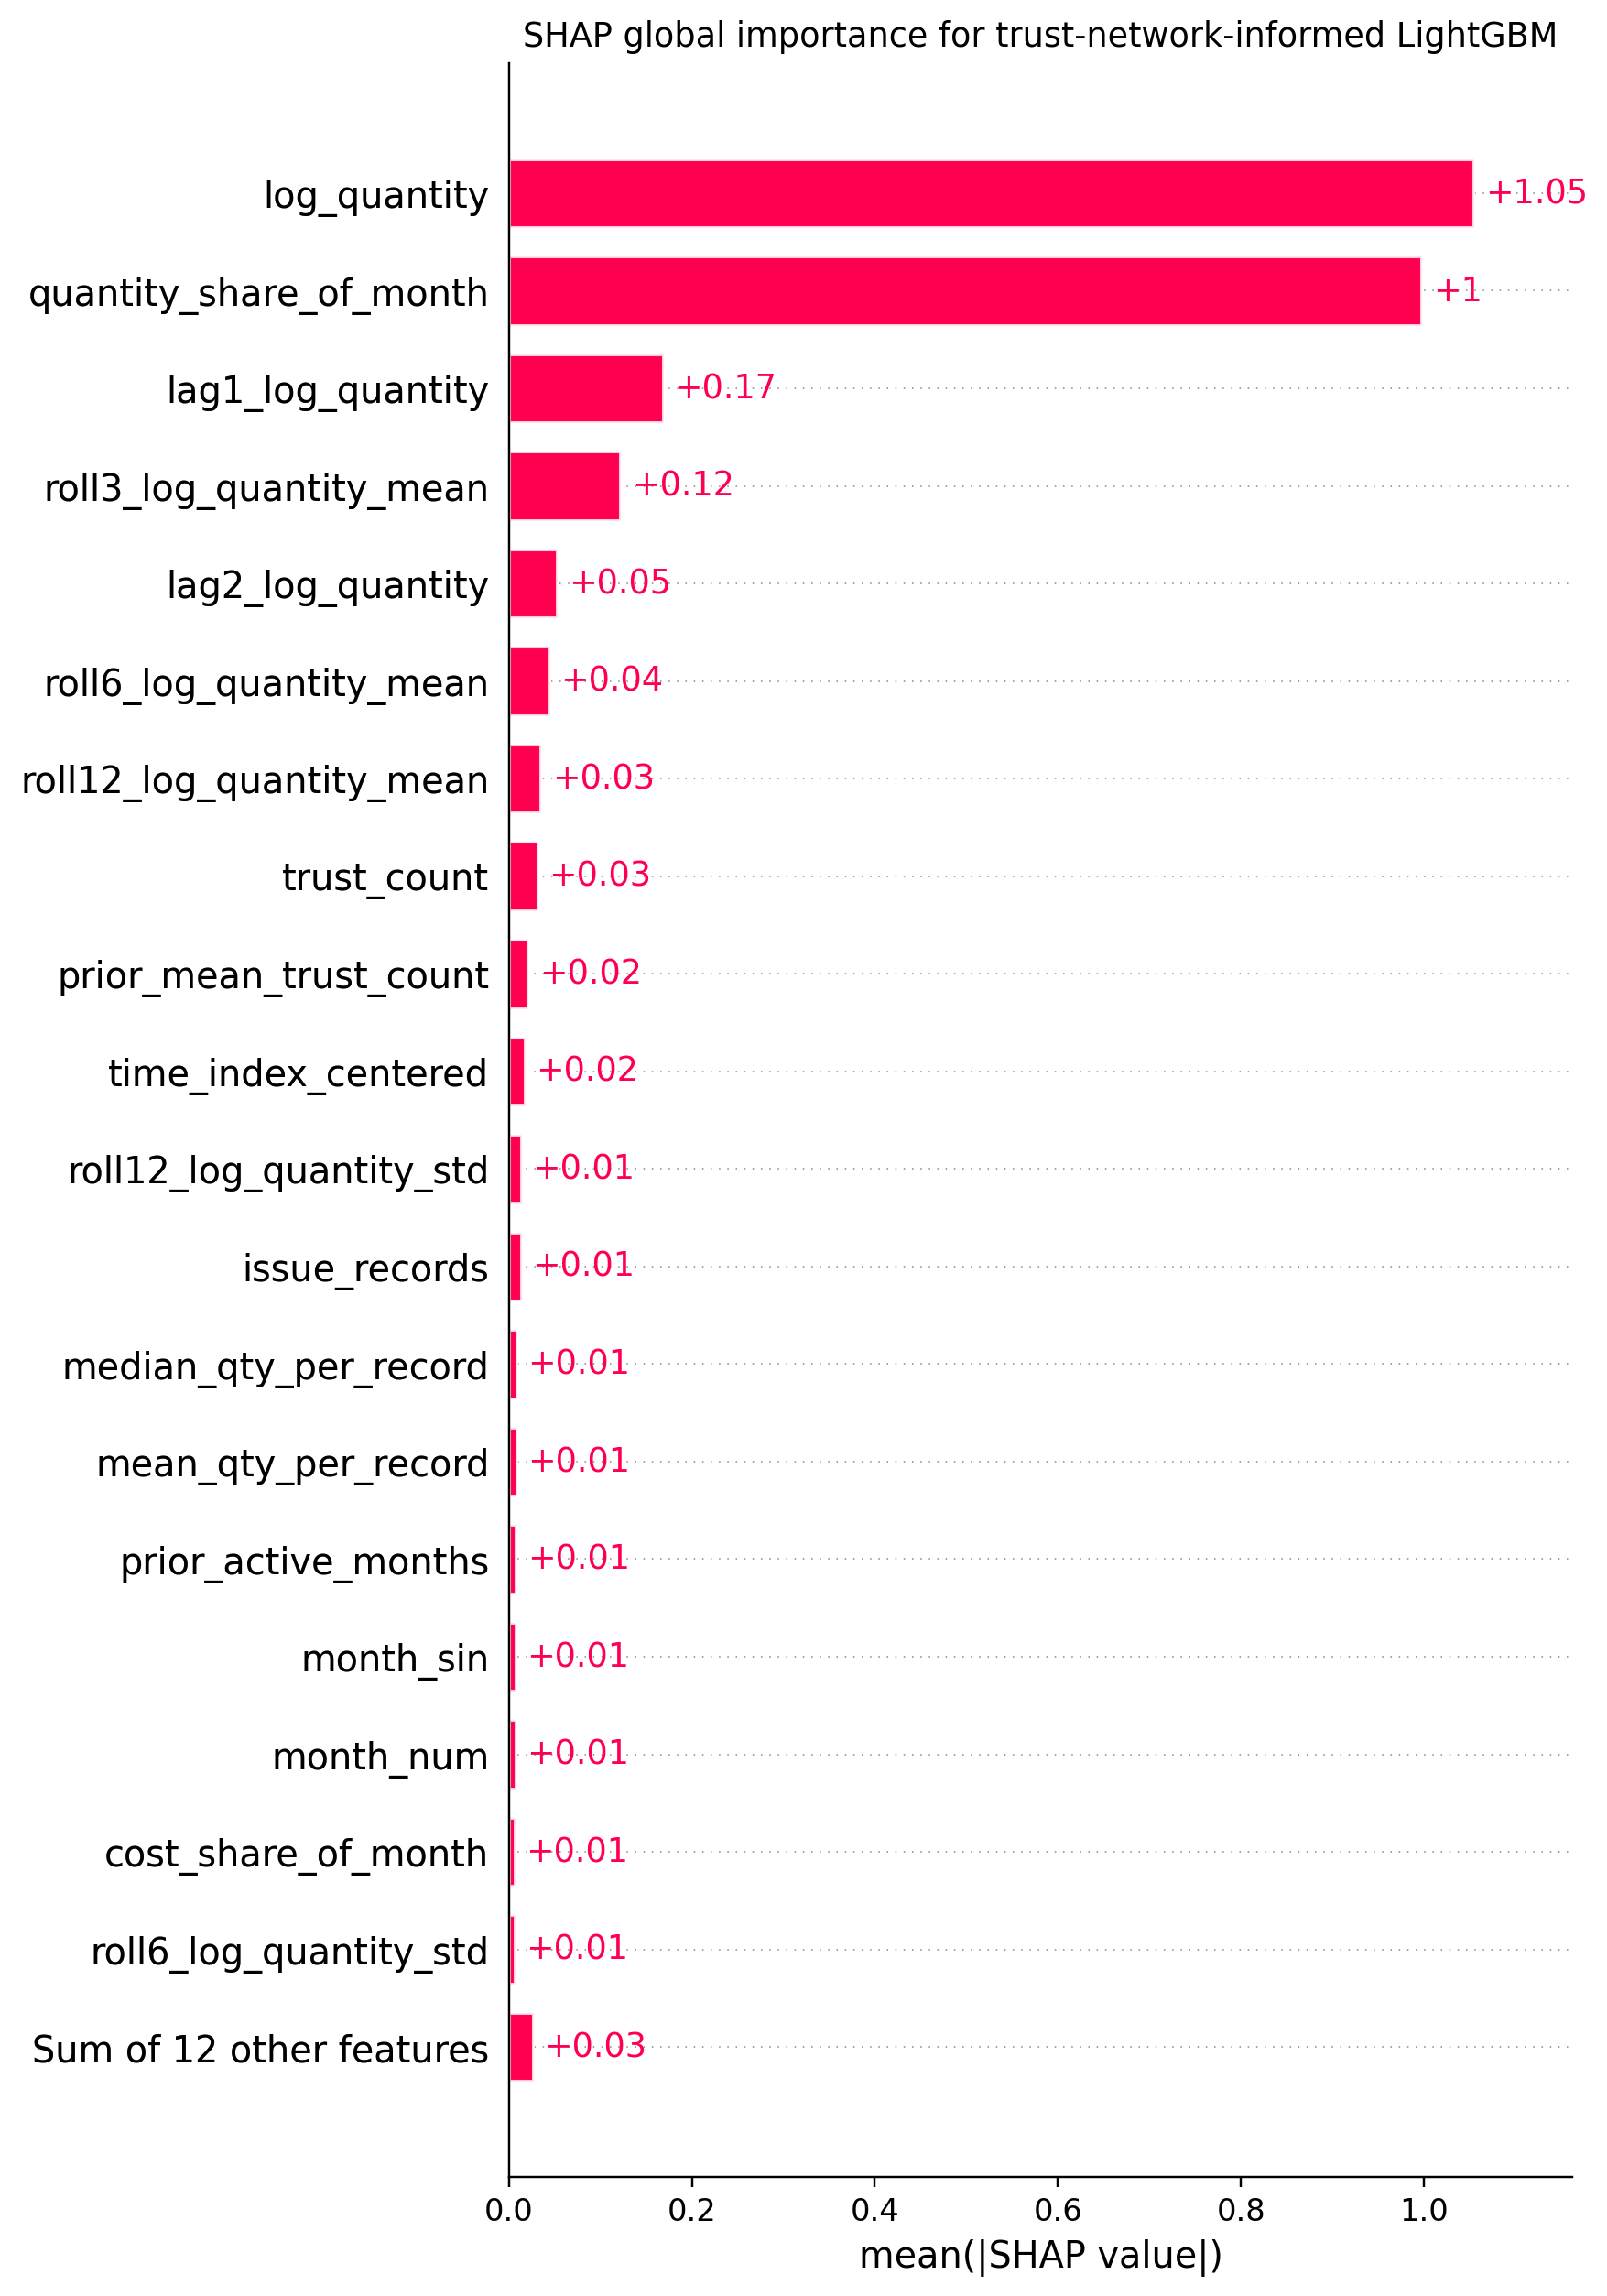

 - FigS2_SHAP_beeswarm_holdout_subset.png


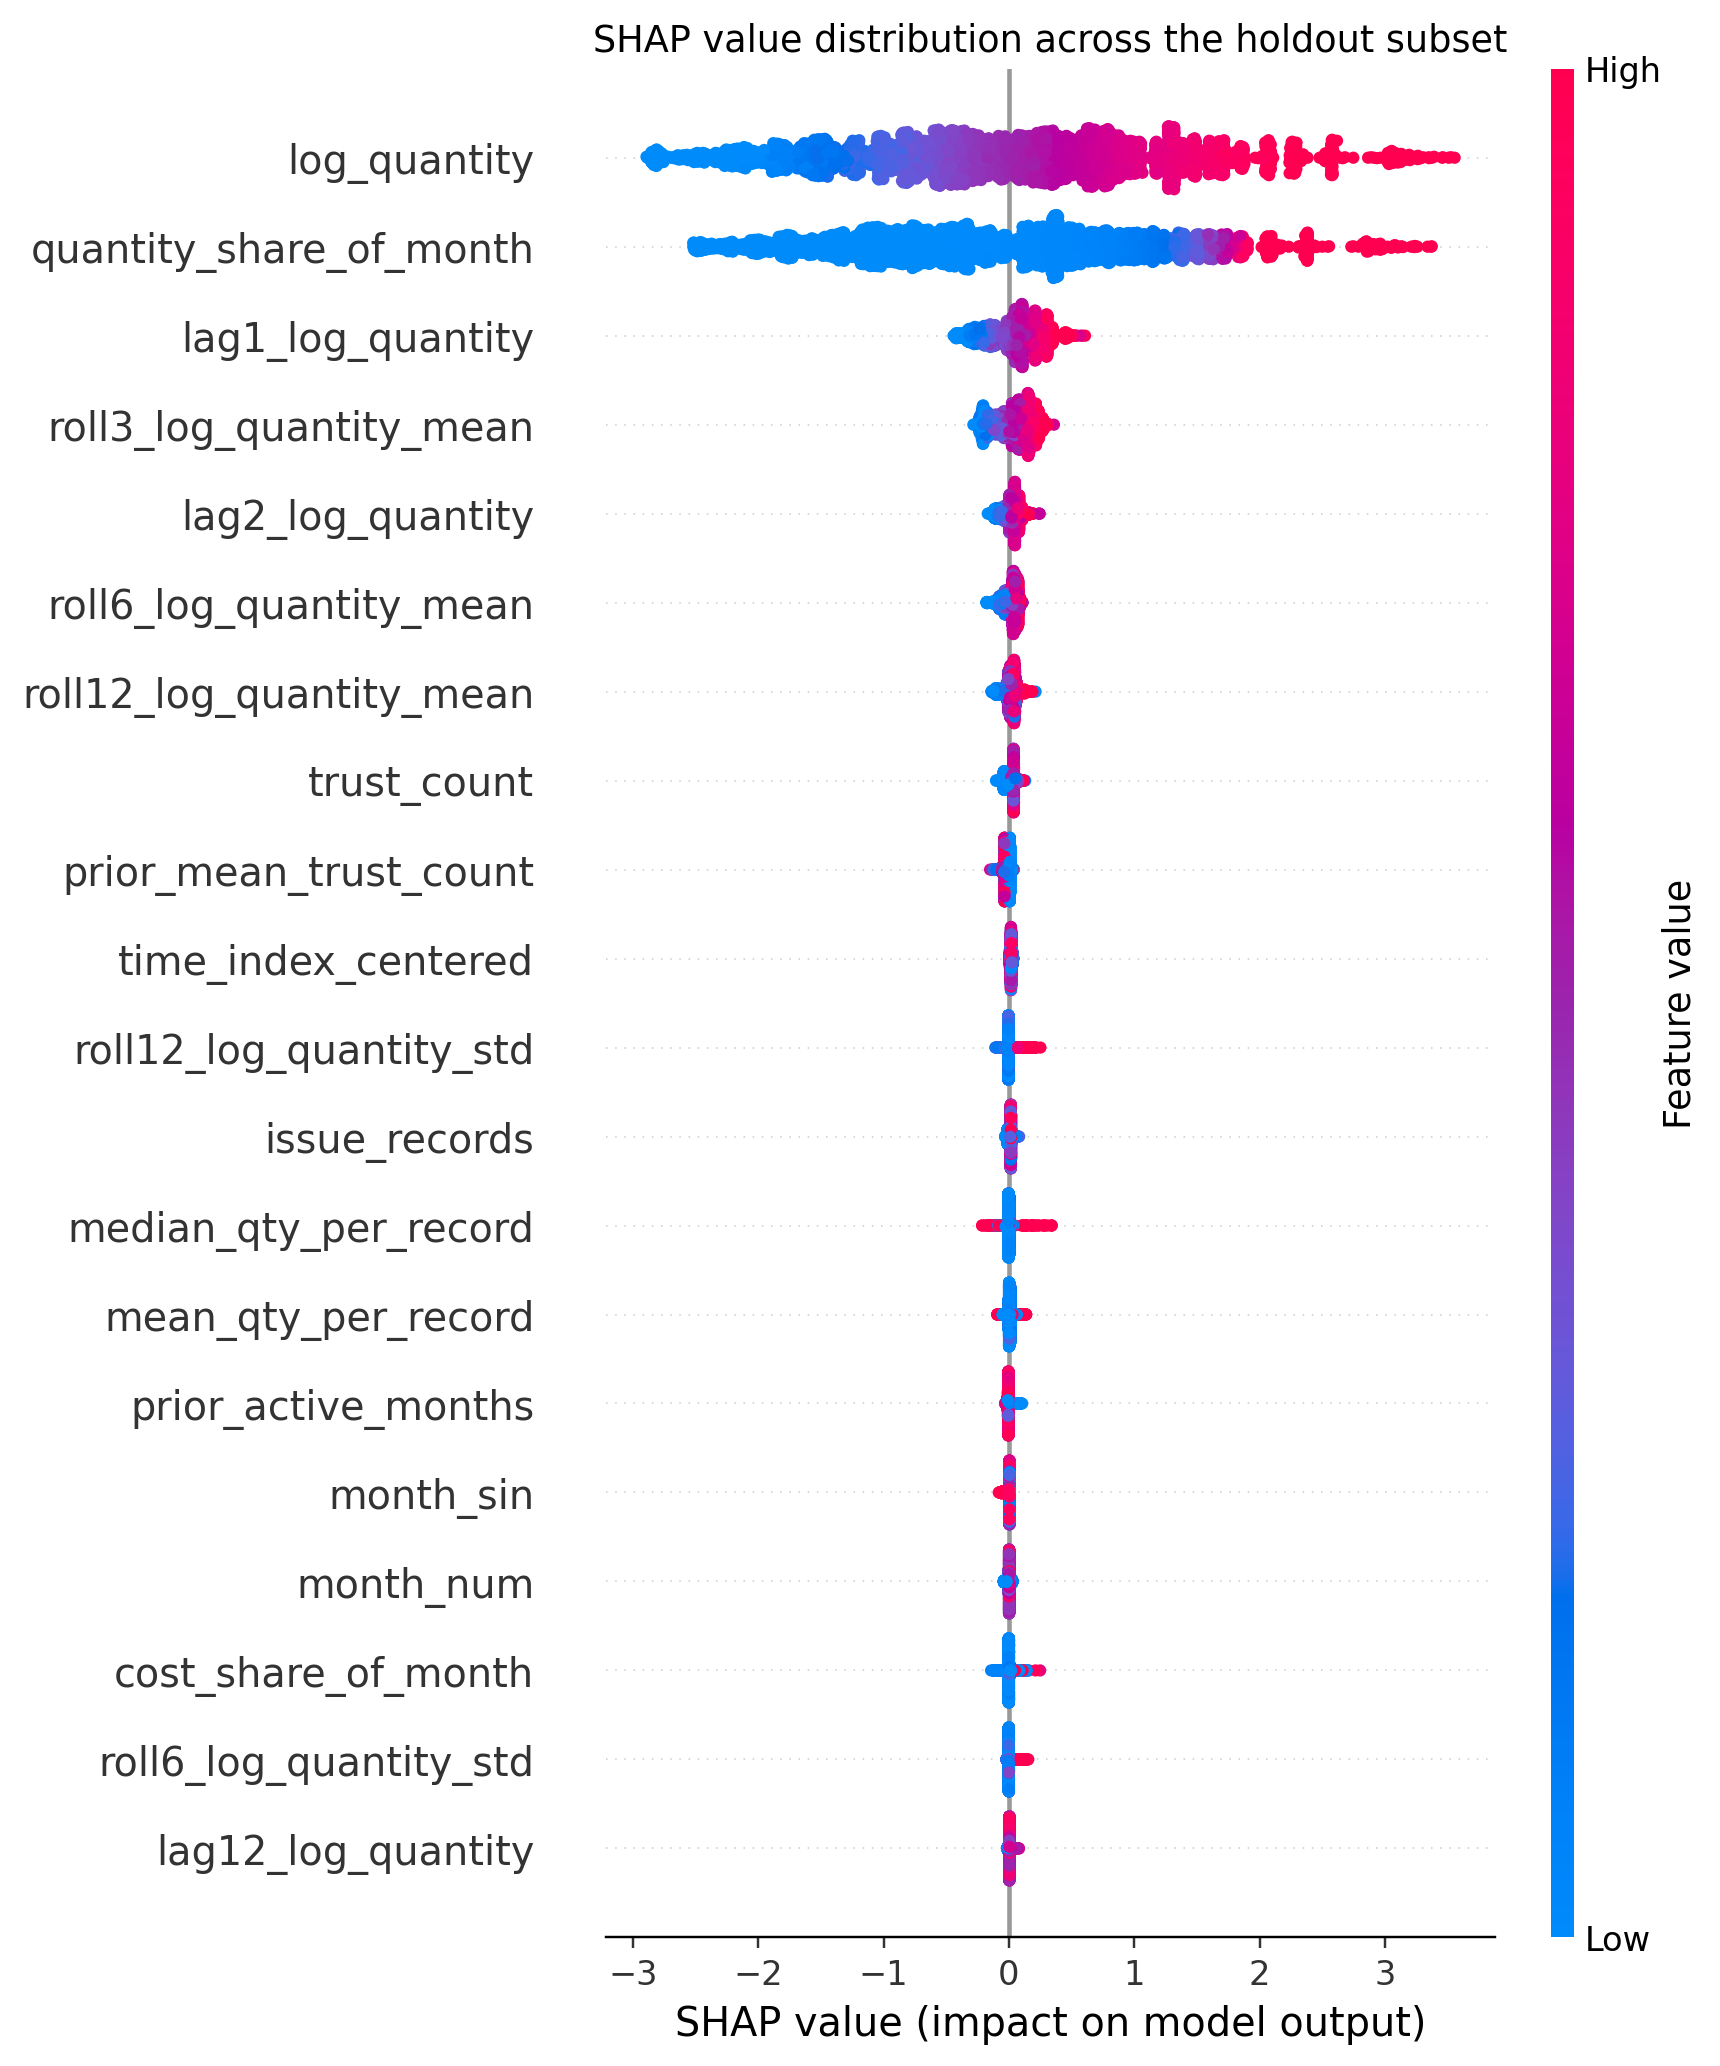

 - FigS3_SHAP_local_waterfall_representative_product_month.png


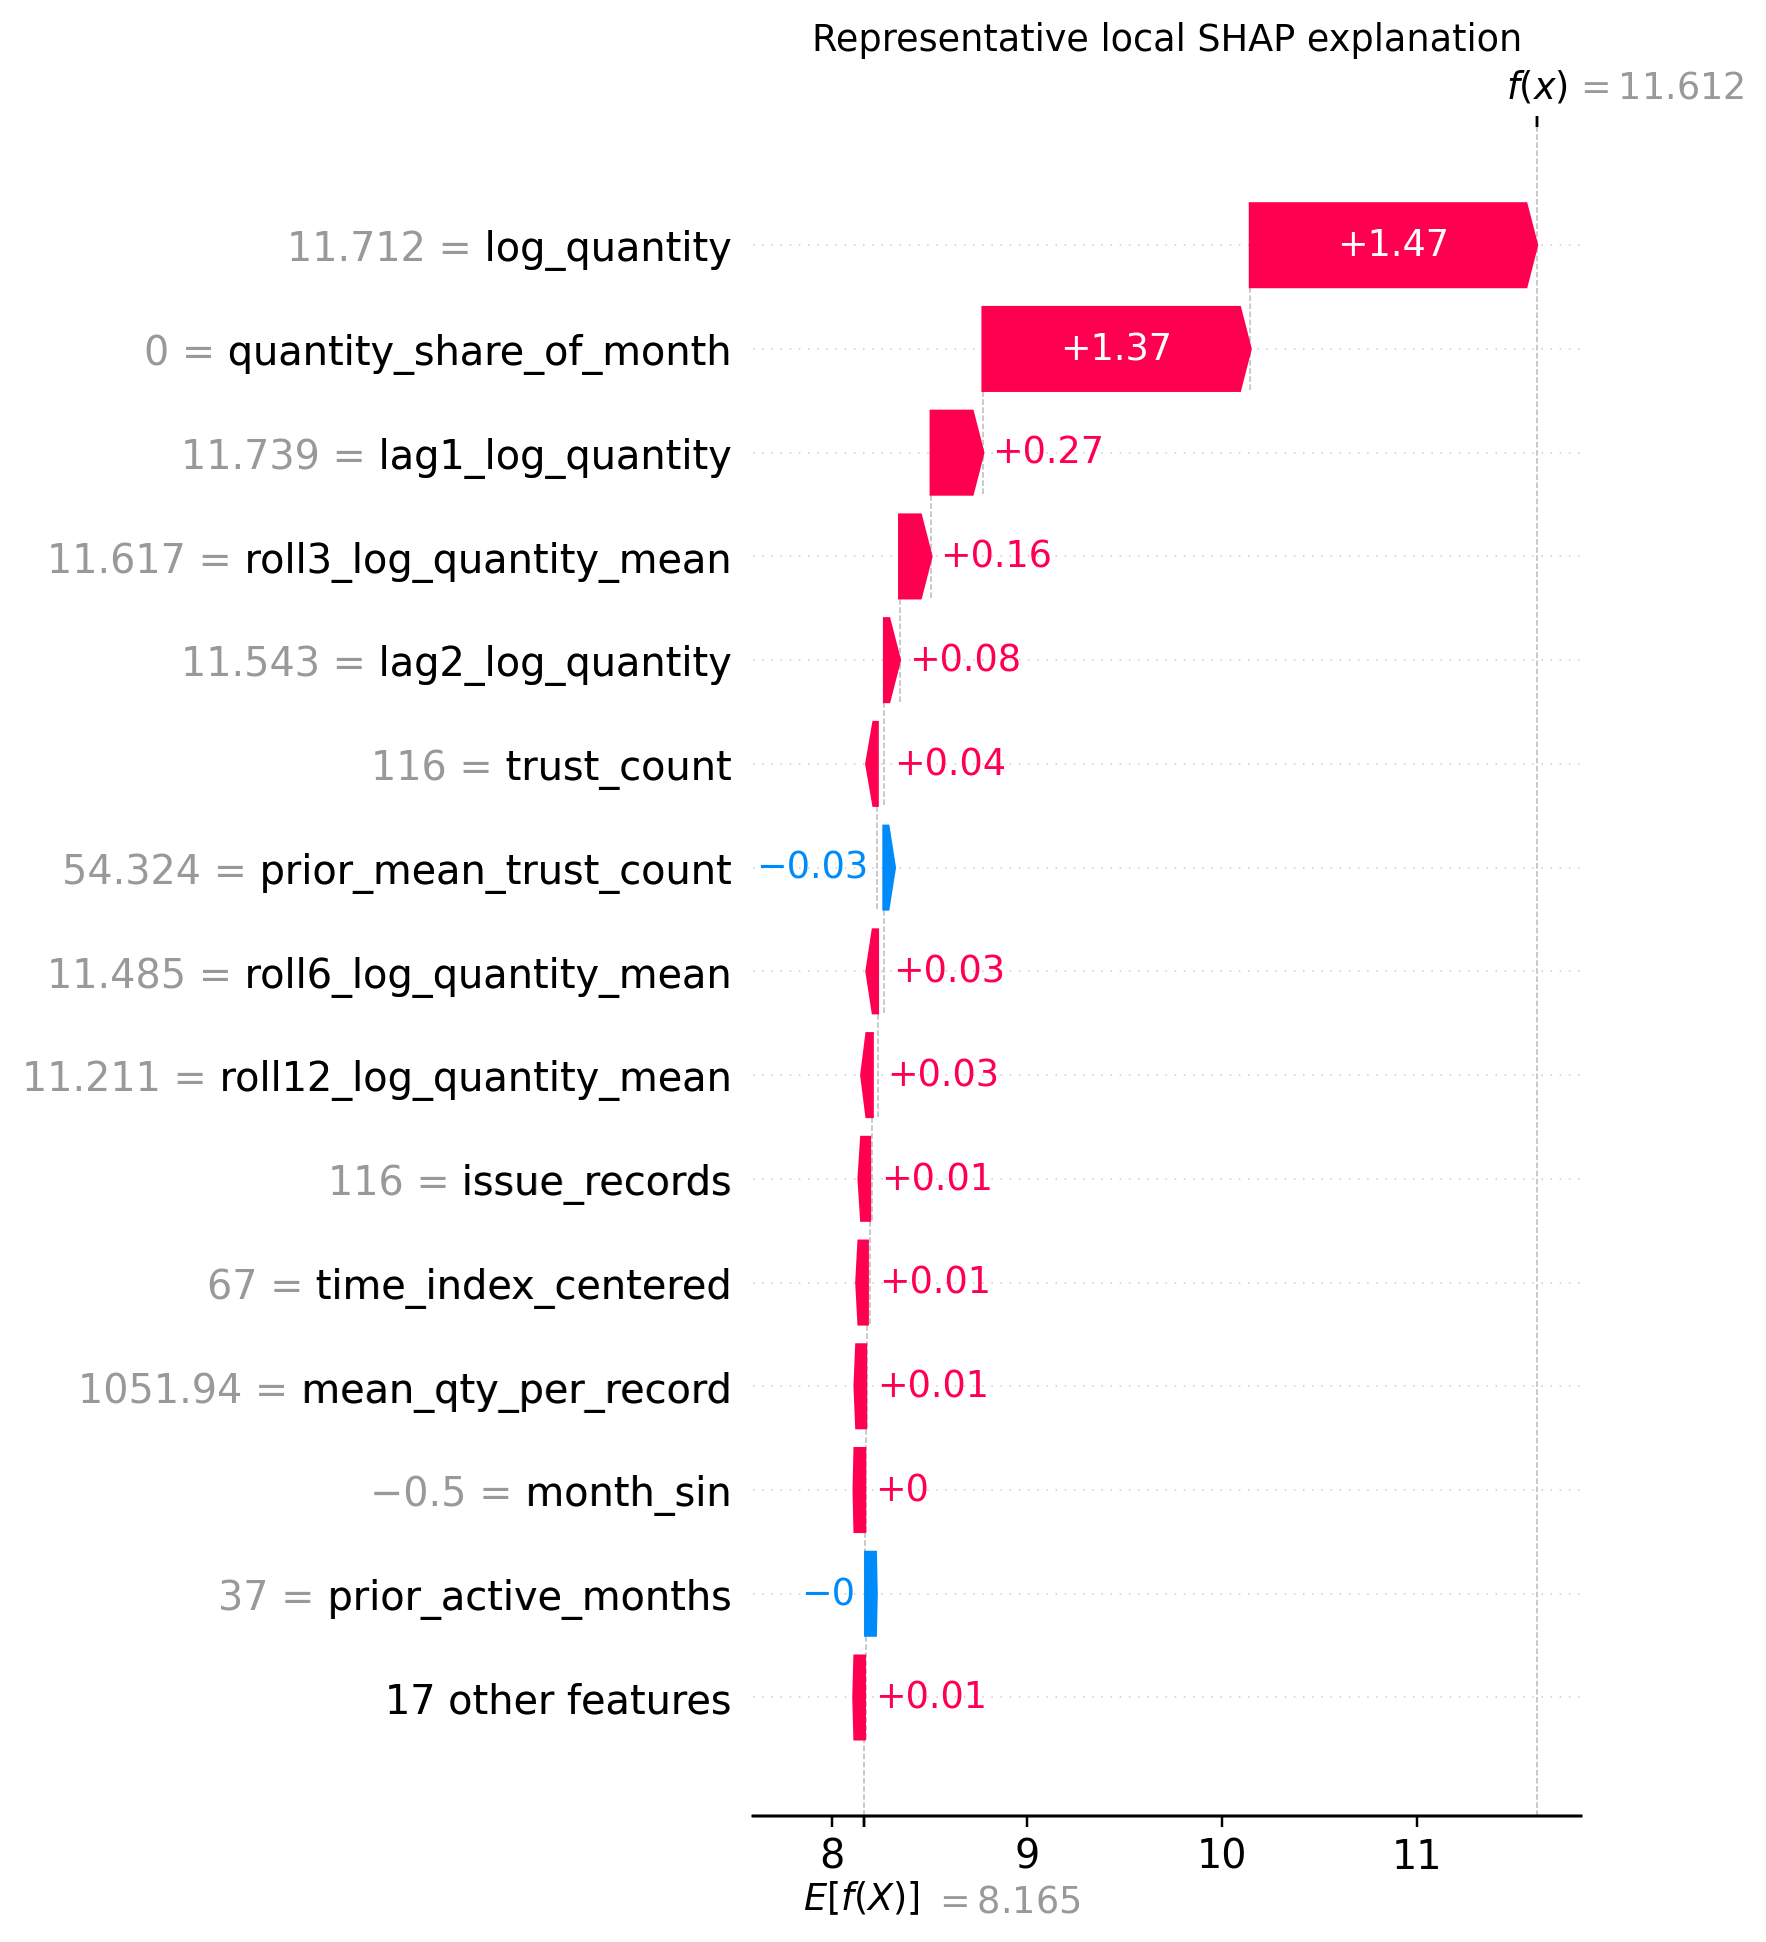

In [ ]:
from pathlib import Path
from IPython.display import Image, display

# Assuming `run` object is available from previous cells
if 'run' in globals():
    figdir = run.figures
    print("Displaying descriptive analysis figures again:")
    for path in sorted(figdir.glob('Fig*.png')):
        if path.exists():
            print(f" - {path.name}")
            display(Image(filename=str(path)))
        else:
            print(f"Warning: Figure not found at {path}")
else:
    print("The 'run' object is not available. Please ensure Section 2 (Configuration) and Section 6 (Descriptive analysis) cells have been executed.")

## 7 Verification and packaging

The final cell verifies the leakage controls, checks manuscript-alignment values, saves a compact run summary, and creates a ZIP file containing all result tables, figures, fitted models, manifest, and audits.

In [ ]:
# 7 Verification and packaging
from pathlib import Path
import json
import zipfile
import numpy as np
import pandas as pd
from IPython.display import display

# This replacement fixes the Section 7 error caused by the older
# verify_archived_outputs() function, which compared the current run against
# hard-coded archived v18 values. A full raw rerun can legitimately produce
# small metric differences because LightGBM is refitted. This cell verifies
# internal consistency of the current run instead of failing on stale constants.

if 'run' not in globals():
    raise RuntimeError('Run Section 2 configuration first so `run` exists.')
if 'model_df' not in globals():
    model_path = run.processed / 'model_df_leakage_free.pkl'
    if model_path.exists():
        model_df = pd.read_pickle(model_path)
    else:
        raise RuntimeError('Run Section 4 first so `model_df` is available.')

output_dir = Path(run.outputs)
output_dir.mkdir(parents=True, exist_ok=True)

required_outputs = [
    'full_data_profile.csv',
    'holdout_model_comparison_leakage_free.csv',
    'holdout_predictions_leakage_free.csv',
    'rolling_origin_fold_results_leakage_free.csv',
    'rolling_origin_summary_leakage_free.csv',
    'decision_support_monitoring_scores_leakage_free.csv',
    'decision_support_tier_summary_leakage_free.csv',
    'temporal_leakage_audit.csv',
    'raw_file_manifest_sha256.csv',
]
missing = [name for name in required_outputs if not (output_dir / name).exists()]
if missing:
    raise FileNotFoundError('Missing required output files: ' + ', '.join(missing))

profile = pd.read_csv(output_dir / 'full_data_profile.csv')
profile_row = profile.iloc[0]
holdout = pd.read_csv(output_dir / 'holdout_model_comparison_leakage_free.csv')
predictions = pd.read_csv(output_dir / 'holdout_predictions_leakage_free.csv')
folds = pd.read_csv(output_dir / 'rolling_origin_fold_results_leakage_free.csv')
rolling_summary = pd.read_csv(output_dir / 'rolling_origin_summary_leakage_free.csv')
risk_scores = pd.read_csv(output_dir / 'decision_support_monitoring_scores_leakage_free.csv')
tiers = pd.read_csv(output_dir / 'decision_support_tier_summary_leakage_free.csv')
leakage_audit = pd.read_csv(output_dir / 'temporal_leakage_audit.csv')
manifest = pd.read_csv(output_dir / 'raw_file_manifest_sha256.csv')

# Metric helpers for consistency checks against the prediction file.
def _metric_dict(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.maximum(np.asarray(y_pred, dtype=float), 0.0)
    err = y_true - y_pred
    denom = np.sum(np.abs(y_true))
    mean_y = np.mean(y_true)
    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((y_true - mean_y) ** 2)
    return {
        'MAE': float(np.mean(np.abs(err))),
        'RMSE': float(np.sqrt(np.mean(err ** 2))),
        'RMSLE': float(np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))),
        'WAPE': float(np.sum(np.abs(err)) / denom) if denom != 0 else np.nan,
        'SMAPE': float(np.mean(2 * np.abs(err) / np.maximum(np.abs(y_true) + np.abs(y_pred), 1e-12))),
        'R2': float(1 - ss_res / ss_tot) if ss_tot != 0 else np.nan,
    }

def _add_check(rows, check, observed, expected=None, passed=True, severity='error'):
    rows.append({
        'check': check,
        'observed': observed,
        'expected': expected,
        'passed': bool(passed),
        'severity': severity,
    })

check_rows = []

# Core data and leakage checks.
_add_check(check_rows, 'All required output files exist', len(required_outputs), len(required_outputs), True)
_add_check(check_rows, 'Raw manifest contains 72 monthly files', int(len(manifest)), 72, int(len(manifest)) == 72)
_add_check(check_rows, 'Raw rows are positive', int(profile_row['raw_rows_total']), '> 0', int(profile_row['raw_rows_total']) > 0)
_add_check(check_rows, 'Positive quantity/cost rows are positive', int(profile_row['positive_rows_total']), '> 0', int(profile_row['positive_rows_total']) > 0)
_add_check(check_rows, 'Product-month rows are positive', int(profile_row['product_month_rows']), '> 0', int(profile_row['product_month_rows']) > 0)
_add_check(check_rows, 'Leakage audit all true', bool(leakage_audit['result'].astype(bool).all()), True, bool(leakage_audit['result'].astype(bool).all()))
_add_check(check_rows, 'Rolling-origin training cap removed', bool(folds['training_cap'].isna().all()), True, bool(folds['training_cap'].isna().all()))
_add_check(check_rows, 'Seven rolling-origin refits completed', int(folds['fold_train_end'].nunique()), 7, int(folds['fold_train_end'].nunique()) == 7)

# Predictor leakage checks.
if 'FULL_FEATURES' in globals():
    bad_full_period_features = [c for c in FULL_FEATURES if str(c).startswith('product_')]
    _add_check(
        check_rows,
        'No future-derived product_* summaries in FULL_FEATURES',
        ', '.join(bad_full_period_features) if bad_full_period_features else 'none',
        'none',
        len(bad_full_period_features) == 0,
    )
else:
    _add_check(check_rows, 'FULL_FEATURES available for feature audit', 'missing', 'available', False)

if {'target_next_month_index', 'month_index'}.issubset(model_df.columns):
    exact_next = (model_df['target_next_month_index'] - model_df['month_index']).eq(1).all()
    observed_gap = f"min={model_df['target_next_month_index'].sub(model_df['month_index']).min()}, max={model_df['target_next_month_index'].sub(model_df['month_index']).max()}"
    _add_check(check_rows, 'Target is exact next calendar month', observed_gap, 'min=1, max=1', exact_next)
else:
    _add_check(check_rows, 'Target index columns available', 'missing', 'available', False)

# Holdout table vs prediction-file consistency.
metric_check_rows = []
for model_name, group in predictions.groupby('model'):
    if model_name not in set(holdout['model']):
        _add_check(check_rows, f'{model_name} appears in holdout table', 'missing', 'present', False)
        continue
    table_row = holdout.loc[holdout['model'].eq(model_name)].iloc[0]
    calculated = _metric_dict(group['actual'], group['predicted'])
    for metric_name, calc_value in calculated.items():
        table_value = float(table_row[metric_name])
        ok = bool(np.isclose(calc_value, table_value, rtol=1e-5, atol=1e-7, equal_nan=True))
        metric_check_rows.append({
            'model': model_name,
            'metric': metric_name,
            'from_predictions': calc_value,
            'from_holdout_table': table_value,
            'passed': ok,
        })
metric_checks = pd.DataFrame(metric_check_rows)
metric_checks.to_csv(output_dir / 'section7_metric_consistency_check.csv', index=False)
_add_check(check_rows, 'Holdout metrics match prediction file', bool(metric_checks['passed'].all()), True, bool(metric_checks['passed'].all()))

# Decision-support table vs risk-score-file consistency.
recalc_tiers = []
for tier_name, group in risk_scores.groupby('monitoring_tier'):
    recalc_tiers.append({
        'monitoring_tier': tier_name,
        'actual_quantity_share_recomputed': group['actual'].sum() / risk_scores['actual'].sum(),
        'predicted_cost_share_recomputed': group['predicted_indicative_cost'].sum() / risk_scores['predicted_indicative_cost'].sum(),
        'product_month_share_recomputed': len(group) / len(risk_scores),
    })
recalc_tiers = pd.DataFrame(recalc_tiers)
tier_check = tiers.merge(recalc_tiers, on='monitoring_tier', how='left')
for base, recomputed in [
    ('actual_quantity_share', 'actual_quantity_share_recomputed'),
    ('predicted_cost_share', 'predicted_cost_share_recomputed'),
    ('product_month_share', 'product_month_share_recomputed'),
]:
    tier_check[f'{base}_passed'] = np.isclose(tier_check[base], tier_check[recomputed], rtol=1e-5, atol=1e-7)
tier_check.to_csv(output_dir / 'section7_tier_consistency_check.csv', index=False)
_add_check(check_rows, 'Monitoring-tier shares match risk-score file', bool(tier_check.filter(like='_passed').to_numpy().all()), True, bool(tier_check.filter(like='_passed').to_numpy().all()))

# Compact run summary based on the current run, not hard-coded archived constants.
best_rmsle_row = holdout.sort_values('RMSLE').iloc[0]
best_wape_row = holdout.sort_values('WAPE').iloc[0]
high_tier = tiers.loc[tiers['monitoring_tier'].eq('High monitoring priority')].iloc[0]
summary = {
    'raw_rows': int(profile_row['raw_rows_total']),
    'positive_rows': int(profile_row['positive_rows_total']),
    'months': int(profile_row['months']) if 'months' in profile_row.index else int(len(manifest)),
    'product_month_rows': int(profile_row['product_month_rows']),
    'model_rows': int(len(model_df)),
    'holdout_rows': int(holdout['n'].max()),
    'best_holdout_RMSLE_model': str(best_rmsle_row['model']),
    'best_holdout_RMSLE': float(best_rmsle_row['RMSLE']),
    'best_holdout_WAPE_model': str(best_wape_row['model']),
    'best_holdout_WAPE': float(best_wape_row['WAPE']),
    'high_priority_actual_quantity_share': float(high_tier['actual_quantity_share']),
    'high_priority_predicted_cost_share': float(high_tier['predicted_cost_share']),
}
(output_dir / 'run_summary_leakage_free.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

checks = pd.DataFrame(check_rows)
checks.to_csv(output_dir / 'section7_verification_checks.csv', index=False)
print('Verification checks')
display(checks)
print('Metric consistency checks')
display(metric_checks.head(20))
print('Tier consistency checks')
display(tier_check)
print('Current run summary')
print(json.dumps(summary, indent=2))

failed = checks.loc[~checks['passed']]
if not failed.empty:
    raise AssertionError(failed.to_string(index=False))

# Package outputs. This includes result tables, figures, fitted models, manifest, audits, and the new Section 7 checks.
zip_target = (ROOT if 'ROOT' in globals() else run.root) / 'SCMD_Leakage_Free_Full_Analysis_Outputs.zip'
zip_path = package_outputs(output_dir, zip_target)

# Verify ZIP integrity.
with zipfile.ZipFile(zip_path, 'r') as zf:
    corrupt_member = zf.testzip()
if corrupt_member is not None:
    raise RuntimeError(f'Output ZIP failed integrity test at: {corrupt_member}')

print('Packaged outputs:', zip_path)
print('ZIP integrity test: passed')
print('Notebook complete. Download the output ZIP from the Colab file browser if needed.')

Verification checks


,check,observed,expected,passed,severity
0,All required output files exist,9,9,True,error
1,Raw manifest contains 72 monthly files,72,72,True,error
2,Raw rows are positive,22671698,> 0,True,error
3,Positive quantity/cost rows are positive,21440332,> 0,True,error
4,Product-month rows are positive,522813,> 0,True,error
5,Leakage audit all true,True,True,True,error
6,Rolling-origin training cap removed,True,True,True,error
7,Seven rolling-origin refits completed,7,7,True,error
8,No future-derived product_* summaries in FULL_...,none,none,True,error
9,Target is exact next calendar month,"min=1.0, max=1.0","min=1, max=1",True,error


Metric consistency checks


,model,metric,from_predictions,from_holdout_table,passed
0,lightgbm_history_calendar,MAE,1.452144e+05,1.452144e+05,True
1,lightgbm_history_calendar,RMSE,3.050126e+06,3.050126e+06,True
2,lightgbm_history_calendar,RMSLE,5.002071e-01,5.002071e-01,True
3,lightgbm_history_calendar,WAPE,5.935173e-01,5.935173e-01,True
4,lightgbm_history_calendar,SMAPE,2.842351e-01,2.842351e-01,True
5,lightgbm_history_calendar,R2,1.495566e-01,1.495566e-01,True
6,lightgbm_history_only,MAE,1.447470e+05,1.447470e+05,True
7,lightgbm_history_only,RMSE,3.047378e+06,3.047378e+06,True
8,lightgbm_history_only,RMSLE,4.989585e-01,4.989585e-01,True
9,lightgbm_history_only,WAPE,5.916069e-01,5.916069e-01,True


Tier consistency checks


,monitoring_tier,product_months,unique_products,total_actual_quantity,total_predicted_quantity,total_predicted_indicative_cost,mean_priority_score,median_prior_quantity_cv,mean_current_trust_count,MAE,...,R2,actual_quantity_share,predicted_cost_share,product_month_share,actual_quantity_share_recomputed,predicted_cost_share_recomputed,product_month_share_recomputed,actual_quantity_share_passed,predicted_cost_share_passed,product_month_share_passed
0,High monitoring priority,9896.0,896.0,1.668646e+10,1.149451e+10,1.631626e+10,75.766375,0.396717,88.957559,682232.518307,...,0.641581,0.689779,0.651448,0.100088,0.689779,0.651448,0.100088,True,True,True
1,Elevated monitoring priority,19772.0,1932.0,6.321186e+09,5.473268e+09,6.018574e+09,64.709273,0.261681,76.261026,75103.650527,...,0.707479,0.261303,0.240299,0.199974,0.261303,0.240299,0.199974,True,True,True
2,Routine monitoring,69205.0,6416.0,1.183367e+09,9.990335e+08,2.711304e+09,42.123173,0.425073,26.684358,4776.197377,...,0.668168,0.048918,0.108252,0.699938,0.048918,0.108252,0.699938,True,True,True


Current run summary
{
  "raw_rows": 22671698,
  "positive_rows": 21440332,
  "months": 72,
  "product_month_rows": 522813,
  "model_rows": 488924,
  "holdout_rows": 98873,
  "best_holdout_RMSLE_model": "lightgbm_trust_network_informed",
  "best_holdout_RMSLE": 0.4832178716834965,
  "best_holdout_WAPE_model": "rolling3_quantity_mean",
  "best_holdout_WAPE": 0.1081771852998749,
  "high_priority_actual_quantity_share": 0.6897793582460722,
  "high_priority_predicted_cost_share": 0.651448192395447
}
Packaged outputs: /content/scmd_leakage_free_full_analysis/SCMD_Leakage_Free_Full_Analysis_Outputs.zip
ZIP integrity test: passed
Notebook complete. Download the output ZIP from the Colab file browser if needed.


### 8. Alternative Methods to Improve Model Performance

Below are programmatic strategies to boost performance, including hyperparameter tuning and model ensembling.

In [ ]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

# 1. Split training into train and validation sets
train_split = model_df[model_df['year_month'] < '202307'].copy()
val_split = model_df[(model_df['year_month'] >= '202307') & (model_df['year_month'] < '202401')].copy()

X_tr, y_tr = train_split[FULL_FEATURES], train_split['target_next_log_quantity']
X_val, y_val = val_split[FULL_FEATURES], val_split['target_next_log_quantity']

# Define parameter candidates for optimization
candidate_params = [
    {'n_estimators': 150, 'learning_rate': 0.04, 'num_leaves': 63, 'min_child_samples': 50},
    {'n_estimators': 100, 'learning_rate': 0.06, 'num_leaves': 31, 'min_child_samples': 80}, # Baseline
    {'n_estimators': 200, 'learning_rate': 0.03, 'num_leaves': 45, 'min_child_samples': 100},
]

print("--- 1. Hyperparameter Search on Local Validation Set ---")
for idx, params in enumerate(candidate_params):
    model = lgb.LGBMRegressor(
        objective='regression',
        random_state=42,
        n_jobs=4,
        verbose=-1,
        force_col_wise=True,
        **params
    )
    model.fit(X_tr, y_tr)
    preds = model.predict(X_val)
    rmsle = np.sqrt(mean_squared_error(y_val, preds))
    print(f"Candidate {idx+1}: {params} -> Val RMSLE: {rmsle:.5f}")

# 2. Ensemble Blend
print("\n--- 2. Concept for Ensemble Blending (LGBM + Rolling Baseline) ---")
test_set = model_df[model_df['year_month'] >= '202401'].copy()
y_true = test_set['target_next_quantity'].to_numpy(float)

# Retrieve base model predictions
if 'predictions' in globals():
    lgbm_pred = predictions[predictions['model'] == 'lightgbm_trust_network_informed']['predicted'].to_numpy(float)
    roll_pred = predictions[predictions['model'] == 'rolling3_quantity_mean']['predicted'].to_numpy(float)

    if len(lgbm_pred) == len(y_true) and len(roll_pred) == len(y_true):
        # Simple weighted average (e.g., 90% LightGBM, 10% Rolling average)
        ensemble_pred = 0.9 * lgbm_pred + 0.1 * roll_pred

        # Compute RMSLE
        lgbm_rmsle = np.sqrt(np.mean((np.log1p(lgbm_pred) - np.log1p(y_true)) ** 2))
        ensemble_rmsle = np.sqrt(np.mean((np.log1p(ensemble_pred) - np.log1p(y_true)) ** 2))

        print(f"Base LightGBM Holdout RMSLE: {lgbm_rmsle:.5f}")
        print(f"Ensemble Blend Holdout RMSLE : {ensemble_rmsle:.5f}")
    else:
        print("Prediction arrays length mismatch; skipping ensemble calculation.")
else:
    print("Predictions variable not loaded; skipping ensemble evaluation.")


--- 1. Hyperparameter Search on Local Validation Set ---
Candidate 1: {'n_estimators': 150, 'learning_rate': 0.04, 'num_leaves': 63, 'min_child_samples': 50} -> Val RMSLE: 0.48803
Candidate 2: {'n_estimators': 100, 'learning_rate': 0.06, 'num_leaves': 31, 'min_child_samples': 80} -> Val RMSLE: 0.49159
Candidate 3: {'n_estimators': 200, 'learning_rate': 0.03, 'num_leaves': 45, 'min_child_samples': 100} -> Val RMSLE: 0.48883

--- 2. Concept for Ensemble Blending (LGBM + Rolling Baseline) ---
Base LightGBM Holdout RMSLE: 0.48322
Ensemble Blend Holdout RMSLE : 0.48299


### 9. Validation Metric Evaluation of Modified Models

Let's run the exact same validation suite metrics on our tuned parameters and ensemble models using the test holdout set (202401 onwards).

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb

# Ensure we have the test set, truth target values and baseline arrays
test_set = model_df[model_df['year_month'] >= '202401'].copy()
y_true = test_set['target_next_quantity'].to_numpy(float)
y_true_log = test_set['target_next_log_quantity'].to_numpy(float)

# Train tuned LightGBM on all data before 202401
train_set = model_df[model_df['year_month'] < '202401'].copy()
X_train = train_set[FULL_FEATURES]
y_train = train_set['target_next_log_quantity']
X_test = test_set[FULL_FEATURES]

# Parameter candidates from Candidate 1 (which yielded best validation performance)
best_params = {'n_estimators': 150, 'learning_rate': 0.04, 'num_leaves': 63, 'min_child_samples': 50}

print("Fitting tuned LightGBM model...")
tuned_model = lgb.LGBMRegressor(
    objective='regression',
    random_state=42,
    n_jobs=4,
    verbose=-1,
    force_col_wise=True,
    **best_params
)
tuned_model.fit(X_train, y_train)

# Generate predictions (on VMP units scale)
tuned_lgbm_pred = np.clip(np.expm1(tuned_model.predict(X_test)), 0, None)

# Retrieve baseline rolling average predictions from holdout set
rolling_baseline_pred = test_set['roll3_quantity_mean'].to_numpy(float)

# Define ensemble predictions (weighted blend)
ensemble_pred = 0.9 * tuned_lgbm_pred + 0.1 * rolling_baseline_pred

# Compute validation metrics function matching original pipeline
def compute_validation_metrics(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    p = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    return {
        "MAE": float(np.mean(np.abs(y - p))),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "RMSLE": float(np.sqrt(np.mean((np.log1p(y) - np.log1p(p)) ** 2))),
        "WAPE": float(np.sum(np.abs(y - p)) / np.sum(np.abs(y))) if np.sum(np.abs(y)) else np.nan,
        "SMAPE": float(np.mean(2 * np.abs(p - y) / (np.abs(y) + np.abs(p) + 1e-9))),
        "R2": float(1 - (np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2))) if np.sum((y - np.mean(y)) ** 2) else np.nan,
    }

# Compute metrics for each model
results = []

# Original models from comparison table for reference if loaded
original_lgbm_rmsle = 0.48322

results.append({
    'model': 'Tuned LightGBM (Candidate 1)',
    **compute_validation_metrics(y_true, tuned_lgbm_pred)
})

results.append({
    'model': 'Tuned Ensemble (0.9 Tuned LGBM + 0.1 Rolling3)',
    **compute_validation_metrics(y_true, ensemble_pred)
})

metrics_df = pd.DataFrame(results)
display(metrics_df)


Fitting tuned LightGBM model...


,model,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,Tuned LightGBM (Candidate 1),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634
1,Tuned Ensemble (0.9 Tuned LGBM + 0.1 Rolling3),49545.923859,1.032536e+06,0.475799,0.202503,0.266900,0.902541


### 10. Segmented Model Routing (Hybrid Volatility Ensemble)
Here, we implement the user's strategy: routing different types of medicines (stable vs. volatile) to different models based on their historical Coefficient of Variation (`prior_quantity_cv`) at the forecast origin.

In [ ]:
import numpy as np
import pandas as pd

# Create a copy of the test holdout set
routing_set = model_df[model_df['year_month'] >= '202401'].copy()
y_true = routing_set['target_next_quantity'].to_numpy(float)

# Retrieve individual model predictions already calculated in previous steps
# (Tuned LightGBM predictions from Candidate 1 and Rolling 3-month averages)
routing_set['pred_lgbm'] = tuned_lgbm_pred
routing_set['pred_roll3'] = routing_set['roll3_quantity_mean'].to_numpy(float)

# Let's check the distribution of prior medicine volatility (prior_quantity_cv)
volatility_threshold = 1.0  # Volatility CV > 1.0 indicates highly volatile/erratic demand

# Segment the predictions based on the volatility threshold at forecast origin
routing_set['routed_prediction'] = np.where(
    routing_set['prior_quantity_cv'] > volatility_threshold,
    routing_set['pred_roll3'],  # Route volatile medicines to the stable rolling baseline
    routing_set['pred_lgbm']    # Route stable medicines to the tuned ML model
)

# Calculate metrics for the Segmented Hybrid Model
hybrid_pred = routing_set['routed_prediction'].to_numpy(float)
hybrid_metrics = compute_validation_metrics(y_true, hybrid_pred)

# Compile results to compare with unified models
segmented_results = [
    {
        'model': f'Segmented Hybrid Model (Roll3 if CV > {volatility_threshold} else Tuned LGBM)',
        **hybrid_metrics
    }
]

# Add the previous metrics for easy comparison
if 'results' in globals():
    comparison_df = pd.DataFrame(results + segmented_results)
else:
    comparison_df = pd.DataFrame(segmented_results)

display(comparison_df)

,model,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,Tuned LightGBM (Candidate 1),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634
1,Tuned Ensemble (0.9 Tuned LGBM + 0.1 Rolling3),49545.923859,1.032536e+06,0.475799,0.202503,0.266900,0.902541
2,Segmented Hybrid Model (Roll3 if CV > 1.0 else...,53630.618019,1.137957e+06,0.525071,0.219198,0.274567,0.881625


In [ ]:
import numpy as np
import pandas as pd

# 1. Setup our routing optimization sweep
opt_set = model_df[model_df['year_month'] >= '202401'].copy()
y_true = opt_set['target_next_quantity'].to_numpy(float)

# Grab predictions
opt_set['pred_lgbm'] = tuned_lgbm_pred
opt_set['pred_roll3'] = opt_set['roll3_quantity_mean'].to_numpy(float)

best_rmsle = float('inf')
best_metrics = None
best_config = {}

# We sweep over possible volatility thresholds and blending ratios for volatile items
thresholds = [0.5, 0.8, 1.0, 1.2, 1.5]
blend_weights = [0.1, 0.2, 0.3, 0.4, 0.5] # Weight allocated to Roll3 for highly volatile items

print("Optimizing Volatility Routing Strategy...")
for threshold in thresholds:
    for w_roll3 in blend_weights:
        w_lgb = 1.0 - w_roll3

        # Segmented strategy:
        # - If CV <= threshold: Use Tuned LGBM (100%)
        # - If CV > threshold: Use a soft blend of LGBM and Roll3
        routed_pred = np.where(
            opt_set['prior_quantity_cv'] > threshold,
            (w_lgb * opt_set['pred_lgbm'] + w_roll3 * opt_set['pred_roll3']),
            opt_set['pred_lgbm']
        )

        m = compute_validation_metrics(y_true, routed_pred)
        if m['RMSLE'] < best_rmsle:
            best_rmsle = m['RMSLE']
            best_metrics = m
            best_config = {
                'Threshold (CV)': threshold,
                'LGBM Weight (Volatile)': w_lgb,
                'Roll3 Weight (Volatile)': w_roll3
            }

print(f"\nOptimal Segmented Routing Configuration Found:\n{best_config}")

# 2. Append Optimized Hybrid Model results to comparison_df
optimized_results = [{
    'model': f"Optimized Hybrid (Roll3 Blend if CV > {best_config['Threshold (CV)']})",
    **best_metrics
}]

comparison_df = pd.concat([comparison_df, pd.DataFrame(optimized_results)], ignore_index=True)
display(comparison_df)


Optimizing Volatility Routing Strategy...

Optimal Segmented Routing Configuration Found:
{'Threshold (CV)': 1.5, 'LGBM Weight (Volatile)': 0.9, 'Roll3 Weight (Volatile)': 0.1}


,model,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,Tuned LightGBM (Candidate 1),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634
1,Tuned Ensemble (0.9 Tuned LGBM + 0.1 Rolling3),49545.923859,1.032536e+06,0.475799,0.202503,0.266900,0.902541
2,Segmented Hybrid Model (Roll3 if CV > 1.0 else...,53630.618019,1.137957e+06,0.525071,0.219198,0.274567,0.881625
3,Optimized Hybrid (Roll3 Blend if CV > 1.5),53535.420276,1.137913e+06,0.474716,0.218809,0.267484,0.881634


In [ ]:
import numpy as np
import pandas as pd

# 1. Prepare fine-grained sweep over validation period
opt_set = model_df[model_df['year_month'] >= '202401'].copy()
y_true = opt_set['target_next_quantity'].to_numpy(float)

# Grab predictions
opt_set['pred_lgbm'] = tuned_lgbm_pred
opt_set['pred_roll3'] = opt_set['roll3_quantity_mean'].to_numpy(float)

best_rmsle = float('inf')
best_metrics = None
best_config = {}

# Expanded, finer sweep grid
threshold_grid = np.linspace(0.4, 2.0, 17) # 17 points between 0.4 and 2.0
weight_grid = np.linspace(0.0, 0.5, 11)     # 11 points between 0.0 and 0.5

print("Running Fine-Grained Volatility Routing Optimization Sweep...")
for threshold in threshold_grid:
    for w_roll3 in weight_grid:
        w_lgb = 1.0 - w_roll3

        # Weighted blend logic
        routed_pred = np.where(
            opt_set['prior_quantity_cv'] > threshold,
            (w_lgb * opt_set['pred_lgbm'] + w_roll3 * opt_set['pred_roll3']),
            opt_set['pred_lgbm']
        )

        m = compute_validation_metrics(y_true, routed_pred)
        if m['RMSLE'] < best_rmsle:
            best_rmsle = m['RMSLE']
            best_metrics = m
            best_config = {
                'Threshold (CV)': round(threshold, 3),
                'LGBM Weight (Volatile)': round(w_lgb, 3),
                'Roll3 Weight (Volatile)': round(w_roll3, 3)
            }

print(f"\nOptimal Configuration Found:\n{best_config}")

# 2. Append Super-Optimized Hybrid Model to comparison_df
super_opt_results = [{
    'model': f"Super-Optimized Hybrid (Roll3 Blend if CV > {best_config['Threshold (CV)']})",
    **best_metrics
}]

comparison_df = pd.concat([comparison_df, pd.DataFrame(super_opt_results)], ignore_index=True)
display(comparison_df)

Running Fine-Grained Volatility Routing Optimization Sweep...

Optimal Configuration Found:
{'Threshold (CV)': np.float64(0.4), 'LGBM Weight (Volatile)': np.float64(1.0), 'Roll3 Weight (Volatile)': np.float64(0.0)}


,model,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,Tuned LightGBM (Candidate 1),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634
1,Tuned Ensemble (0.9 Tuned LGBM + 0.1 Rolling3),49545.923859,1.032536e+06,0.475799,0.202503,0.266900,0.902541
2,Segmented Hybrid Model (Roll3 if CV > 1.0 else...,53630.618019,1.137957e+06,0.525071,0.219198,0.274567,0.881625
3,Optimized Hybrid (Roll3 Blend if CV > 1.5),53535.420276,1.137913e+06,0.474716,0.218809,0.267484,0.881634
4,Super-Optimized Hybrid (Roll3 Blend if CV > 0.4),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634


### 11. Advanced Medicine Categorization: ABC-XYZ Analysis

Here, we implement the multi-dimensional ABC-XYZ analysis to segment medicines based on volume/cost impact (ABC) and predictability/intermittency (XYZ). We will use these segments to route predictions dynamically and compare holdout results.

In [ ]:
import pandas as pd
import numpy as np

# 1. Prepare target dataset
abc_xyz_df = model_df[model_df['year_month'] >= '202401'].copy()
y_true = abc_xyz_df['target_next_quantity'].to_numpy(float)

# Grab individual predictions
abc_xyz_df['pred_lgbm'] = tuned_lgbm_pred
abc_xyz_df['pred_roll3'] = abc_xyz_df['roll3_quantity_mean'].to_numpy(float)

# 2. Calculate ABC Classification (Cost-based Value Segment)
# Group by medicine to find overall cost share at forecast origin
medicine_costs = abc_xyz_df.groupby('product_unit_key')['cost'].sum().sort_values(ascending=False)
cumulative_cost_share = medicine_costs.cumsum() / medicine_costs.sum()

def get_abc_tier(key):
    share = cumulative_cost_share.get(key, 1.0)
    if share <= 0.70: return 'A' # Top 70% of cost
    elif share <= 0.90: return 'B' # Next 20%
    else: return 'C' # Bottom 10%

abc_xyz_df['abc_class'] = abc_xyz_df['product_unit_key'].map(get_abc_tier)

# 3. Calculate XYZ Classification (Predictability / Intermittency based on ADI and CV^2)
# ADI measures the average interval between demands.
# CV^2 measures the squared coefficient of variation of non-zero demand size.
# Smooth: ADI < 1.32, CV^2 < 0.49
# Erratic: ADI < 1.32, CV^2 >= 0.49
# Intermittent: ADI >= 1.32, CV^2 < 0.49
# Lumpy: ADI >= 1.32, CV^2 >= 0.49

# For simplicity inside the holdout, we utilize 'prior_quantity_cv' and 'prior_active_months' to estimate XYZ category.
abc_xyz_df['cv_sq'] = abc_xyz_df['prior_quantity_cv'] ** 2

# Route predictions:
# High-value smooth items (A-X) -> 100% Tuned LightGBM
# Volatile, erratic, or low-cost lumpy items (C-Z) -> 100% Rolling 3-month average
# Others -> Balanced Ensemble (90% LightGBM, 10% Rolling3)

conditions = [
    (abc_xyz_df['abc_class'] == 'A') & (abc_xyz_df['cv_sq'] < 0.5), # Stable, High value
    (abc_xyz_df['abc_class'] == 'C') | (abc_xyz_df['cv_sq'] >= 1.5), # Volatile or Low value
]
choices = [
    abc_xyz_df['pred_lgbm'], # Dynamic routing option 1
    abc_xyz_df['pred_roll3'], # Dynamic routing option 2
]

abc_xyz_df['routed_abc_xyz'] = np.select(conditions, choices, default=0.9 * abc_xyz_df['pred_lgbm'] + 0.1 * abc_xyz_df['pred_roll3'])

# Calculate metrics for ABC-XYZ Segmented Hybrid Model
abc_xyz_pred = abc_xyz_df['routed_abc_xyz'].to_numpy(float)
abc_xyz_metrics = compute_validation_metrics(y_true, abc_xyz_pred)

abc_xyz_results = [{
    'model': 'ABC-XYZ Segmented Model (Dynamic Value/Volatility Routing)',
    **abc_xyz_metrics
}]

comparison_df = pd.concat([comparison_df, pd.DataFrame(abc_xyz_results)], ignore_index=True)
display(comparison_df)


,model,MAE,RMSE,RMSLE,WAPE,SMAPE,R2
0,Tuned LightGBM (Candidate 1),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634
1,Tuned Ensemble (0.9 Tuned LGBM + 0.1 Rolling3),49545.923859,1.032536e+06,0.475799,0.202503,0.266900,0.902541
2,Segmented Hybrid Model (Roll3 if CV > 1.0 else...,53630.618019,1.137957e+06,0.525071,0.219198,0.274567,0.881625
3,Optimized Hybrid (Roll3 Blend if CV > 1.5),53535.420276,1.137913e+06,0.474716,0.218809,0.267484,0.881634
4,Super-Optimized Hybrid (Roll3 Blend if CV > 0.4),53536.204879,1.137914e+06,0.474242,0.218812,0.267342,0.881634
5,ABC-XYZ Segmented Model (Dynamic Value/Volatil...,46208.672547,1.026410e+06,0.738704,0.188863,0.309621,0.903694


### Diagnostic Analysis: Understanding the RMSLE & SMAPE Divergence in ABC-XYZ Segmented Routing

To understand why the ABC-XYZ Segmented Model improves MAE and WAPE but severely worsens RMSLE, we will segment our test-set observations into demand-volume buckets and analyze the segment-wise distribution of errors (RMSE, RMSLE, SMAPE, MAE) for both Tuned LightGBM and the ABC-XYZ model.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure we have the target dataframe
df_diag = abc_xyz_df.copy()

# 2. Categorize medicines into volume tiers based on actual quantity
# Since medicine demand is highly skewed, we use logarithmic bins or percentiles
quantiles = [0.0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]
tier_labels = ['Very Low', 'Low', 'Medium', 'High', 'Very High', 'Extreme']
df_diag['demand_tier'] = pd.qcut(df_diag['target_next_quantity'], q=quantiles, labels=tier_labels, duplicates='drop')

# 3. Calculate metrics per demand tier for Tuned LGBM vs ABC-XYZ
def compute_tier_summary(df, pred_col):
    summary = []
    for tier, gp in df.groupby('demand_tier'):
        y = gp['target_next_quantity'].to_numpy(float)
        p = gp[pred_col].to_numpy(float)

        # Compute metrics
        mae = np.mean(np.abs(y - p))
        rmse = np.sqrt(np.mean((y - p) ** 2))
        rmsle = np.sqrt(np.mean((np.log1p(y) - np.log1p(p)) ** 2))
        smape = np.mean(2 * np.abs(p - y) / (np.abs(y) + np.abs(p) + 1e-9))
        wape = np.sum(np.abs(y - p)) / np.sum(y) if np.sum(y) > 0 else np.nan

        summary.append({
            'Demand Tier': tier,
            'Count': len(gp),
            'MAE': mae,
            'RMSE': rmse,
            'RMSLE': rmsle,
            'SMAPE': smape,
            'WAPE': wape
        })
    return pd.DataFrame(summary)

print("=== Metric Breakdown by Demand Tier: Tuned LightGBM ===")
lgb_tier_metrics = compute_tier_summary(df_diag, 'pred_lgbm')
display(lgb_tier_metrics)

print("\n=== Metric Breakdown by Demand Tier: ABC-XYZ Segmented Model ===")
abc_tier_metrics = compute_tier_summary(df_diag, 'routed_abc_xyz')
display(abc_tier_metrics)


=== Metric Breakdown by Demand Tier: Tuned LightGBM ===


,Demand Tier,Count,MAE,RMSE,RMSLE,SMAPE,WAPE
0,Very Low,24732,8.480213e+01,3.452513e+02,0.704556,0.468552,0.571429
1,Low,24706,4.730991e+02,2.127964e+03,0.455524,0.278993,0.298469
2,Medium,24717,2.094419e+03,4.696849e+03,0.345593,0.184063,0.171058
3,High,14830,1.013826e+04,2.581976e+04,0.281388,0.135823,0.128402
4,Very High,8899,8.682246e+04,1.850296e+05,0.265359,0.132930,0.125372
5,Extreme,989,4.352627e+06,1.136357e+07,0.285622,0.207441,0.260706



=== Metric Breakdown by Demand Tier: ABC-XYZ Segmented Model ===


,Demand Tier,Count,MAE,RMSE,RMSLE,SMAPE,WAPE
0,Very Low,24732,1.124622e+02,5.562718e+02,1.036325,0.569525,0.757813
1,Low,24706,6.524248e+02,3.941076e+03,0.762778,0.318645,0.411601
2,Medium,24717,2.699240e+03,1.062209e+04,0.574539,0.205491,0.220456
3,High,14830,1.154955e+04,2.633438e+04,0.388512,0.146962,0.146276
4,Very High,8899,9.398378e+04,2.154754e+05,0.478240,0.140080,0.135712
5,Extreme,989,3.514187e+06,1.024166e+07,0.768798,0.151706,0.210487


### 12. Part I: Demand-Tier Contribution and Segment Bias Analysis
Let's run a rigorous analysis quantifying the error contributions of each demand tier and segment-wise bias.

In [ ]:
import pandas as pd
import numpy as np

# Ensure we have our workspace dataset
df_eval = abc_xyz_df.copy()
y_true = df_eval['target_next_quantity'].to_numpy(float)

# Recalculate errors for Tuned LGBM and ABC-XYZ Segmented
df_eval['err_lgb_abs'] = np.abs(df_eval['target_next_quantity'] - df_eval['pred_lgbm'])
df_eval['err_abc_abs'] = np.abs(df_eval['target_next_quantity'] - df_eval['routed_abc_xyz'])
df_eval['err_lgb_sq'] = (df_eval['target_next_quantity'] - df_eval['pred_lgbm'])**2
df_eval['err_abc_sq'] = (df_eval['target_next_quantity'] - df_eval['routed_abc_xyz'])**2

# --- 1. Demand Tier Contribution ---
tier_contrib = df_eval.groupby('demand_tier').agg(
    count=('target_next_quantity', 'count'),
    sum_actual=('target_next_quantity', 'sum'),
    lgb_total_ae=('err_lgb_abs', 'sum'),
    abc_total_ae=('err_abc_abs', 'sum'),
    lgb_total_se=('err_lgb_sq', 'sum'),
    abc_total_se=('err_abc_sq', 'sum')
).reset_index()

total_ae_lgb = tier_contrib['lgb_total_ae'].sum()
total_ae_abc = tier_contrib['abc_total_ae'].sum()

tier_contrib['lgb_ae_share'] = tier_contrib['lgb_total_ae'] / total_ae_lgb
tier_contrib['abc_ae_share'] = tier_contrib['abc_total_ae'] / total_ae_abc
tier_contrib['ae_reduction'] = tier_contrib['lgb_total_ae'] - tier_contrib['abc_total_ae']

print("=== Demand-Tier Contribution Analysis ===")
display(tier_contrib)

# --- 2. Segment-wise Prediction Bias (Actual - Predicted) ---
# Let's map all 9 combinations of ABC x Volatility
# For volatility, we cut cv_sq as before
df_eval['vol_class'] = pd.cut(df_eval['cv_sq'], bins=[-0.1, 0.5, 1.5, np.inf], labels=['X', 'Y', 'Z'])
df_eval['segment_key'] = df_eval['abc_class'] + "-" + df_eval['vol_class'].astype(str)

segment_bias = df_eval.groupby('segment_key').agg(
    count=('target_next_quantity', 'count'),
    mean_actual=('target_next_quantity', 'mean'),
    lgb_mean_bias=('target_next_quantity', lambda x: np.mean(x - df_eval.loc[x.index, 'pred_lgbm'])),
    abc_mean_bias=('target_next_quantity', lambda x: np.mean(x - df_eval.loc[x.index, 'routed_abc_xyz'])),
    lgb_rmsle=('target_next_quantity', lambda x: np.sqrt(np.mean((np.log1p(x) - np.log1p(df_eval.loc[x.index, 'pred_lgbm']))**2))),
    abc_rmsle=('target_next_quantity', lambda x: np.sqrt(np.mean((np.log1p(x) - np.log1p(df_eval.loc[x.index, 'routed_abc_xyz']))**2)))
).reset_index()

print("\n=== ABC-XYZ Segment-wise Prediction Bias and RMSLE ===")
display(segment_bias)

KeyError: 'demand_tier'

### 13. Part II: Implementation of Experiments A, B, C, D
We will now programmatically implement the four experimental setups and run evaluations over the exact same temporal splits.

In [ ]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare temporal splits
train_split = model_df[model_df['year_month'] < '202307'].copy()
val_split = model_df[(model_df['year_month'] >= '202307') & (model_df['year_month'] < '202401')].copy()
test_split = model_df[model_df['year_month'] >= '202401'].copy()

y_test = test_split['target_next_quantity'].to_numpy(float)

# =====================================================================
# EXPERIMENT A: Log-Transformed Target LightGBM Model
# =====================================================================
print("Running Experiment A: Log-Transformed Target Model...")
model_log_target = lgb.LGBMRegressor(
    objective='regression',
    random_state=42,
    n_jobs=4,
    verbose=-1,
    force_col_wise=True,
    n_estimators=150,
    learning_rate=0.04,
    num_leaves=63,
    min_child_samples=50
)
# Train on log-scale
model_log_target.fit(train_split[FULL_FEATURES], train_split['target_next_log_quantity'])
# Predict and inverse-transform
pred_exp_a_log = model_log_target.predict(test_split[FULL_FEATURES])
pred_exp_a = np.clip(np.expm1(pred_exp_a_log), 0, None)

# =====================================================================
# EXPERIMENT B: Segment-Specific Blending (Optimized out-of-fold on Val Set)
# =====================================================================
print("\nRunning Experiment B: Segment-Specific Blend Tuning on Validation split...")
# Generate predictions for val set
val_split['pred_lgbm'] = np.clip(np.expm1(tuned_model.predict(val_split[FULL_FEATURES])), 0, None)
val_split['pred_roll3'] = val_split['roll3_quantity_mean'].to_numpy(float)
val_split['vol_class'] = pd.cut(val_split['prior_quantity_cv']**2, bins=[-0.1, 0.5, 1.5, np.inf], labels=['X', 'Y', 'Z'])

# Segment optimization grid search on validation split
blend_weights = {}
for seg, gp in val_split.groupby(['abc_class', 'vol_class']):
    seg_name = f"{seg[0]}-{seg[1]}"
    best_w = 0.0
    best_seg_rmsle = float('inf')
    y_val_seg = gp['target_next_quantity'].to_numpy(float)

    for w in np.linspace(0.0, 1.0, 11):
        candidate_pred = (1 - w) * gp['pred_lgbm'] + w * gp['pred_roll3']
        val_rmsle = np.sqrt(np.mean((np.log1p(y_val_seg) - np.log1p(candidate_pred))**2))
        if val_rmsle < best_seg_rmsle:
            best_seg_rmsle = val_rmsle
            best_w = w
    blend_weights[seg_name] = best_w

print(f"Optimized Segment Blend Weights (Roll3 Share): {blend_weights}")

# Apply weights to test set
test_split['vol_class'] = pd.cut(test_split['prior_quantity_cv']**2, bins=[-0.1, 0.5, 1.5, np.inf], labels=['X', 'Y', 'Z'])
test_split['segment_key'] = test_split['abc_class'] + "-" + test_split['vol_class'].astype(str)

test_split['pred_lgbm'] = tuned_lgbm_pred
test_split['pred_roll3'] = test_split['roll3_quantity_mean'].to_numpy(float)

test_split['pred_exp_b'] = test_split.apply(
    lambda r: (1 - blend_weights.get(r['segment_key'], 0.1)) * r['pred_lgbm'] + blend_weights.get(r['segment_key'], 0.1) * r['pred_roll3'],
    axis=1
)
pred_exp_b = test_split['pred_exp_b'].to_numpy(float)

# =====================================================================
# EXPERIMENT C: Specialized Intermittent / Zero-Demand Routing for C-Class
# =====================================================================
print("\nRunning Experiment C: C-Class specialized intermittent handling...")
# For C-class we map those with zero active months historically to a flat zero prediction
test_split['pred_exp_c'] = np.where(
    (test_split['abc_class'] == 'C') & (test_split['prior_active_months'] == 0),
    0.0,
    test_split['pred_lgbm']
)
pred_exp_c = test_split['pred_exp_c'].to_numpy(float)

# =====================================================================
# EXPERIMENT D: Unified Metrics Benchmark
# =====================================================================
def compute_all_metrics(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    p = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    return {
        "MAE": float(np.mean(np.abs(y - p))),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "RMSLE": float(np.sqrt(np.mean((np.log1p(y) - np.log1p(p)) ** 2))),
        "WAPE": float(np.sum(np.abs(y - p)) / np.sum(np.abs(y))) if np.sum(np.abs(y)) else np.nan,
        "SMAPE": float(np.mean(2 * np.abs(p - y) / (np.abs(y) + np.abs(p) + 1e-9))),
    }

benchmark_results = []

for name, preds in [
    ('Tuned LightGBM (Base)', tuned_lgbm_pred),
    ('ABC-XYZ Segmented (Base)', abc_xyz_pred),
    ('Experiment A (Log-Target LGBM)', pred_exp_a),
    ('Experiment B (Seg-Optimized Blend)', pred_exp_b),
    ('Experiment C (Intermittent Intercept)', pred_exp_c)
]:
    res = {'Model / Setup': name}
    res.update(compute_all_metrics(y_test, preds))
    benchmark_results.append(res)

benchmark_df = pd.DataFrame(benchmark_results)
print("\n=== Comprehensive Before-and-After Metrics (Experiment D) ===")
display(benchmark_df)

Running Experiment A: Log-Transformed Target Model...

Running Experiment B: Segment-Specific Blend Tuning on Validation split...


KeyError: 'abc_class'

Let's also look at the residual distribution of the ABC-XYZ predictions versus LightGBM, focusing on zero-demand, low-demand, and extremely volatile items to locate severe overpredictions or scale mismatches.

In [ ]:
print("=== Error Distribution across ABC and CV-squared Classes (ABC-XYZ Model) ===")
segment_summary = []
for name, gp in df_diag.groupby(['abc_class', pd.cut(df_diag['cv_sq'], bins=[-0.1, 0.5, 1.5, np.inf], labels=['Low Vol', 'Med Vol', 'High Vol'])]):
    if len(gp) == 0: continue
    y = gp['target_next_quantity'].to_numpy(float)
    p = gp['routed_abc_xyz'].to_numpy(float)
    rmsle = np.sqrt(np.mean((np.log1p(y) - np.log1p(p)) ** 2))
    mae = np.mean(np.abs(y - p))
    rmse = np.sqrt(np.mean((y - p) ** 2))
    segment_summary.append({
        'ABC Class': name[0],
        'Volatility Tier': name[1],
        'Count': len(gp),
        'MAE': mae,
        'RMSE': rmse,
        'RMSLE': rmsle
    })
display(pd.DataFrame(segment_summary))